# Data Analytics in Supply Chain Management
## Exploratory Data Analysis (EDA) — Port Logistics Dispatching

Scenario. Imagine that you are working in a port-logistics control tower. A truck, trailer, swap 
body, or container is approaching a terminal, but the operating situation is constantly changing: 
traffic builds up, a terminal incident occurs, a slot is about to be missed, a driver is running out 
of available hours, or a vehicle develops a technical warning. A dispatcher must quickly decide 
what to do next. 

# Feature Dictionary

| Feature | Type | Description |
|---|---|---|
| **Observation_ID** | Integer | Unique case number. Exclude from predictive modeling. |
| **Event_Timestamp** | Datetime | Time at which the dispatch decision is evaluated. Can be transformed into meaningful calendar features. |
| **Day_of_Week** | Categorical | Day of the week, Mon–Sun. |
| **Shift** | Categorical | Day, Evening, or Night operating shift. |
| **Terminal_ID** | Categorical | Fictional terminal code T1–T4. Terminals have different baseline congestion patterns. |
| **Corridor_ID** | Categorical | Fictional hinterland corridor C1–C5 with different traffic/reliability profiles. |
| **Transport_Object_Type** | Categorical | Trailer, Swap_Body, or Container. |
| **Vehicle_Type** | Categorical | Vehicle configuration used for the transport case. |
| **Distance_to_Terminal_km** | Numeric | Remaining distance to the terminal in kilometers. |
| **Weather_Severity_Index** | Numeric | Synthetic 0–100 weather-severity score. Severe weather is intentionally rare. |
| **Terminal_Incident_Severity** | Ordinal | Terminal incident severity from 0 (none) to 3 (severe). |
| **Road_Incident_Severity** | Ordinal | Road incident severity from 0 (none) to 3 (severe). |
| **Terminal_Congestion_Index** | Numeric | 0–100 index describing terminal congestion. |
| **Road_Congestion_Index** | Numeric | 0–100 index describing corridor traffic congestion. |
| **Yard_Occupancy_pct** | Numeric | Estimated yard utilization. A small number of values are intentionally missing. |
| **Queue_Length_vehicles** | Integer | Number of vehicles currently waiting in the terminal/gate process. |
| **Gate_Processing_Time_min** | Numeric | Expected minutes needed for gate and handling activities. |
| **Expected_Disruption_Duration_min** | Numeric | Estimated duration of the current disruption. Short and long disruptions can lead to different actions. |
| **Current_Delay_min** | Numeric | Accumulated delay in minutes at the decision time. |
| **ETA_Uncertainty_min** | Numeric | Uncertainty around the ETA estimate in minutes. Some values are intentionally missing. |
| **Slot_Window_min** | Integer | Length of the assigned terminal time window: 30, 45, 60, or 90 minutes. |
| **Slot_Buffer_min** | Numeric | Estimated remaining slack before slot failure. Negative values indicate an expected slot miss. |
| **Trailer_Ready** | Boolean | Whether the required trailer or swap body is ready for the planned operation. |
| **Customs_Status** | Categorical | Clearance state: Cleared, Pending, or Hold. |
| **Vehicle_Technical_Status** | Categorical | Vehicle state: OK, Warning, or Critical. |
| **Remaining_Driver_Hours** | Numeric | Remaining legal/operational driver time. |
| **Cargo_Priority** | Ordinal | Service priority from 1 (normal) to 3 (high). |
| **Service_Level_Penalty_EUR** | Numeric | Synthetic financial exposure if the service commitment is missed. |
| **Vehicle_Load_Factor_pct** | Numeric | Vehicle utilization in percent. |
| **Empty_Km_Ratio_pct** | Numeric | Share of empty distance associated with the case or recent operation. |
| **Alternative_Slot_Available** | Boolean | Whether an alternative terminal slot is available. |
| **Alternative_Terminal_Available** | Boolean | Whether another terminal option is operationally available. |
| **Alternative_Route_Available** | Boolean | Whether a feasible alternative road route exists. |
| **Alternative_Route_Extra_km** | Numeric | Additional distance of the best alternative route. Blank when no alternative route exists. |
| **Nearby_Compatible_Vehicles** | Integer | Number of nearby vehicles that could potentially replace the assigned vehicle. |
| **Driver_Change_Available** | Boolean | Whether a driver substitution is available. |
| **Historical_Route_Reliability_pct** | Numeric | Historical reliability of the corridor. A small number of values are intentionally missing. |
| **Disruptions_Last_7d** | Integer | Number of recent disruptions in the relevant route/terminal context. |
| **Data_Quality_Score_pct** | Numeric | Synthetic data-quality score representing completeness and validity of available operational data. |
| **Estimated_CO2_kg** | Numeric | Estimated CO2 associated with the case, based on distance, load, and delay. |
| **Recommended_Dispatch_Action** | Categorical | Six-class outcome to predict: PROCEED_AS_PLANNED, WAIT_AND_MONITOR, RESCHEDULE_SLOT, REROUTE, REASSIGN_VEHICLE, or PRIORITY_RECOVERY. |

### EDA workflow used in this notebook

**1. Configure & load data → 2. Understand the big picture → 3. Check data quality → 4. Univariate analysis → 5. Multivariate analysis → 6. Brainstorming → 7. Summarize findings**

Throughout the notebook, short comments explain **what the code does** and **why it is useful**.


In [2]:
# -----------------------------------------------------------------------------
# CORE IMPORTS
# -----------------------------------------------------------------------------

import sys
import os
from pathlib import Path

import numpy as np
import pandas as pd

import plotly
import plotly.express as px
import plotly.graph_objects as go
import plotly.figure_factory as ff
import plotly.io as pio
from plotly.subplots import make_subplots

from scipy.cluster import hierarchy
from scipy.stats import gaussian_kde, zscore

from IPython.display import HTML, display, Image as IPyImage

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("Python version :", sys.version.split()[0])
print("pandas version :", pd.__version__)
print("NumPy version  :", np.__version__)
print("Plotly version :", plotly.__version__)

PLOTLY_CONFIG = {
    "displaylogo": False,
    "responsive": True,
    "scrollZoom": False,
}

# Setup the folder where images will be saved
FIG_DIR = Path(os.getcwd()) / "../figures/EDA_figures/Port_Logistics_Dispatching/"
FIG_DIR.mkdir(parents=True,exist_ok=True)
_fig_counter = {"n": 0}


def show_plotly(fig, width=1100, height=650):
    """Save the figure as a PNG and display the image directly."""
    _fig_counter["n"] += 1
    out_path = FIG_DIR / f"fig_{_fig_counter['n']:03d}.png"
    
    try:
        # Write the actual image file to disk
        fig.write_image(str(out_path), width=width, height=height, scale=2)
        # Display the image in the notebook
        display(IPyImage(filename=str(out_path)))
    except Exception as exc:
        print(f"[show_plotly] PNG export FAILED: {type(exc).__name__}: {exc}")
        # Fallback to interactive if kaleido is broken
        fig.show(renderer="notebook_connected", config=PLOTLY_CONFIG)

Python version : 3.12.10
pandas version : 2.2.3
NumPy version  : 2.2.6
Plotly version : 5.24.1


## 1. Configure and load the dataset

### 1.1 Change dataset settings here

For a new dataset, start with this cell. In many cases, **only `DATASET_PATH` needs to change**.

The optional column-role settings let you reproduce plots that compare groups or targets. If a named column is not present, the notebook safely falls back to available columns.


In [3]:
# -----------------------------------------------------------------------------
# DATASET CONFIGURATION — EDIT THIS CELL WHEN USING A DIFFERENT DATASET
# -----------------------------------------------------------------------------

# Path to the dataset. Relative paths are interpreted from the notebook folder.
DATASET_PATH = Path("../data/classification_logistics.csv")

# Optional keyword arguments passed to the file reader.
# Examples:
# READ_OPTIONS = {"sep": ";", "decimal": ","}   # European-style CSV
# READ_OPTIONS = {"sheet_name": "Orders"}        # Excel workbook
READ_OPTIONS = {"sep":",","decimal":"."}

# Optional semantic roles used in selected visualizations.
# Set a value to None if your dataset does not have such a column.
TARGET_COLUMN = "Recommended_Dispatch_Action"
GROUP_COLUMN = "Terminal_ID"
HUE_COLUMN = "Shift"

# Columns that should normally not be plotted (IDs, names, free text, etc.).
# Add/remove names here instead of editing many cells later.
EXCLUDE_COLUMNS = ["Observation_ID", "Event_Timestamp"]

# To avoid dozens of charts in very wide datasets, plot at most this many
# numerical/categorical variables in automatic loops.
MAX_PLOT_COLUMNS = 8

# Interactive scatter matrices can become slow with very large datasets.
PAIRPLOT_MAX_ROWS = 1500

# Missing-value heatmaps can also become heavy because each row becomes a tile.
MISSING_HEATMAP_MAX_ROWS = 10250 #set to the total number of rows in the dataset for better visualization

### 1.2 Reusable data-loading function

This function chooses the correct pandas reader from the file extension. It currently supports CSV/TXT, Excel, Parquet, and JSON.

> To use another supported format, you normally change only `DATASET_PATH` above.


In [4]:
def load_dataset(path, read_options=None):
    """Load a dataset based on its file extension."""
    path = Path(path)
    read_options = read_options or {}

    # Give students a clear message if the file path is incorrect.
    if not path.exists():
        raise FileNotFoundError(
            f"Dataset not found: {path.resolve()}\n"
            "Update DATASET_PATH in the configuration cell."
        )

    # Select a pandas reader according to the file extension.
    suffix = path.suffix.lower()

    if suffix in {".csv", ".txt"}:
        return pd.read_csv(path, **read_options)
    if suffix in {".xlsx", ".xls"}:
        return pd.read_excel(path, **read_options)
    if suffix == ".parquet":
        return pd.read_parquet(path, **read_options)
    if suffix == ".json":
        return pd.read_json(path, **read_options)

    raise ValueError(
        f"Unsupported file type: {suffix}. "
        "Use CSV, TXT, Excel, Parquet, or JSON."
    )


In [5]:
# Load the dataset using the configuration above.
df = load_dataset(DATASET_PATH, READ_OPTIONS)

# Show the first five rows to confirm that the file was loaded correctly.
df.head()


,Observation_ID,Event_Timestamp,Day_of_Week,Shift,Terminal_ID,Corridor_ID,Transport_Object_Type,Vehicle_Type,Distance_to_Terminal_km,Weather_Severity_Index,Terminal_Incident_Severity,Road_Incident_Severity,Terminal_Congestion_Index,Road_Congestion_Index,Yard_Occupancy_pct,Queue_Length_vehicles,Gate_Processing_Time_min,Expected_Disruption_Duration_min,Current_Delay_min,ETA_Uncertainty_min,Slot_Window_min,Slot_Buffer_min,Trailer_Ready,Customs_Status,Vehicle_Technical_Status,Remaining_Driver_Hours,Cargo_Priority,Service_Level_Penalty_EUR,Vehicle_Load_Factor_pct,Empty_Km_Ratio_pct,Alternative_Slot_Available,Alternative_Terminal_Available,Alternative_Route_Available,Alternative_Route_Extra_km,Nearby_Compatible_Vehicles,Driver_Change_Available,Historical_Route_Reliability_pct,Disruptions_Last_7d,Data_Quality_Score_pct,Estimated_CO2_kg,Recommended_Dispatch_Action
0,1,2027-04-29 06:20:00,Thu,Day,T1,C1,Container,Tractor_Unit,92.880,8.640,0.000,0.000,44.730,46.620,78.010,7.000,19.830,29.340,14.170,22.780,30.000,96.410,True,Cleared,OK,0.850,2.000,374.360,61.830,27.350,True,False,True,3.990,1.000,False,88.360,5.000,96.200,90.020,PRIORITY_RECOVERY
1,2,2027-06-27 14:36:00,Sun,Evening,T1,C4,Trailer,Tractor_Unit,88.660,26.610,0.000,0.000,49.300,28.550,59.580,10.000,23.340,0.000,19.640,23.150,60.000,40.450,True,Cleared,OK,3.650,1.000,311.640,79.920,24.400,True,False,False,NaN,0.000,False,89.850,5.000,94.980,68.100,PROCEED_AS_PLANNED
2,3,2026-12-02 22:51:00,Wed,Night,T4,C3,Trailer,Tractor_Unit,30.600,19.010,0.000,0.000,21.930,38.670,65.890,3.000,17.070,19.480,0.000,21.130,45.000,31.720,True,Cleared,OK,3.360,2.000,939.090,63.940,29.940,True,False,True,35.860,4.000,True,90.220,3.000,98.440,20.000,PROCEED_AS_PLANNED
3,4,2026-12-30 17:45:00,Wed,Evening,T2,C1,Container,Tractor_Unit,97.520,8.600,0.000,0.000,62.880,61.680,68.880,10.000,25.380,31.720,14.100,12.060,30.000,-39.190,True,Cleared,OK,4.450,1.000,404.110,99.990,25.180,False,False,True,27.850,2.000,False,89.080,6.000,98.770,61.870,REASSIGN_VEHICLE
4,5,2027-02-01 00:14:00,Mon,Night,T3,C3,Swap_Body,Rigid_Truck,129.400,13.180,0.000,0.000,33.390,44.090,65.230,8.000,15.200,12.770,10.670,13.330,30.000,-105.560,True,Cleared,OK,2.690,1.000,155.150,95.490,21.760,True,False,True,10.680,3.000,True,89.240,4.000,97.780,104.380,REASSIGN_VEHICLE


### 1.3 Automatically identify variable types

Instead of hard-coding every column name, we derive lists of numerical and categorical variables from the dataset itself.


In [6]:
# Keep only exclusion names that actually exist in the current dataset.
existing_exclusions = [col for col in EXCLUDE_COLUMNS if col in df.columns]

# Numerical variables: integer/float columns, excluding configured ID/text fields.
numeric_columns = [
    col for col in df.select_dtypes(include="number").columns
    if col not in existing_exclusions
]

# Categorical variables: text, category, or boolean columns.
categorical_columns = [
    col for col in df.select_dtypes(exclude="number").columns
    if col not in existing_exclusions
]

# Limit automatic loops so the notebook remains readable with wide datasets.
numeric_plot_columns = numeric_columns[:MAX_PLOT_COLUMNS]
categorical_plot_columns = categorical_columns[:MAX_PLOT_COLUMNS]

print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")
print(f"Numerical columns ({len(numeric_columns)}): {numeric_columns}")
print(f"Categorical columns ({len(categorical_columns)}): {categorical_columns}")


Rows: 10,250
Columns: 41
Numerical columns (25): ['Distance_to_Terminal_km', 'Weather_Severity_Index', 'Terminal_Incident_Severity', 'Road_Incident_Severity', 'Terminal_Congestion_Index', 'Road_Congestion_Index', 'Yard_Occupancy_pct', 'Queue_Length_vehicles', 'Gate_Processing_Time_min', 'Expected_Disruption_Duration_min', 'Current_Delay_min', 'ETA_Uncertainty_min', 'Slot_Window_min', 'Slot_Buffer_min', 'Remaining_Driver_Hours', 'Cargo_Priority', 'Service_Level_Penalty_EUR', 'Vehicle_Load_Factor_pct', 'Empty_Km_Ratio_pct', 'Alternative_Route_Extra_km', 'Nearby_Compatible_Vehicles', 'Historical_Route_Reliability_pct', 'Disruptions_Last_7d', 'Data_Quality_Score_pct', 'Estimated_CO2_kg']
Categorical columns (14): ['Day_of_Week', 'Shift', 'Terminal_ID', 'Corridor_ID', 'Transport_Object_Type', 'Vehicle_Type', 'Trailer_Ready', 'Customs_Status', 'Vehicle_Technical_Status', 'Alternative_Slot_Available', 'Alternative_Terminal_Available', 'Alternative_Route_Available', 'Driver_Change_Available', 

Remarks:
- Total rows is 10,250, and number of columns is 41 (25 as numerical and 14 as categorical).
- `Observation_ID` and `Event_Timestamp` are excluded from the counts above as they are identifiers.
- `Recommended_Dispatch_Action` is the target variable.
- Several columns contain intentional missing values.
- `Observation_ID` should be dropped before modeling.

### 1.4 Resolve optional column roles safely

The helper below uses your preferred column when it exists. Otherwise, it chooses a reasonable fallback. This prevents many plotting cells from breaking when a new dataset has different column names.


In [7]:
def choose_column(preferred, candidates, fallback_position=0):
    """Return preferred column if available, otherwise a fallback candidate."""
    if preferred in df.columns:
        return preferred
    if len(candidates) > fallback_position:
        return candidates[fallback_position]
    return None

# Resolve the configured roles for the current dataset.
group_col = choose_column(GROUP_COLUMN, categorical_columns, 0)
hue_col = choose_column(HUE_COLUMN, categorical_columns, 1)
target_col = TARGET_COLUMN if TARGET_COLUMN in df.columns else None

print("Resolved plotting roles:")
print("  Group column :", group_col)
print("  Hue column   :", hue_col)
print("  Target column:", target_col)


Resolved plotting roles:
  Group column : Terminal_ID
  Hue column   : Shift
  Target column: Recommended_Dispatch_Action


## 2. Step 1 — Understand the big picture

Before drawing many charts, ask:

- How large is the dataset?
- What does one row represent?
- Which variables are numerical or categorical?
- Are values missing?
- Are the magnitudes and ranges plausible?


### 2.1 Dataset dimensions

`shape` returns `(number_of_rows, number_of_columns)`.


In [8]:
rows, columns = df.shape
print(f"The dataset contains {rows:,} rows and {columns} columns.")


The dataset contains 10,250 rows and 41 columns.


### 2.2 Inspect example records

Looking at both the first rows and a random sample helps detect formatting issues quickly.


In [9]:
display(df.head())

# Random rows can reveal patterns that are not visible at the top of the file.
# random_state makes the sample reproducible for all students.
display(df.sample(min(5, len(df)), random_state=42))


,Observation_ID,Event_Timestamp,Day_of_Week,Shift,Terminal_ID,Corridor_ID,Transport_Object_Type,Vehicle_Type,Distance_to_Terminal_km,Weather_Severity_Index,Terminal_Incident_Severity,Road_Incident_Severity,Terminal_Congestion_Index,Road_Congestion_Index,Yard_Occupancy_pct,Queue_Length_vehicles,Gate_Processing_Time_min,Expected_Disruption_Duration_min,Current_Delay_min,ETA_Uncertainty_min,Slot_Window_min,Slot_Buffer_min,Trailer_Ready,Customs_Status,Vehicle_Technical_Status,Remaining_Driver_Hours,Cargo_Priority,Service_Level_Penalty_EUR,Vehicle_Load_Factor_pct,Empty_Km_Ratio_pct,Alternative_Slot_Available,Alternative_Terminal_Available,Alternative_Route_Available,Alternative_Route_Extra_km,Nearby_Compatible_Vehicles,Driver_Change_Available,Historical_Route_Reliability_pct,Disruptions_Last_7d,Data_Quality_Score_pct,Estimated_CO2_kg,Recommended_Dispatch_Action
0,1,2027-04-29 06:20:00,Thu,Day,T1,C1,Container,Tractor_Unit,92.880,8.640,0.000,0.000,44.730,46.620,78.010,7.000,19.830,29.340,14.170,22.780,30.000,96.410,True,Cleared,OK,0.850,2.000,374.360,61.830,27.350,True,False,True,3.990,1.000,False,88.360,5.000,96.200,90.020,PRIORITY_RECOVERY
1,2,2027-06-27 14:36:00,Sun,Evening,T1,C4,Trailer,Tractor_Unit,88.660,26.610,0.000,0.000,49.300,28.550,59.580,10.000,23.340,0.000,19.640,23.150,60.000,40.450,True,Cleared,OK,3.650,1.000,311.640,79.920,24.400,True,False,False,NaN,0.000,False,89.850,5.000,94.980,68.100,PROCEED_AS_PLANNED
2,3,2026-12-02 22:51:00,Wed,Night,T4,C3,Trailer,Tractor_Unit,30.600,19.010,0.000,0.000,21.930,38.670,65.890,3.000,17.070,19.480,0.000,21.130,45.000,31.720,True,Cleared,OK,3.360,2.000,939.090,63.940,29.940,True,False,True,35.860,4.000,True,90.220,3.000,98.440,20.000,PROCEED_AS_PLANNED
3,4,2026-12-30 17:45:00,Wed,Evening,T2,C1,Container,Tractor_Unit,97.520,8.600,0.000,0.000,62.880,61.680,68.880,10.000,25.380,31.720,14.100,12.060,30.000,-39.190,True,Cleared,OK,4.450,1.000,404.110,99.990,25.180,False,False,True,27.850,2.000,False,89.080,6.000,98.770,61.870,REASSIGN_VEHICLE
4,5,2027-02-01 00:14:00,Mon,Night,T3,C3,Swap_Body,Rigid_Truck,129.400,13.180,0.000,0.000,33.390,44.090,65.230,8.000,15.200,12.770,10.670,13.330,30.000,-105.560,True,Cleared,OK,2.690,1.000,155.150,95.490,21.760,True,False,True,10.680,3.000,True,89.240,4.000,97.780,104.380,REASSIGN_VEHICLE


,Observation_ID,Event_Timestamp,Day_of_Week,Shift,Terminal_ID,Corridor_ID,Transport_Object_Type,Vehicle_Type,Distance_to_Terminal_km,Weather_Severity_Index,Terminal_Incident_Severity,Road_Incident_Severity,Terminal_Congestion_Index,Road_Congestion_Index,Yard_Occupancy_pct,Queue_Length_vehicles,Gate_Processing_Time_min,Expected_Disruption_Duration_min,Current_Delay_min,ETA_Uncertainty_min,Slot_Window_min,Slot_Buffer_min,Trailer_Ready,Customs_Status,Vehicle_Technical_Status,Remaining_Driver_Hours,Cargo_Priority,Service_Level_Penalty_EUR,Vehicle_Load_Factor_pct,Empty_Km_Ratio_pct,Alternative_Slot_Available,Alternative_Terminal_Available,Alternative_Route_Available,Alternative_Route_Extra_km,Nearby_Compatible_Vehicles,Driver_Change_Available,Historical_Route_Reliability_pct,Disruptions_Last_7d,Data_Quality_Score_pct,Estimated_CO2_kg,Recommended_Dispatch_Action
5106,5107,2026-12-08 19:36:00,Tue,Evening,T1,C3,Trailer,Tractor_Unit,33.490,6.100,0.000,0.000,64.430,40.130,76.530,11.000,21.440,12.970,26.790,21.310,45.000,53.350,True,Cleared,OK,2.390,2.000,330.310,92.480,18.520,False,False,True,31.660,4.000,True,88.340,2.000,97.100,43.350,WAIT_AND_MONITOR
1418,1419,2027-03-29 14:52:00,Mon,Evening,T2,C5,Trailer,Tractor_Unit,350.000,1.120,0.000,0.000,43.640,15.460,66.040,16.000,33.760,10.760,35.420,8.020,60.000,-180.000,False,Pending,OK,2.800,1.000,236.760,84.550,33.390,True,False,False,NaN,4.000,False,93.530,3.000,93.550,283.010,RESCHEDULE_SLOT
4828,4829,2027-05-15 03:07:00,Sat,Night,T4,C5,Trailer,Tractor_Unit,166.750,66.230,0.000,0.000,40.580,31.150,57.570,10.000,18.330,17.250,17.190,NaN,45.000,-163.140,True,Cleared,OK,4.620,2.000,349.940,76.650,28.690,False,False,True,27.520,4.000,True,93.360,3.000,94.850,138.250,PRIORITY_RECOVERY
651,652,2027-09-20 03:50:00,Mon,Night,T2,C2,Trailer,Rigid_Truck,23.550,15.920,0.000,0.000,33.250,26.420,64.730,6.000,14.550,18.500,2.210,10.860,60.000,51.150,True,Cleared,Warning,4.410,1.000,118.010,82.170,24.060,False,False,True,19.720,4.000,False,89.770,5.000,97.120,20.000,REASSIGN_VEHICLE
3298,3299,2026-11-26 19:35:00,Thu,Evening,T3,C4,Trailer,Tractor_Unit,300.330,15.820,0.000,0.000,39.550,30.620,69.360,8.000,14.050,0.000,10.460,11.160,45.000,-180.000,True,Cleared,Warning,4.470,1.000,143.320,55.840,20.430,True,True,True,14.410,2.000,True,87.700,3.000,97.430,196.390,RESCHEDULE_SLOT


### 2.3 Data types and non-null counts

`info()` is one of the fastest ways to detect suspicious types—for example, a quantity column stored as text.


In [10]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10250 entries, 0 to 10249
Data columns (total 41 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Observation_ID                    10250 non-null  int64  
 1   Event_Timestamp                   10250 non-null  object 
 2   Day_of_Week                       10146 non-null  object 
 3   Shift                             10148 non-null  object 
 4   Terminal_ID                       10148 non-null  object 
 5   Corridor_ID                       10146 non-null  object 
 6   Transport_Object_Type             10148 non-null  object 
 7   Vehicle_Type                      10146 non-null  object 
 8   Distance_to_Terminal_km           10147 non-null  float64
 9   Weather_Severity_Index            10144 non-null  float64
 10  Terminal_Incident_Severity        10144 non-null  float64
 11  Road_Incident_Severity            10149 non-null  float64
 12  Term

Remarks:
- It can be noticed that all categorical columns are stored as python objects whereas they store string values.
It will be better to convert their data type to string for better data handling and processing operations(for example, handling missing values).


- Since we have 10250 rows in total, it can be concluded that a lot of columns have null values since their non-null value count is less than 10250. Examples include "Day_of_Week","Shift","Weather_Severity_Index",...

### 2.4 Descriptive statistics

Using `include="all"` gives a broader overview than numerical statistics alone. The transposed view places one variable per row, which is easier to scan when there are many columns.


In [12]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Observation_ID,"10,250.000",NaN,NaN,NaN,"4,997.199","2,887.196",1.000,"2,502.250","4,997.500","7,501.750","10,000.000"
Event_Timestamp,10250,9906,2026-12-21 07:48:00,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Day_of_Week,10146,35,Tue,1468,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Shift,10148,15,Evening,3301,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Terminal_ID,10148,4,T1,3248,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Corridor_ID,10146,5,C2,2263,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transport_Object_Type,10148,3,Trailer,4634,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vehicle_Type,10146,21,Tractor_Unit,5956,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Distance_to_Terminal_km,"10,147.000",NaN,NaN,NaN,73.052,74.899,5.000,35.365,54.660,86.030,842.050
Weather_Severity_Index,"10,144.000",NaN,NaN,NaN,17.197,13.918,0.020,6.938,13.405,23.600,98.010


# Remark (Shape and Completeness):
The column "ETA_Uncertainty_min" has the highest number of missing values because it's count is the smallest (9661), followed by the column "Yard_Occupancy_pct" with a count of (9779)
However, the column "Alternative_Route_Extra_km" has a count of (8032), but the missing values are consistent with the column "Alternative_Route_Available" being set to 'False'. However it is better to set the values of the column "Alternative_Route_Extra_km" to '0' rather than 'None' when the column "Alternative_Route_Available" is set to 'False'.

# Remark (Data quality issues):
. The column "Observation_ID" has count of 10250 but max as 10000, it means there are duplicated IDs.
. The column "Event_Timestamp" has count of 10250 but only 9906 unique values, and the top value is repeated 3 times, it means there are duplicated timestamps. Combined with the duplicated Ids issue, it means that we can have duplicated rows.
. The column "Day_of_Week" has 35 unique values which is incorrect as it should be 7, therefore we can conclude that the labels are inconsistent. For instance, we can have Tuesday written as 'tue' or 'Tue' or 'TUE' or 'tuesday'
. The column "Shift" has 15 unique values which is incorrect as it should be 3, therefore this column has the same label inconsistency problem as the column "Day_of_Week"
. The columns "Trailer_Ready", "Alternative_Slot_Available", "Alternative_Terminal_Available", "Alternative_Route_Available" and "Driver_Change_Available" have only 2 unique values but they are stored as data type 'object'. It is better to cast their data type to 'bool'

# Remark (Column Structure):
. Categorical (low-cardinality): Terminal_ID (4), Corridor_ID (5), Transport_Object_Type (3), Customs_Status (3), Vehicle_Technical_Status (3), Recommended_Dispatch_Action (6)

. High-cardinality categorical: Vehicle_Type (21)

. Incorrect high-cardinality categorical: Day_of_Week(35), Shift(15) --> Day_of_Week(7), Shift(3)

. Boolean (2 unique): Trailer_Ready, Alternative_Slot_Available, Alternative_Terminal_Available, Alternative_Route_Available, Driver_Change_Available

. Continuous numeric: (distances, times, indices, percentages, EUR penalty, kg CO₂, etc.).

### 2.5 Missing-value summary

Always quantify missingness before deciding how to handle it. A missing value may mean *unknown*, *not applicable*, *not recorded*, or a data-processing error.


In [13]:
# Count and percentage of missing values for every column.
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100,
})

# Show columns with most missing values first.
missing_summary = missing_summary.sort_values("missing_percent", ascending=False)
display(missing_summary)


,missing_count,missing_percent
Alternative_Route_Extra_km,2218,21.639
ETA_Uncertainty_min,589,5.746
Yard_Occupancy_pct,471,4.595
Expected_Disruption_Duration_min,407,3.971
Current_Delay_min,308,3.005
Queue_Length_vehicles,305,2.976
Gate_Processing_Time_min,254,2.478
Historical_Route_Reliability_pct,204,1.990
Terminal_Incident_Severity,106,1.034
Weather_Severity_Index,106,1.034


Remark (Missing Values summary):
- As stated in remark (data quality issues) from 2.4 Descriptive Statistics, Although "Observation_ID"
and "Event_Timestamp" have no missing values but their number of unique values does not match the total number
of rows (10250), which indicates values being duplicated.
The column "Alternative_Route_Extra_km" has the highest number of missing values but they occur only when the 
column "Alternative_Route_Available" has the value 'False', therefore we can address this problem by imputing the
missing values in column "Alternative_Route_Extra_km" with the correct value '0' when the column 
"Alternative_Route_Available" has the value 'False'.

The other columns that have missing values can be addressed by some missing values handling processes like  univariate imputing methods like
with the mean (for numerical columns), or most frequent(for categorical columns).
Note that other multivariate imputing alternatives like KNN imputer can be used for both (numerical and categorical), and iterative imputer(only for numerical)

### 2.6 Interactive missing-value heatmap

The heatmap shows **where** values are missing. Hover over a tile to inspect the row and variable. For very large datasets, the template samples rows only for visualization; the original dataset remains unchanged.

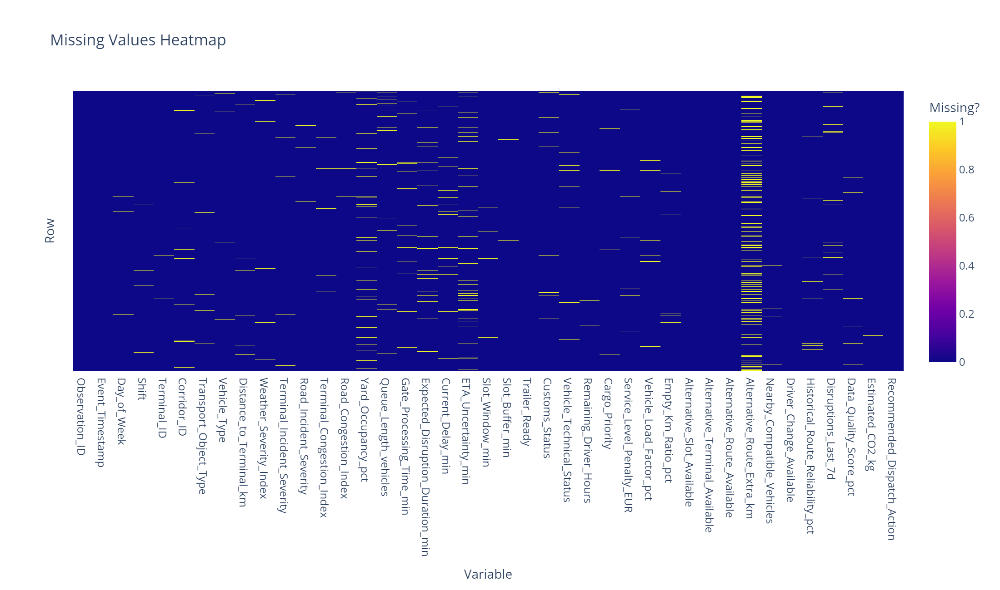

In [14]:
if df.isna().sum().sum() == 0:
    print("No missing values found in the dataset.")
else:
    # Sample rows only when necessary to keep the interactive heatmap responsive.
    heatmap_df = df
    if len(df) > MISSING_HEATMAP_MAX_ROWS:
        heatmap_df = df.sample(MISSING_HEATMAP_MAX_ROWS, random_state=42)
        print(
            f"Heatmap uses a random sample of {MISSING_HEATMAP_MAX_ROWS:,} rows "
            f"from {len(df):,} total rows."
        )

    # Plotly displays 1 for missing and 0 for present.
    missing_matrix = heatmap_df.isna().astype(int)

    fig = px.imshow(
        missing_matrix,
        aspect="auto",
        labels={"x": "Variable", "y": "Row", "color": "Missing?"},
        title="Missing Values Heatmap",
    )
    fig.update_yaxes(showticklabels=False)
    fig.update_layout(height=500)
    show_plotly(fig)


### 2.7 Interactive bar chart of missing values

This chart focuses only on columns that actually contain missing values. Hover over each bar to see the exact count.

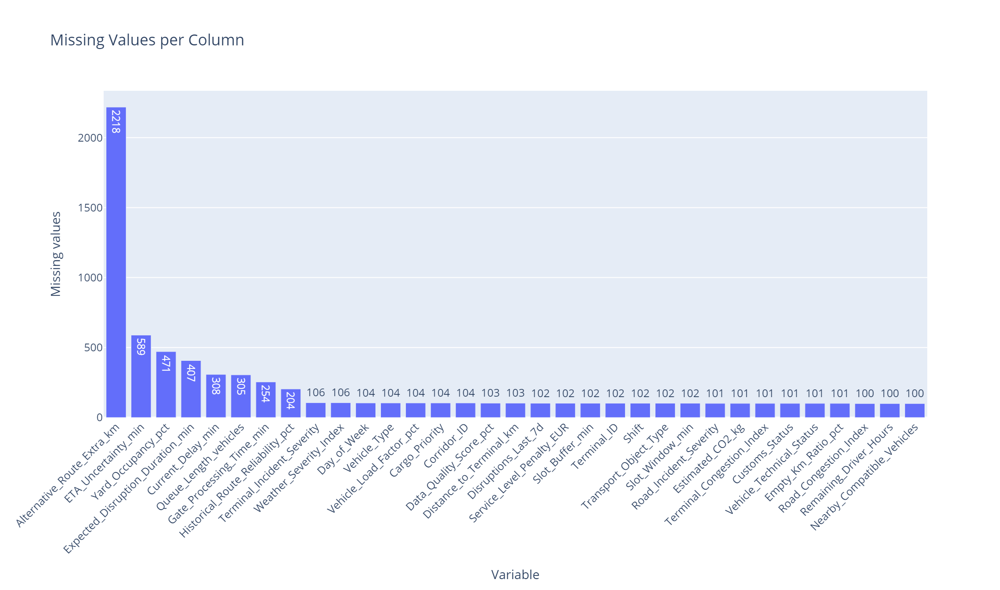

In [15]:
missing_counts = df.isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

if missing_counts.empty:
    print("No missing values found in the dataset.")
else:
    missing_plot_df = missing_counts.rename("Missing values").reset_index()
    missing_plot_df.columns = ["Variable", "Missing values"]

    fig = px.bar(
        missing_plot_df,
        x="Variable",
        y="Missing values",
        title="Missing Values per Column",
        text="Missing values",
    )
    fig.update_layout(xaxis_tickangle=-45)
    show_plotly(fig)


remark:
- `Alternative_Route_Extra_km` has the highest number of missing values (2,218), followed by `ETA_Uncertainty_min` (585) and `Yard_Occupancy_pct` (471).
- The remaining columns have relatively low missingness (≤ 305), with a long tail of features showing minimal gaps (~100–106 values)

### 2.8 Interactive missingness dendrogram

This optional plot clusters **columns** with similar missing-value patterns. Hover and zoom make larger dendrograms easier to inspect. It is most meaningful when at least two variables contain missing values.

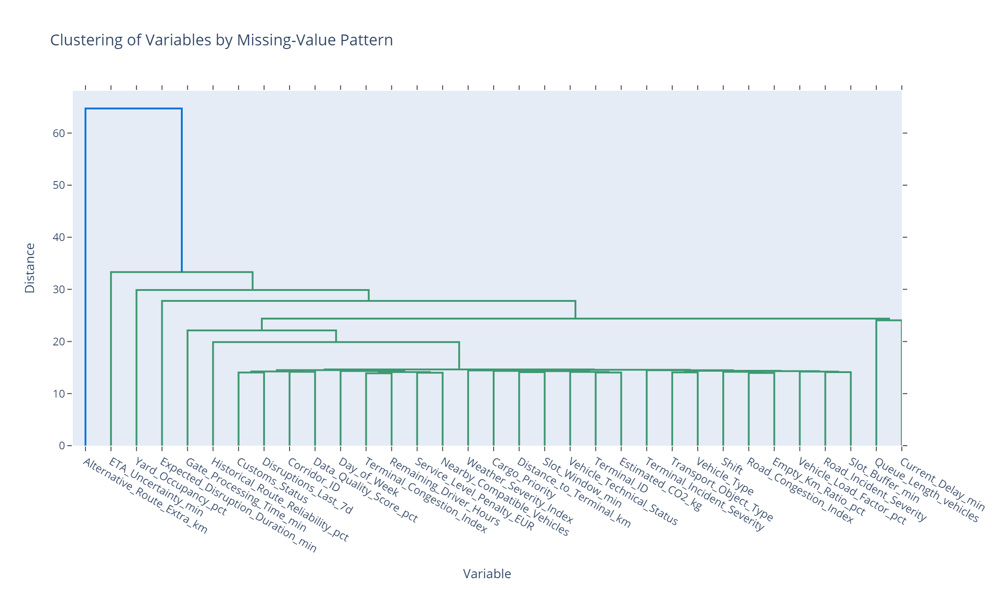

In [16]:
columns_with_missing = df.columns[df.isna().any()].tolist()

if len(columns_with_missing) < 2:
    print("At least two columns with missing values are needed for clustering.")
else:
    # Each row represents one dataset variable; each column represents an
    # observation. Variables with similar missingness patterns cluster together.
    missing_matrix = df[columns_with_missing].isna().astype(int).T

    fig = ff.create_dendrogram(
        missing_matrix.values,
        labels=columns_with_missing,
        linkagefun=lambda x: hierarchy.linkage(x, method="ward"),
    )
    fig.update_layout(
        title="Clustering of Variables by Missing-Value Pattern",
        xaxis_title="Variable",
        yaxis_title="Distance",
        height=500,
    )
    show_plotly(fig)


## 3. Step 2 — Check data quality

EDA should identify potential issues **before** changing the data. In a teaching template, we therefore detect duplicates and unusual cardinalities but do not automatically delete rows or columns.


### 3.1 Duplicate rows


In [17]:
number_of_duplicates = df.duplicated().sum()
percentage_duplicates = 100 * number_of_duplicates / len(df) if len(df) else 0

print(f"Duplicate rows: {number_of_duplicates:,}")
print(f"Percentage of dataset: {percentage_duplicates:.2f}%")


Duplicate rows: 196
Percentage of dataset: 1.91%


Remark (Duplicate rows):
- Number of duplicate rows is 196, which confirms our initial observation from the describe() function

### 3.2 Unique values per column

This is helpful for detecting ID-like variables, binary flags, and categorical columns stored as numbers.


In [18]:
unique_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "unique_values": df.nunique(dropna=False),
})
unique_summary["unique_percent"] = unique_summary["unique_values"] / len(df) * 100

display(unique_summary.sort_values("unique_values"))


,dtype,unique_values,unique_percent
Alternative_Slot_Available,bool,2,0.020
Alternative_Terminal_Available,bool,2,0.020
Trailer_Ready,bool,2,0.020
Alternative_Route_Available,bool,2,0.020
Driver_Change_Available,bool,2,0.020
Cargo_Priority,float64,4,0.039
Customs_Status,object,4,0.039
Transport_Object_Type,object,4,0.039
Vehicle_Technical_Status,object,4,0.039
Slot_Window_min,float64,5,0.049


# Remark (Unique values count):
## Note that the dropna=False therefore the NaN values are also counted as unique values, therefore the true count of unique values (excluding the NaN as a unique value) is retrieved from the output of the describe function previously in 2.4 Descriptive statistics

# Remark (Data Types based on level of measurement of data):

. Nominal variables: "Observation_ID", "Day_of_Week", "Shift", "Terminal_ID", "Corridor_ID", "Transport_Object_Type", "Vehicle_Type", "Trailer_Ready", "Customs_Status", "Alternative_Slot_Available", "Alternative_Terminal_Available", "Alternative_Route_Available", "Driver_Change_Available", 

. Ordinal variables: "Vehicle_Technical_Status", "Cargo_Priority","Road_Incident_Severity","Terminal_Incident_Severity"

. Interval variables: "Event_Timestamp", "Slot_Buffer_min"

. Ratio variables: "Distance_to_Terminal_km", "Weather_Severity_Index", "Terminal_Congestion_Index", "Road_Congestion_Index", "Yard_Occupancy_pct", "Queue_Length_vehicles", "Gate_Processing_Time_min", "Expected_Disruption_Duration_min", "Current_Delay_min", "ETA_Uncertainty_min", "Slot_Window_min", "Remaining_Driver_Hours", "Service_Level_Penalty_EUR", "Vehicle_Load_Factor_pct", "Empty_Km_Ratio_pct", "Alternative_Route_Extra_km", "Nearby_Compatible_Vehicles", "Historical_Route_Reliability_pct", "Disruptions_Last_7d", "Data_Quality_Score_pct", "Estimated_CO2_kg"

.TARGET_column: "Recommended_Dispatch_Action"

> **Student checkpoint:** Which variables appear to be identifiers? Which variables could be converted to categorical data? Are any ranges impossible from a supply-chain or business perspective?


answer to student checkpoint:

**1. Which variables appear to be identifiers?**
- **`Observation_ID`**: A unique sequential number for each row (ranging from 1 to 10,000). It should be dropped before modeling.
- **`Event_Timestamp`**: A datetime stamp. While not a traditional ID, it uniquely tracks the exact time of the decision and should be transformed (e.g., extracted into hour, month) rather than used as a raw numeric feature.

**2. Which variables could be converted to categorical data?**
- **`Day_of_Week` and `Shift`**: Already categorical, but `Day_of_Week` shows 35 unique values, indicating potential inconsistencies (e.g., typos, abbreviations, or a mismatch with the feature dictionary which states Mon–Sun).
- **`Slot_Window_min`**: Although currently numerical, it only takes four discrete values (30, 45, 60, 90) and represents distinct business categories.
- **Ordinal / Integer Severity Scores**: `Terminal_Incident_Severity`, `Road_Incident_Severity`, and `Cargo_Priority` have very few unique integer values (0-3 or 1-3) and represent distinct classes or levels rather than continuous measurements.
- **`Nearby_Compatible_Vehicles` and `Disruptions_Last_7d`**: These are small, bounded count variables (maxing out at 12) that could be treated as discrete categories if non-linear relationships are expected.

**3. Are any ranges impossible from a supply-chain or business perspective?**
Comparing the observed ranges against the feature dictionary and real-world logistics:
- **`Day_of_Week` (35 unique values)**: **Impossible.** A week only has 7 days. The data contains dirty entries or inconsistent formatting. 
- **`Yard_Occupancy_pct` (Max: 100.000)**: **Physically impossible/highly improbable.** While a yard can theoretically hit 100%, in real-world operations, 100% occupancy means the terminal is completely gridlocked and cannot accept new vehicles. A max of 100.0 suggests synthetic data generation or data capping.
- **`Remaining_Driver_Hours` (Min: 0.250)**: **Unrealistic from a safety perspective.** A driver with only 15 minutes (0.25 hours) of remaining legal driving time should not be dispatched to a terminal, especially with `Distance_to_Terminal_km` showing a median of 54 km.
- **`Vehicle_Load_Factor_pct` (Max: 100.0)**: **Slightly suspicious.** A max of exactly 100.0% is rare in weight/volume utilization but possible depending on how the metric is calculated.
- **`ETA_Uncertainty_min` (Min: 3.0)**: **Questionable.** Having an uncertainty of only 3 minutes for a logistics operation (which involves traffic, gate queues, and weather) is extremely optimistic, suggesting highly synthetic data.
- **`Alternative_Route_Extra_km` (Min: 0.0)**: **Logically inconsistent.** If an alternative route has 0 extra kilometers, it is functionally identical to the primary route. A true alternative route should add some distance.
- **`Slot_Buffer_min` (Min: -180.000)**: **Extreme but possible.** A negative buffer of -180 minutes means the vehicle is 3 hours past its slot deadline. While possible in severe disruptions, it is an extreme outlier given the median buffer is +43 minutes. 
- **Missingness Check**: `Alternative_Route_Extra_km` has 2,218 missing values. This aligns perfectly with `Alternative_Route_Available` showing 2,218 "False" values (10,250 - 8,032), which is logically consistent.

# Fixing Data Quality issues(Inconsistency)

In [19]:
df['Shift'] = (
    df['Shift'].astype('string')
      .str.strip()               # removes ' Day' → 'Day'
      .str.lower()               # 'EVENING' → 'evening'
      .replace({
          'day': 'Day',
          'evening': 'Evening',
          'night': 'Night',
      })
      .astype('category')
)
def clean_vehicle_type(s):
    return (
        s.astype('string')
         .str.strip()                                # trim edges
         .str.lower()                                # unify case
         .str.replace(r'[\s\-]+', '_', regex=True)   # space/hyphen → underscore
         .str.replace(r'_+', '_', regex=True)        # collapse repeats
         .replace({
             'tractor_unit':    'Tractor_Unit',
             'rigid_truck':     'Rigid_Truck',
             'swap_body_truck': 'Swap_Body_Truck',
         })
         .astype('category')
    )

df['Vehicle_Type'] = clean_vehicle_type(df['Vehicle_Type'])

# Canonical map — covers abbreviated, full, and case variants
DAY_MAP = {
    # Monday
    'mon': 'Monday', 'monday': 'Monday', 'mon.': 'Monday',
    # Tuesday
    'tue': 'Tuesday', 'tues': 'Tuesday', 'tuesday': 'Tuesday', 'tue.': 'Tuesday',
    # Wednesday
    'wed': 'Wednesday', 'weds': 'Wednesday', 'wednesday': 'Wednesday', 'wed.': 'Wednesday',
    # Thursday
    'thu': 'Thursday', 'thur': 'Thursday', 'thurs': 'Thursday',
    'thursday': 'Thursday', 'thu.': 'Thursday',
    # Friday
    'fri': 'Friday', 'friday': 'Friday', 'fri.': 'Friday',
    # Saturday
    'sat': 'Saturday', 'saturday': 'Saturday', 'sat.': 'Saturday',
    # Sunday
    'sun': 'Sunday', 'sunday': 'Sunday', 'sun.': 'Sunday',
}

df['Day_of_Week'] = (
    df['Day_of_Week']
      .astype('string')
      .str.strip()                              # 'Thu ' → 'Thu'
      .str.replace(r'\s+', ' ', regex=True)     # collapse internal whitespace
      .str.rstrip('.,')                         # remove trailing period/comma
      .str.lower()                              # 'THU' → 'thu'
      .map(DAY_MAP)                             # 'thu' → 'Thursday'
      .astype('category')
)

remark: 
- here, i maped all the inconsistent values(35 different values) of 'Day_of_Week' to the normal distinct 7 days values (Monday-Sunday)
- Same for 'Shift' to 3 logical  distinct values (Night,Evening,Day)
- Same for 'Vehicle_Type' to 3 distinct values that normally should exist (Rigid_Truck,Tractor_Unit,Swap_Body_Truck)

## 4. Step 3 — Understand each variable (univariate analysis)

Univariate analysis studies **one variable at a time**. We treat categorical and numerical variables differently because their distributions require different summaries and plots.


### 4.1 Categorical variables

The next cell displays frequency tables. High-cardinality variables are still summarized, but only the most common categories are shown.


In [20]:
# --- Semantic column roles (independent of storage dtype) ---
NOMINAL = [
    'Day_of_Week', 'Shift', 'Terminal_ID', 'Corridor_ID',
    'Transport_Object_Type', 'Vehicle_Type', 'Trailer_Ready',
    'Customs_Status', 'Alternative_Slot_Available',
    'Alternative_Terminal_Available', 'Alternative_Route_Available',
    'Driver_Change_Available',
]
# Observation_ID deliberately excluded — it's an identifier, not a real category.
ORDINAL = ['Vehicle_Technical_Status', 'Cargo_Priority','Terminal_Incident_Severity','Road_Incident_Severity']
#

categorical_plot_columns = [c for c in NOMINAL + ORDINAL if c in df.columns]

if not categorical_plot_columns:
    print("No categorical variables detected.")
else:
    for col in categorical_plot_columns:
        print(f"\n--- {col} ---")
        counts = df[col].value_counts(dropna=False).head(15)
        display(counts.to_frame(name="count"))


--- Day_of_Week ---


,count
Day_of_Week,
Tuesday,1506
Sunday,1467
Wednesday,1454
Saturday,1454
Thursday,1440
Monday,1430
Friday,1395
NaN,104



--- Shift ---


,count
Shift,
Evening,3405
Day,3372
Night,3371
<NA>,102



--- Terminal_ID ---


,count
Terminal_ID,
T1,3248
T2,2780
T3,2282
T4,1838
NaN,102



--- Corridor_ID ---


,count
Corridor_ID,
C2,2263
C1,2251
C3,2014
C4,1868
C5,1750
NaN,104



--- Transport_Object_Type ---


,count
Transport_Object_Type,
Trailer,4634
Swap_Body,3181
Container,2333
NaN,102



--- Vehicle_Type ---


,count
Vehicle_Type,
Tractor_Unit,6130
Swap_Body_Truck,2569
Rigid_Truck,1447
<NA>,104



--- Trailer_Ready ---


,count
Trailer_Ready,
True,9534
False,716



--- Customs_Status ---


,count
Customs_Status,
Cleared,8265
Pending,1452
Hold,432
NaN,101



--- Alternative_Slot_Available ---


,count
Alternative_Slot_Available,
True,5578
False,4672



--- Alternative_Terminal_Available ---


,count
Alternative_Terminal_Available,
False,5933
True,4317



--- Alternative_Route_Available ---


,count
Alternative_Route_Available,
True,8032
False,2218



--- Driver_Change_Available ---


,count
Driver_Change_Available,
False,5753
True,4497



--- Vehicle_Technical_Status ---


,count
Vehicle_Technical_Status,
OK,9229
Warning,751
Critical,169
NaN,101



--- Cargo_Priority ---


,count
Cargo_Priority,
1.000,6194
2.000,2704
3.000,1248
NaN,104



--- Terminal_Incident_Severity ---


,count
Terminal_Incident_Severity,
0.000,8701
1.000,880
2.000,440
3.000,123
NaN,106



--- Road_Incident_Severity ---


,count
Road_Incident_Severity,
0.000,8894
1.000,841
2.000,308
3.000,106
NaN,101


#### Interactive frequency bar charts

A frequency bar chart answers: **How many observations belong to each category?** Hover over the bars for exact frequencies. The template shows the 15 most frequent categories so high-cardinality variables remain readable.

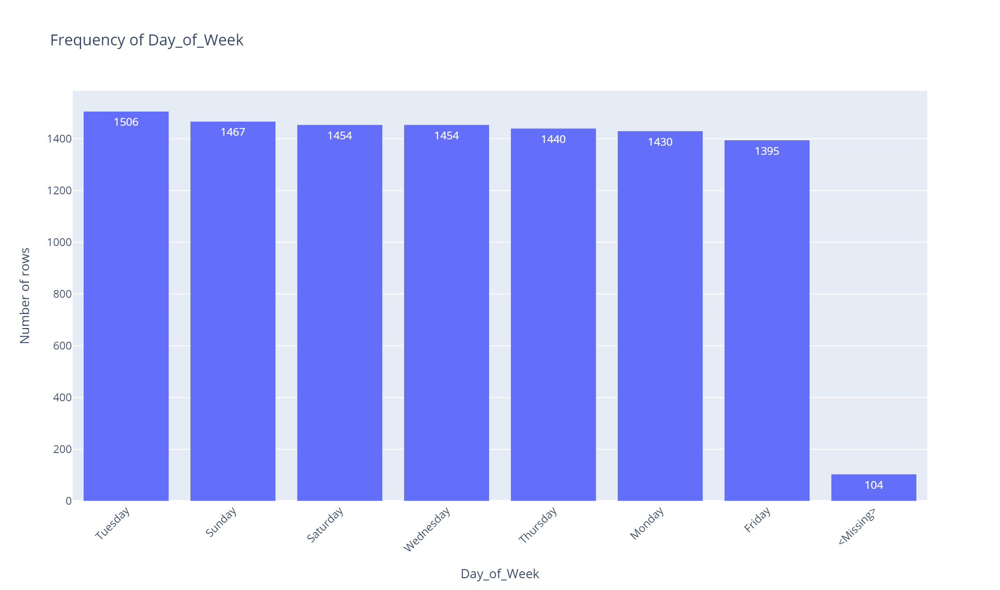

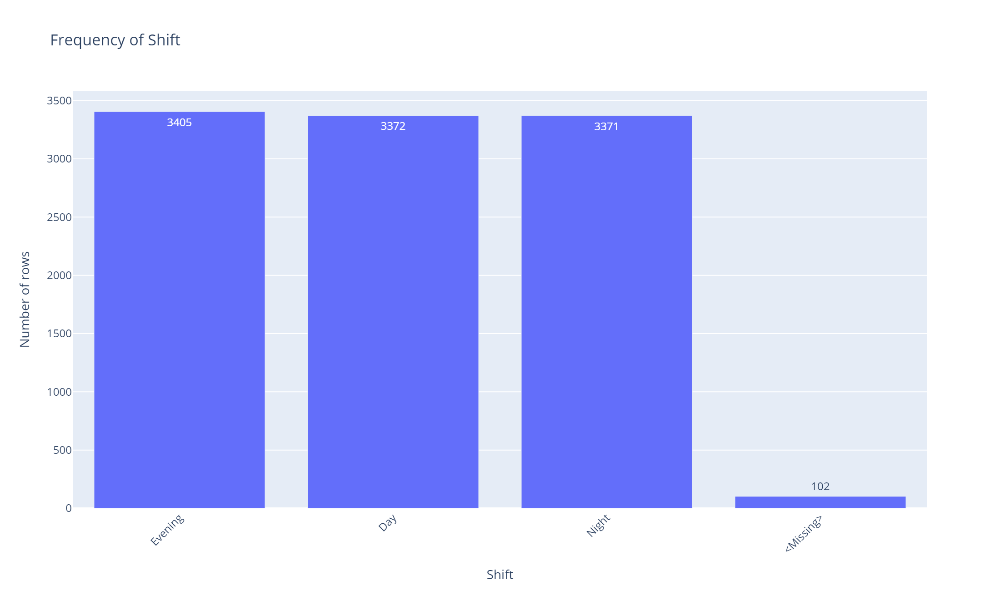

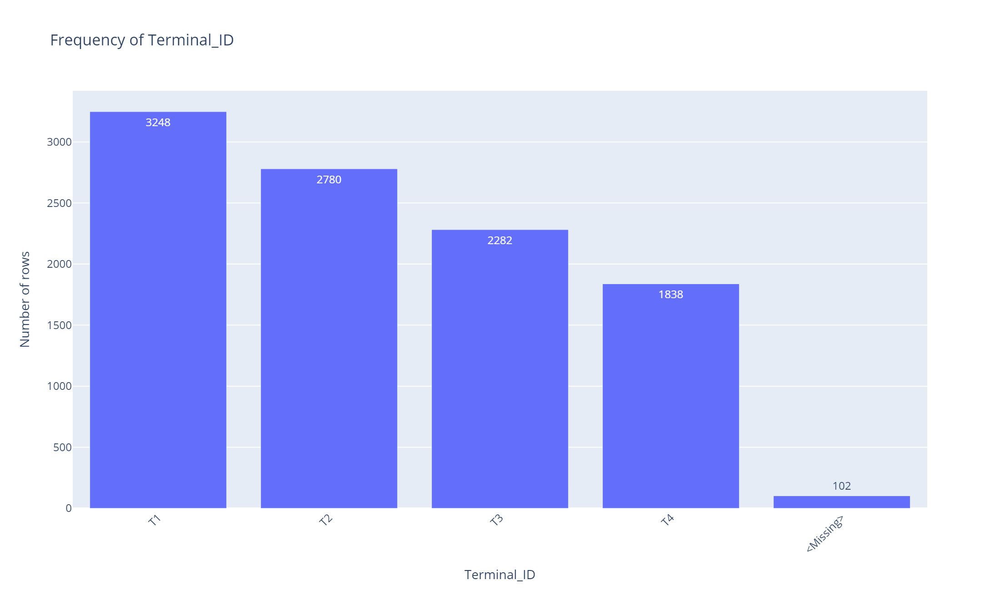

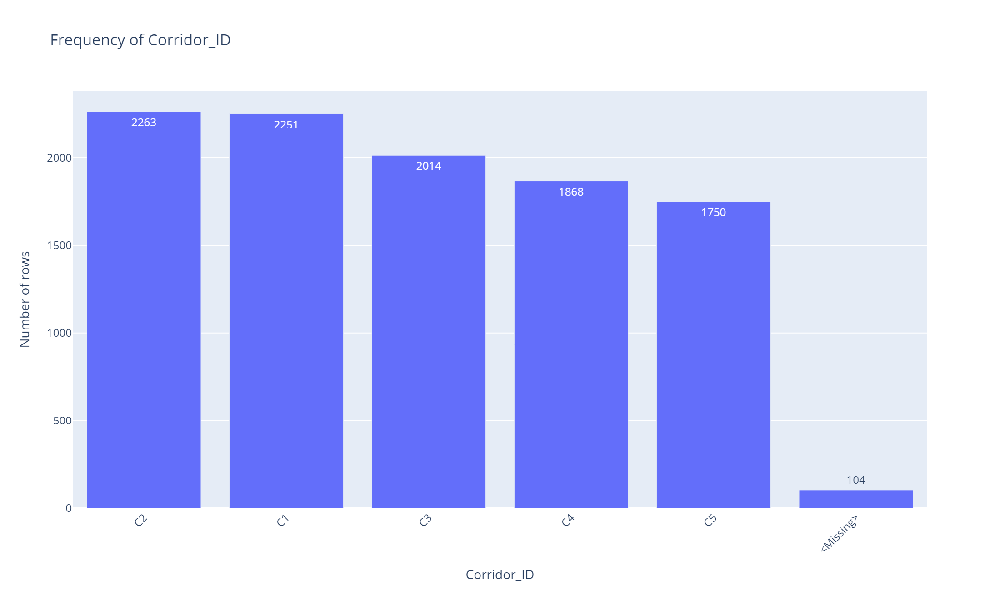

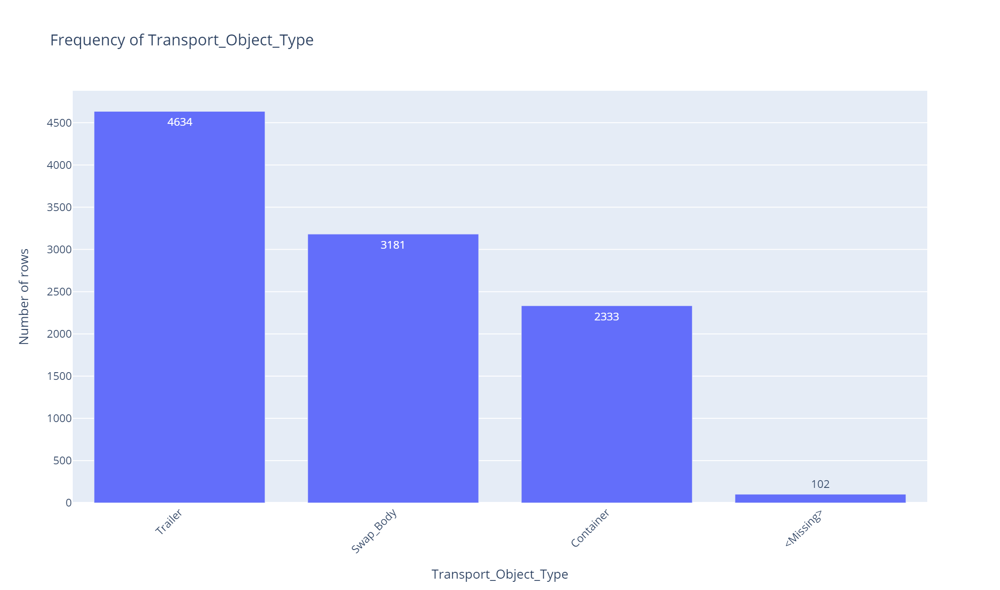

...

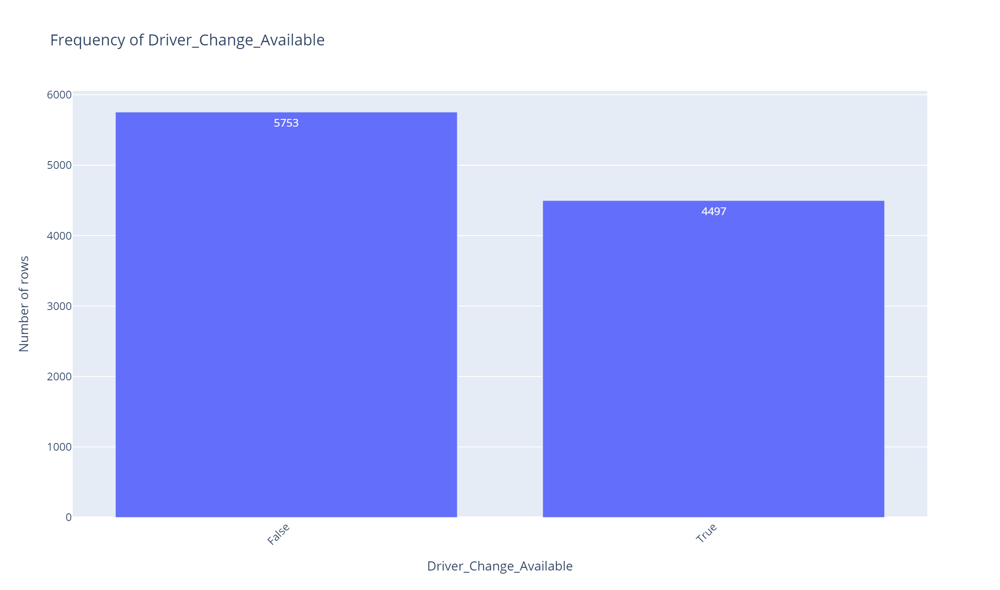

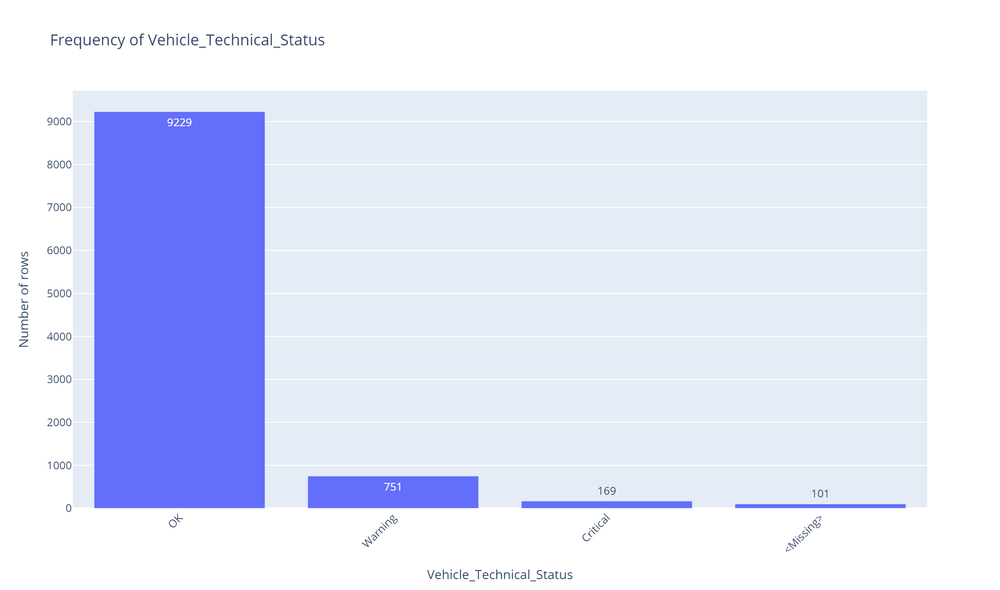

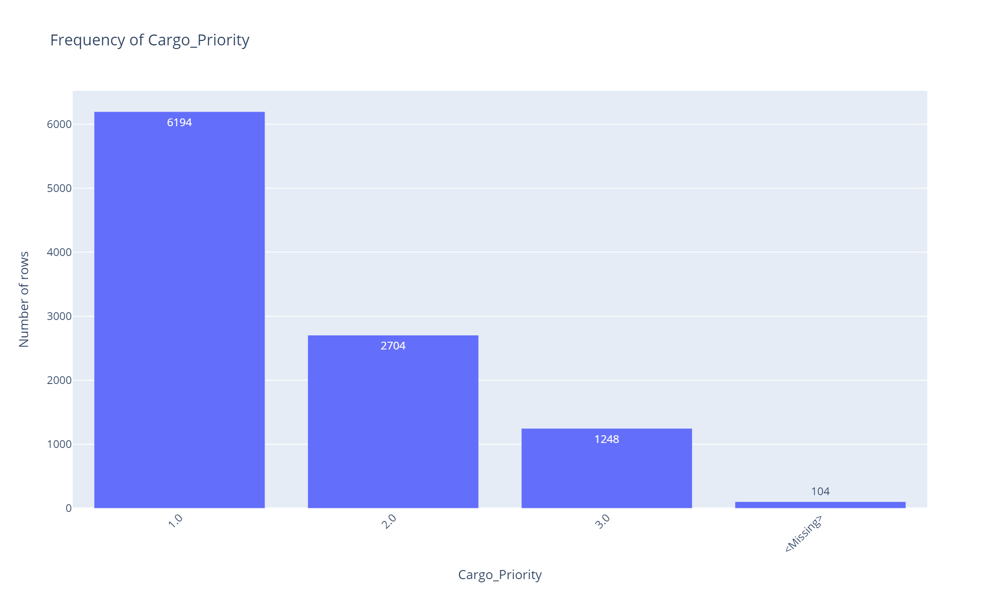

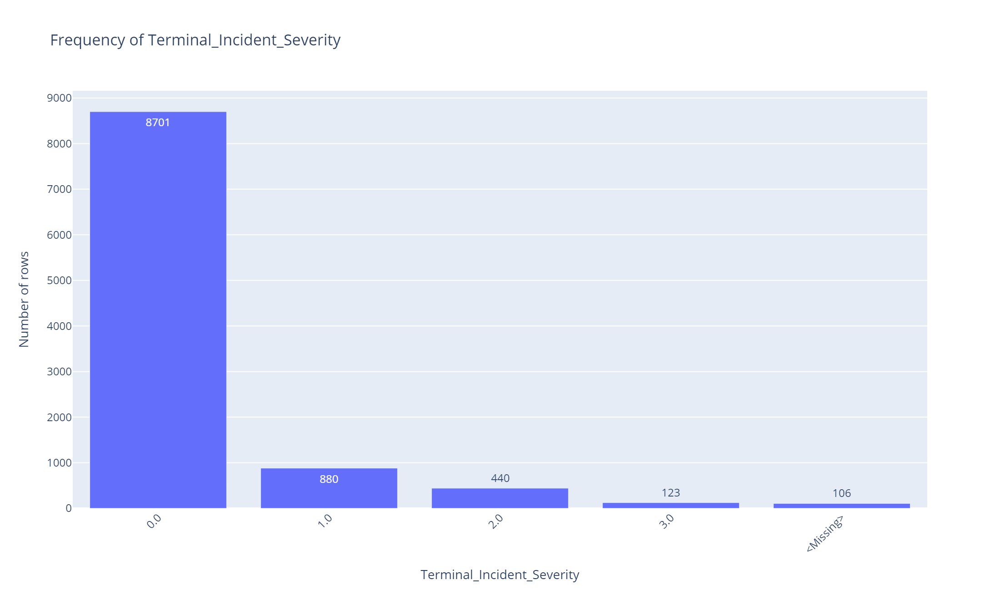

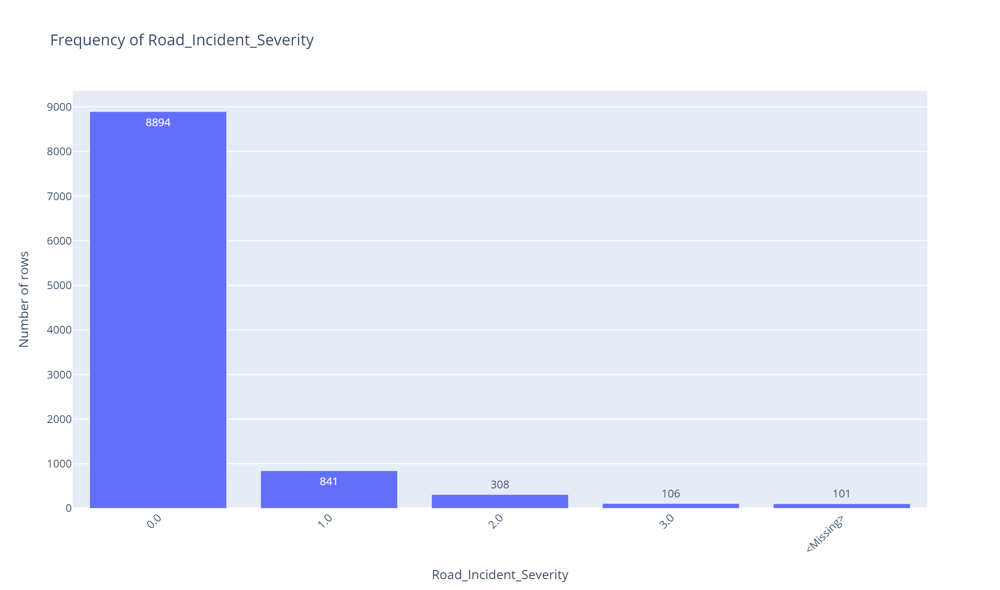

In [21]:
# Plot an interactive frequency bar chart for each selected categorical variable.
if not categorical_plot_columns:
    print("No categorical variables detected.")
else:
    for col in categorical_plot_columns:
        # Convert values to pandas' string type so both category dtype and
        # missing values are handled consistently.
        plot_series = df[col].astype("string").fillna("<Missing>")

        # Count categories and keep the 15 most frequent for readability.
        counts = plot_series.value_counts().head(15)
        counts_df = counts.rename("Frequency").reset_index()
        counts_df.columns = ["Category", "Frequency"]

        fig = px.bar(
            counts_df,
            x="Category",
            y="Frequency",
            title=f"Frequency of {col}",
            text="Frequency",
            labels={"Category": col, "Frequency": "Number of rows"},
        )
        fig.update_layout(xaxis_tickangle=-45)
        show_plotly(fig)


insights:
- **Highly Skewed**: `Trailer_Ready`, `Customs_Status`, and `Vehicle_Technical_Status` are overwhelmingly dominated by their default states (True, Cleared, OK), meaning the minority classes represent rare edge cases.
- **Balanced/Near-Balanced**: `Shift`, `Terminal_ID`, `Corridor_ID`, and the `Alternative_*` availability flags show reasonably balanced splits, indicating good variance for the models to learn from.
- **Missing Data**: Every categorical feature has a consistent, small number of `<Missing>` values (roughly 100–104), which should be imputed or dropped.
- **Incident Severity**: Both `Terminal_Incident_Severity` and `Road_Incident_Severity` are heavily zero-inflated (mostly 0.0), confirming that severe disruptions are intentionally rare.

#### Interactive pie charts — only when the number of categories is small

Pie charts show **parts of a whole**, but they become difficult to interpret with many categories. This template therefore creates them only for variables with at most 10 categories. Hover over a slice for its count and percentage.

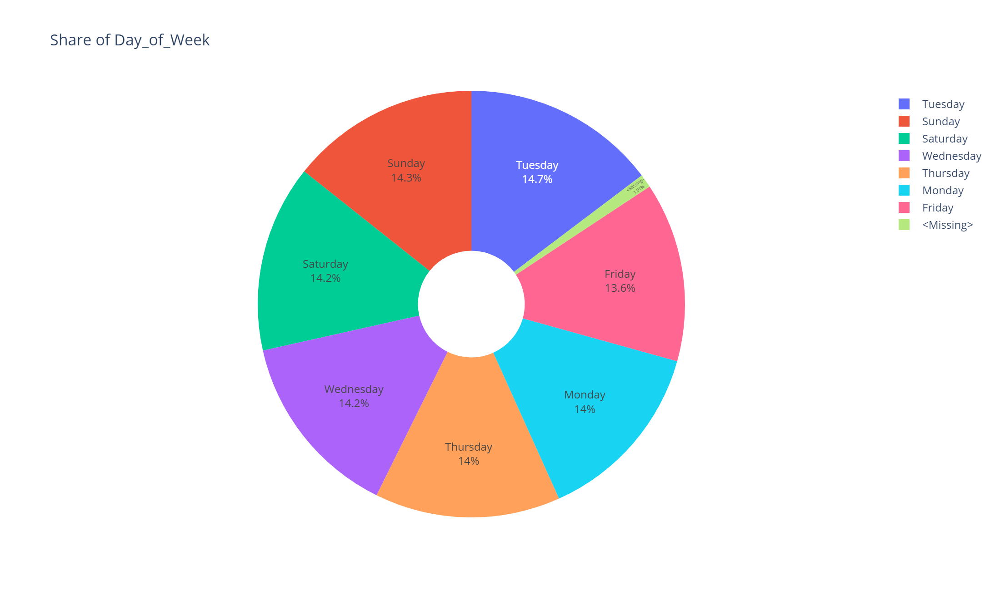

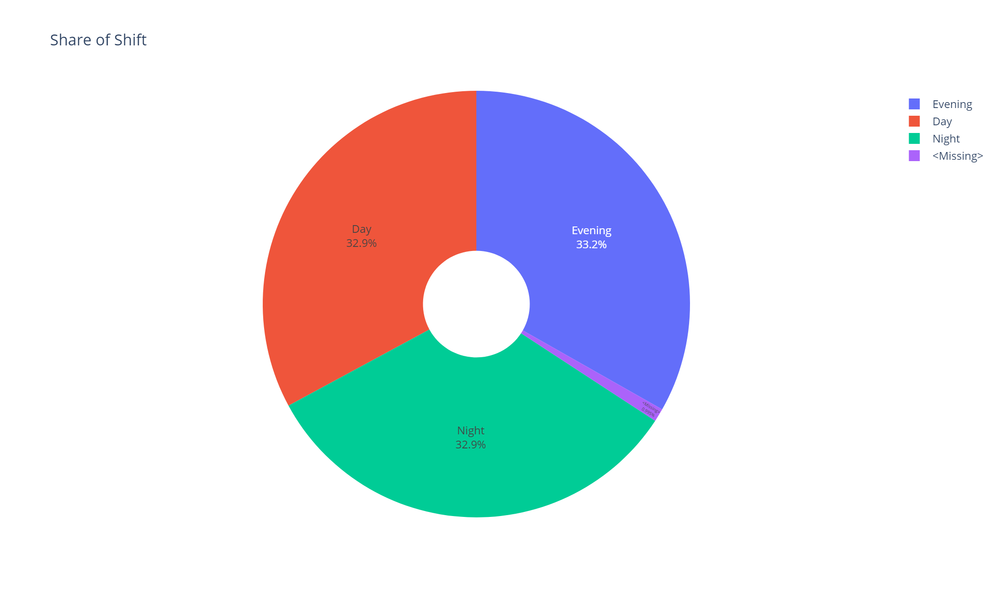

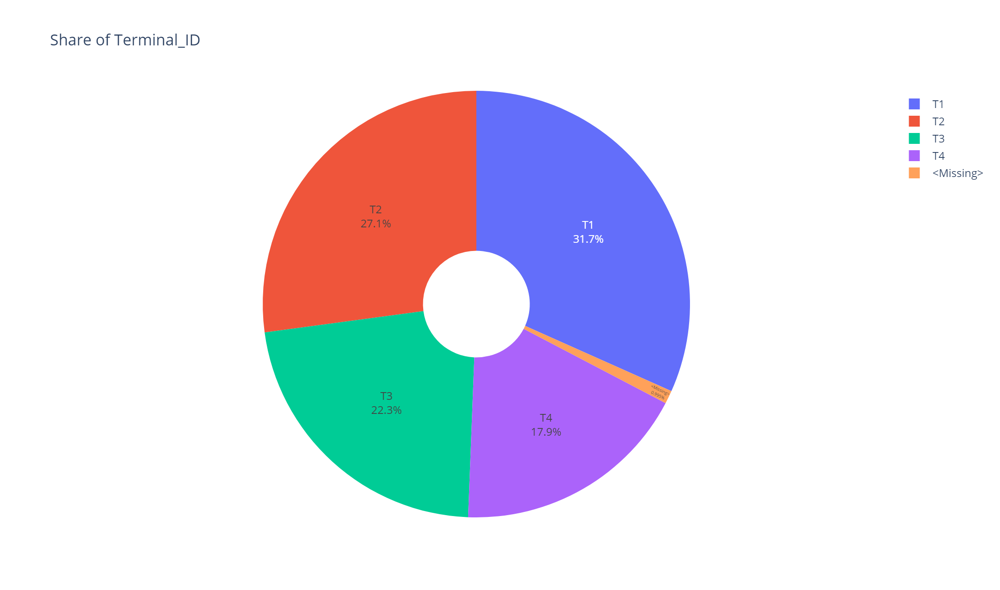

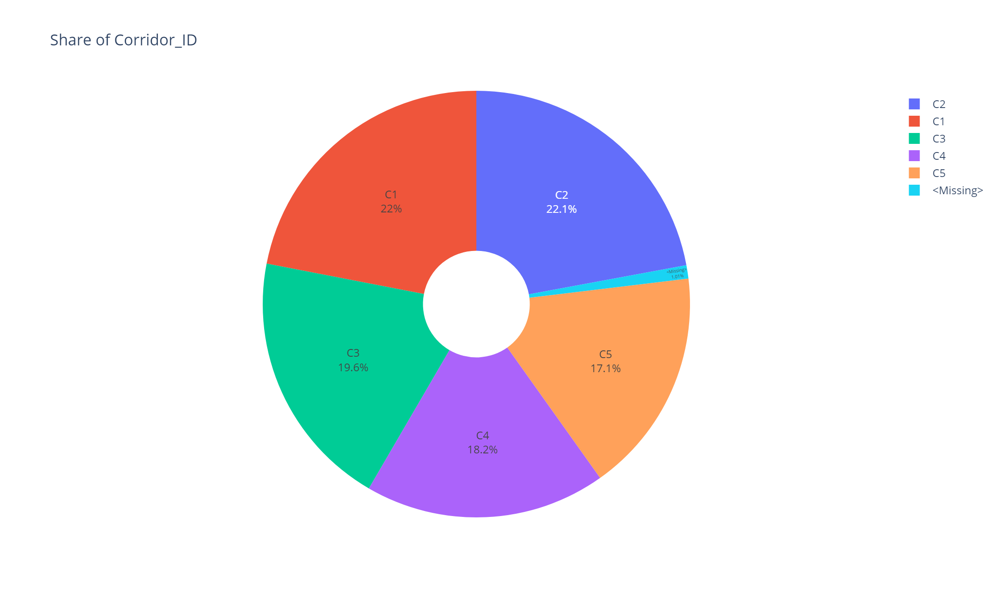

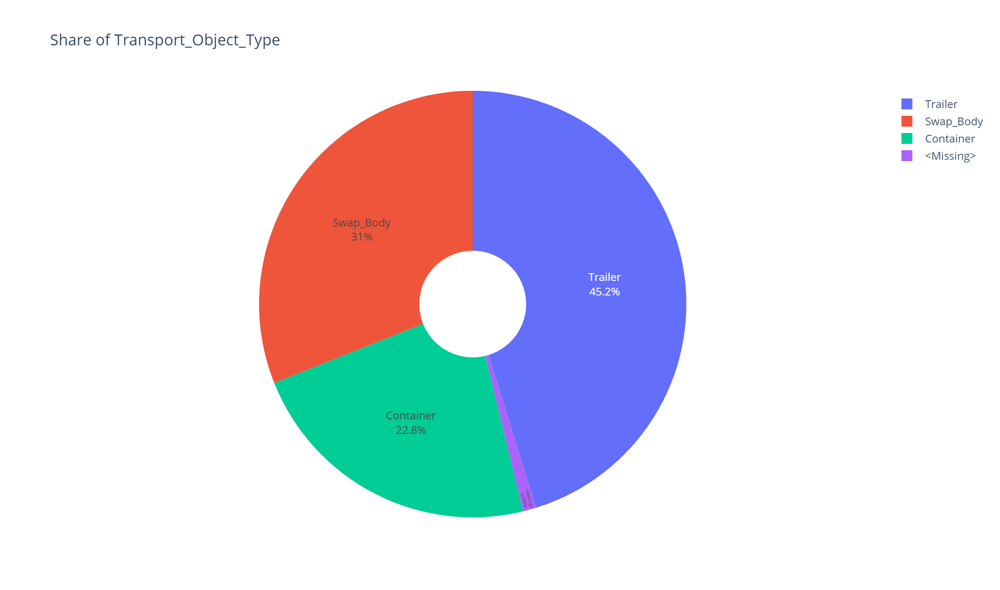

...

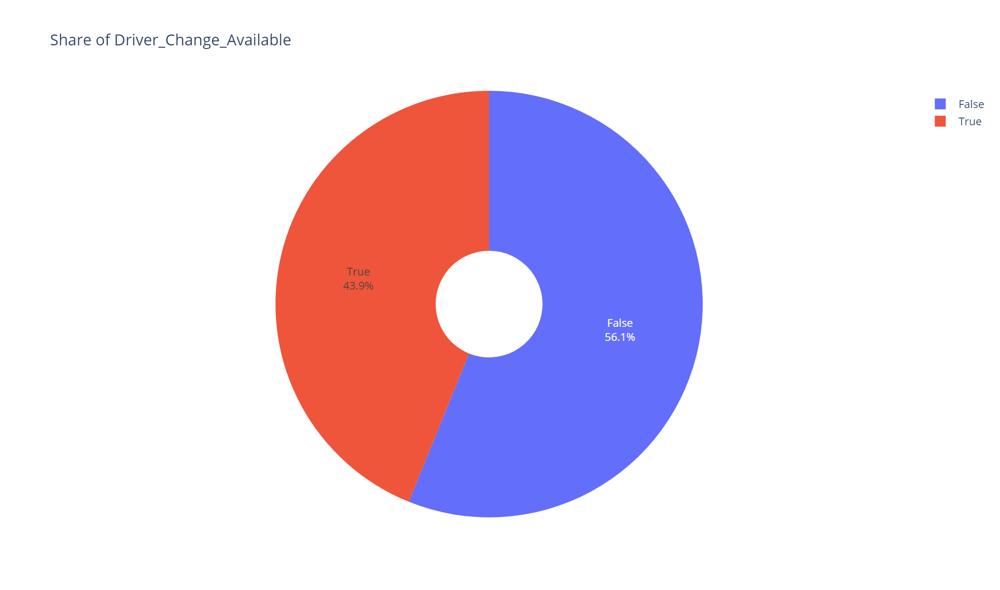

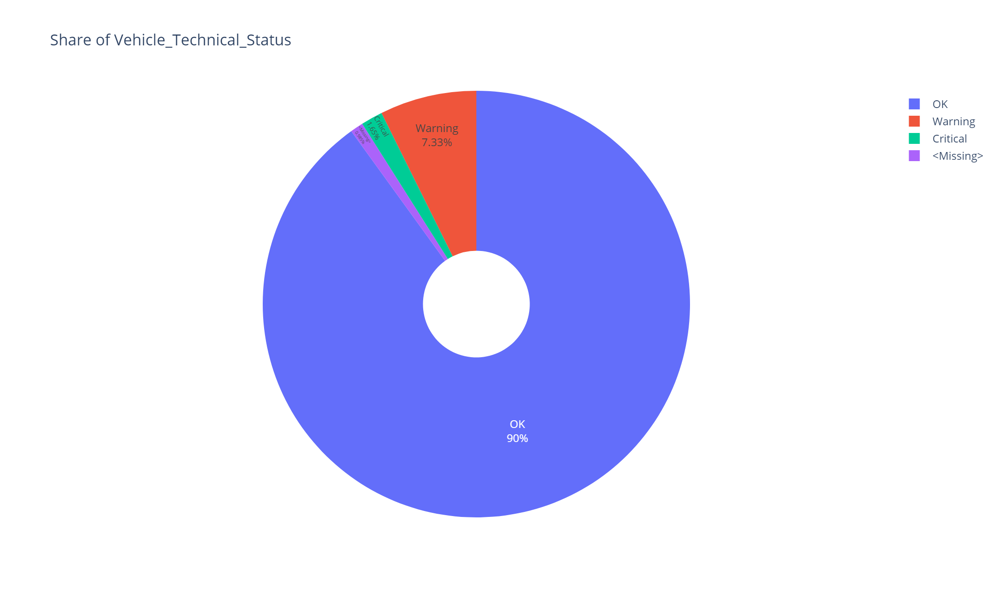

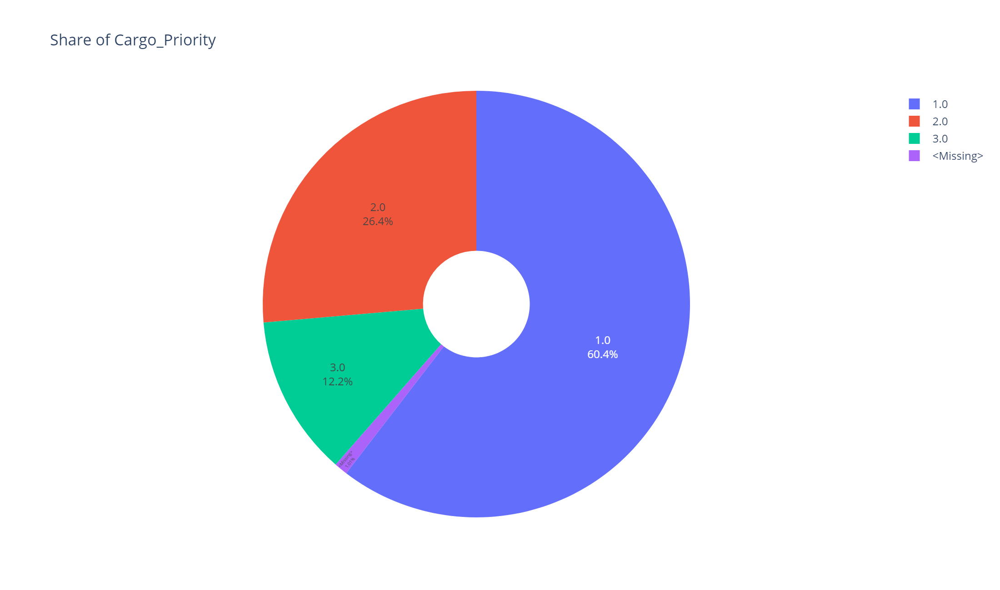

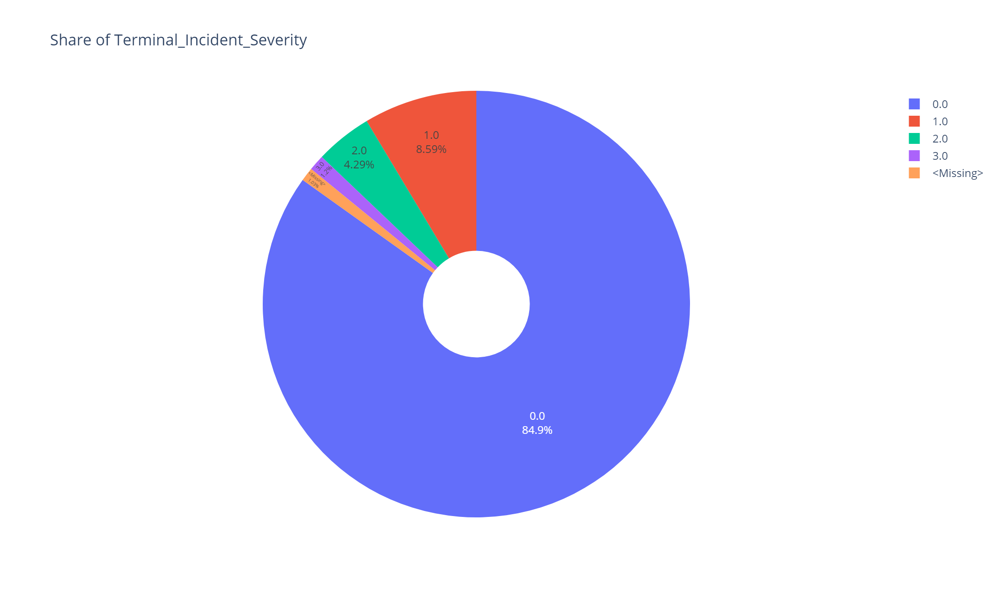

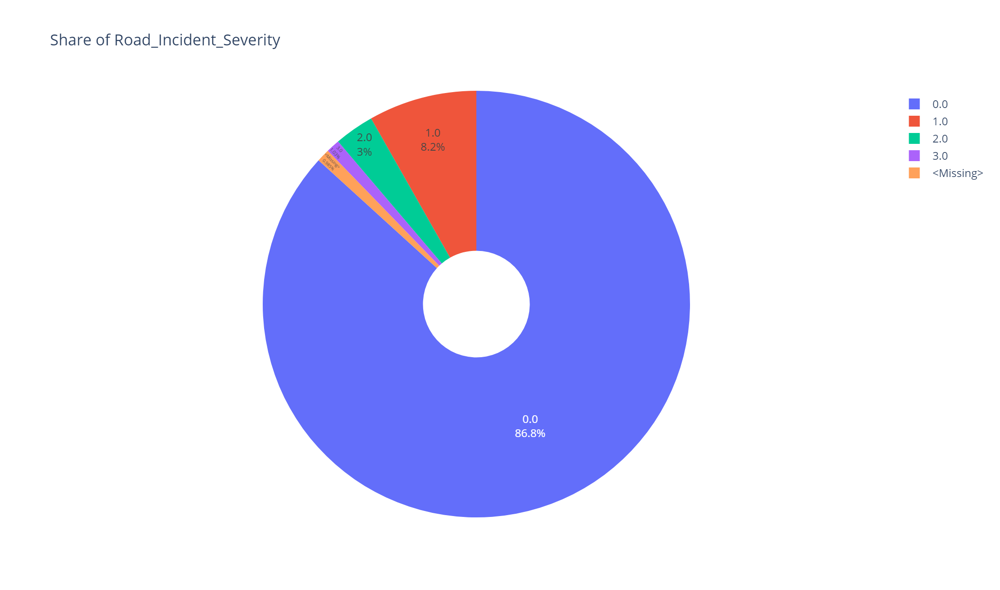

In [22]:
for col in categorical_plot_columns:
    plot_series = df[col].astype("string").fillna("<Missing>")
    number_of_categories = plot_series.nunique(dropna=False)

    if number_of_categories <= 10:
        counts = plot_series.value_counts()
        pie_df = counts.rename("Frequency").reset_index()
        pie_df.columns = ["Category", "Frequency"]

        fig = px.pie(
            pie_df,
            names="Category",
            values="Frequency",
            title=f"Share of {col}",
            hole=0.25,
        )
        fig.update_traces(textposition="inside", textinfo="percent+label")
        show_plotly(fig)
    else:
        print(
            f"Skipping pie chart for {col}: "
            f"{number_of_categories} categories would be difficult to read."
        )


remark:
- Pie charts convey the same previous insights as bar charts, but we just have percentages (ratios of distinct categories) instead of counts.
- For that reason, Note that here, pie charts for only columns with less than 10 distinct categories were plotted,
because normally pie charts with more than 10 categories become hard to interprete.

#### Interactive Pareto chart

A Pareto chart ranks categories by frequency and overlays the cumulative percentage. Hover over bars or the line to inspect exact values. This can help identify the "vital few" categories that account for most observations.

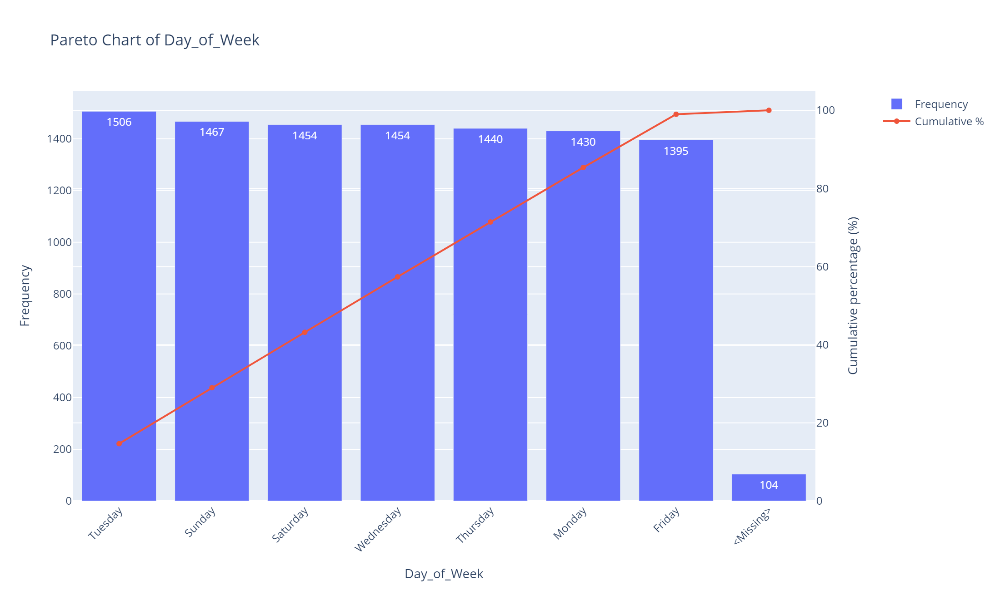

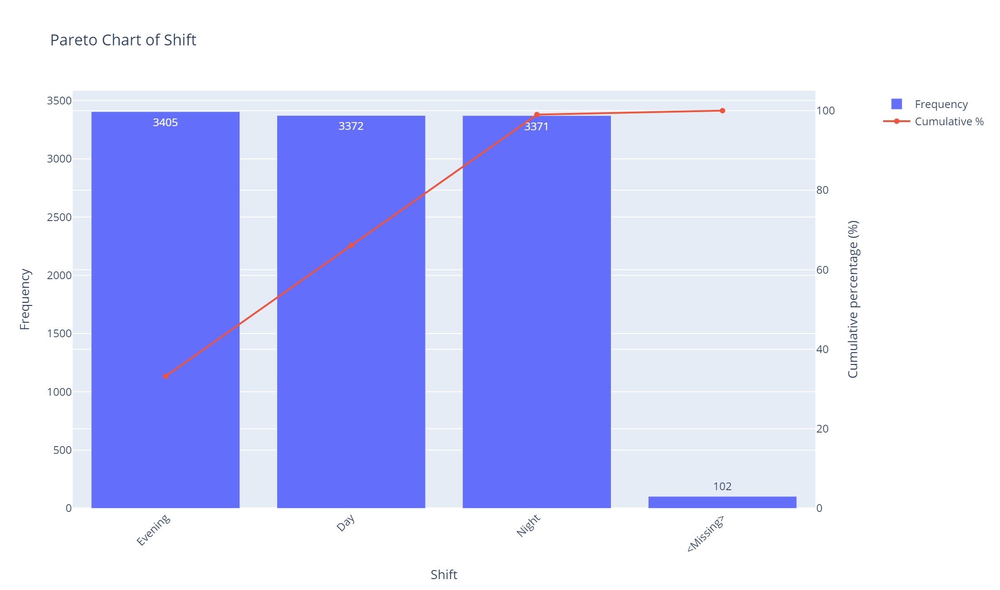

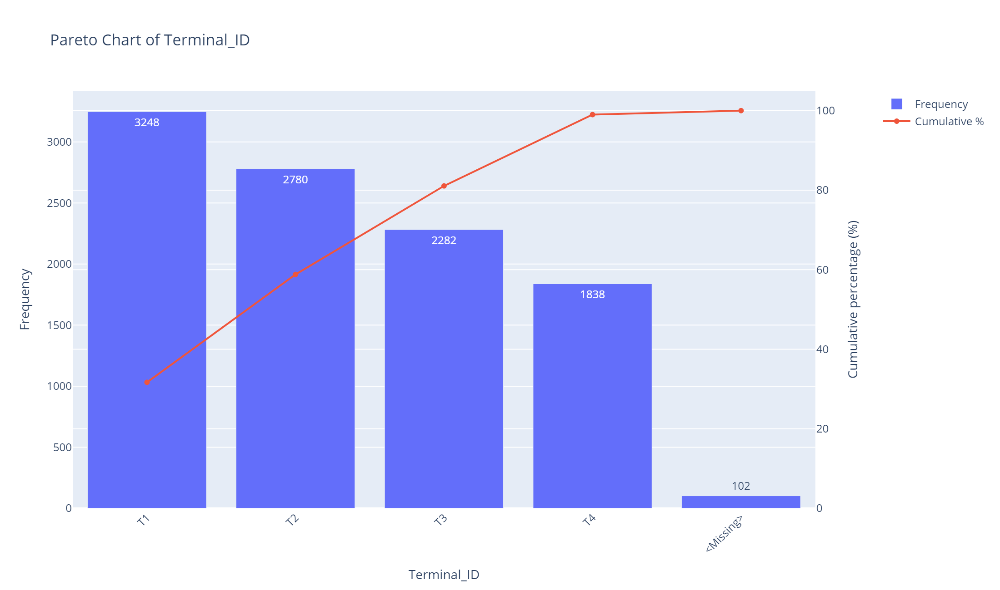

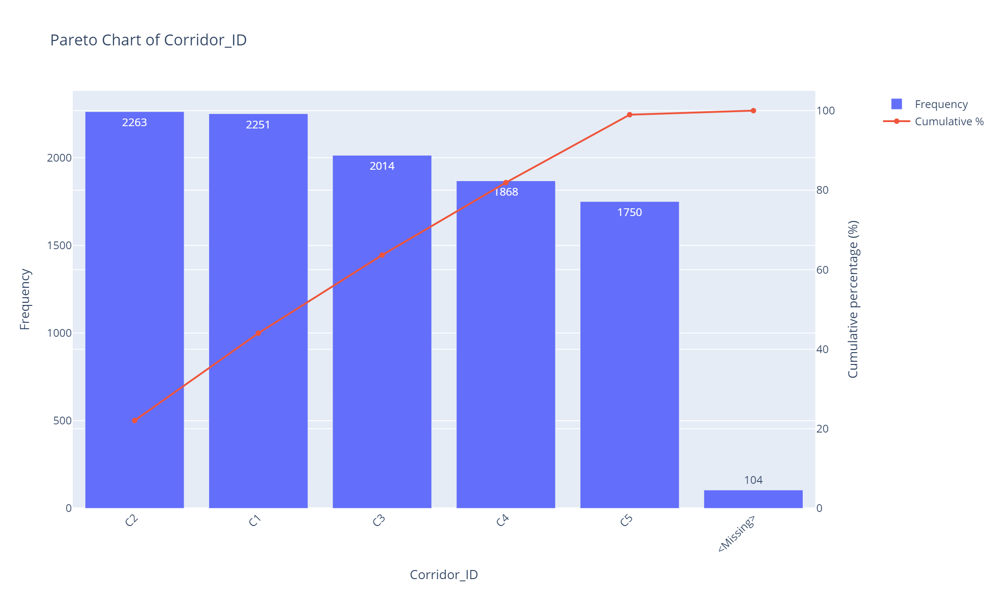

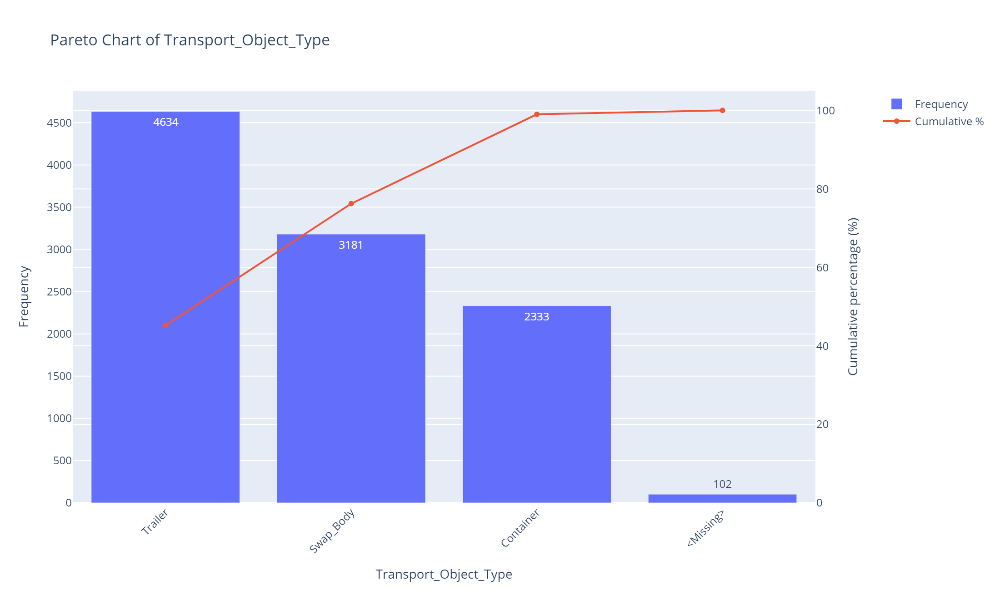

...

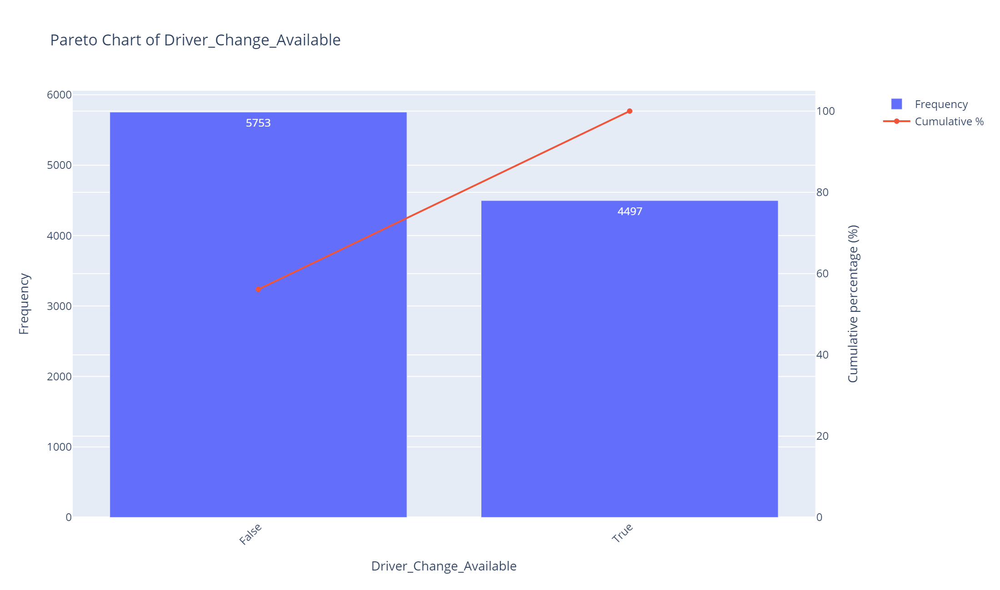

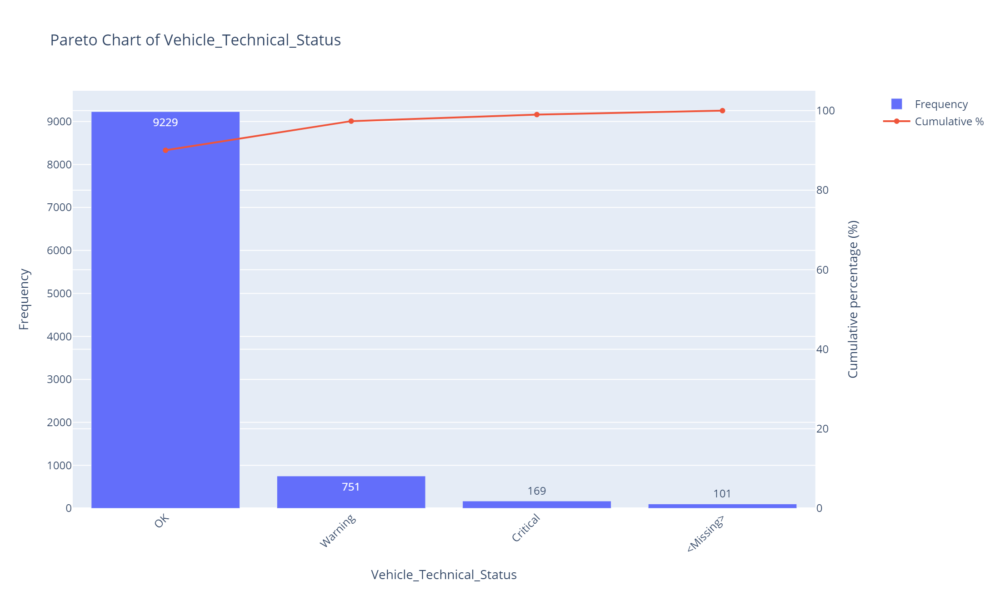

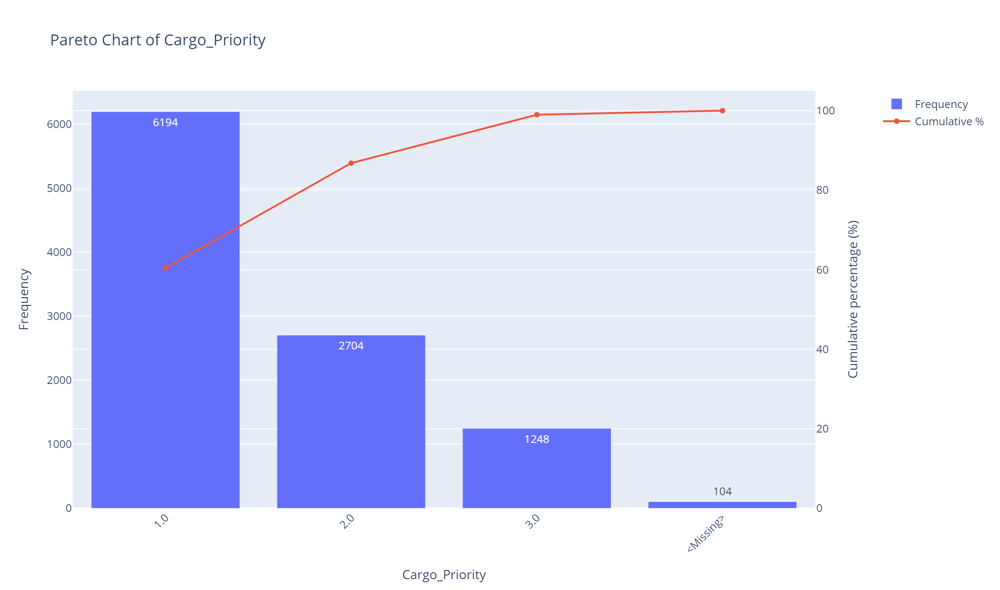

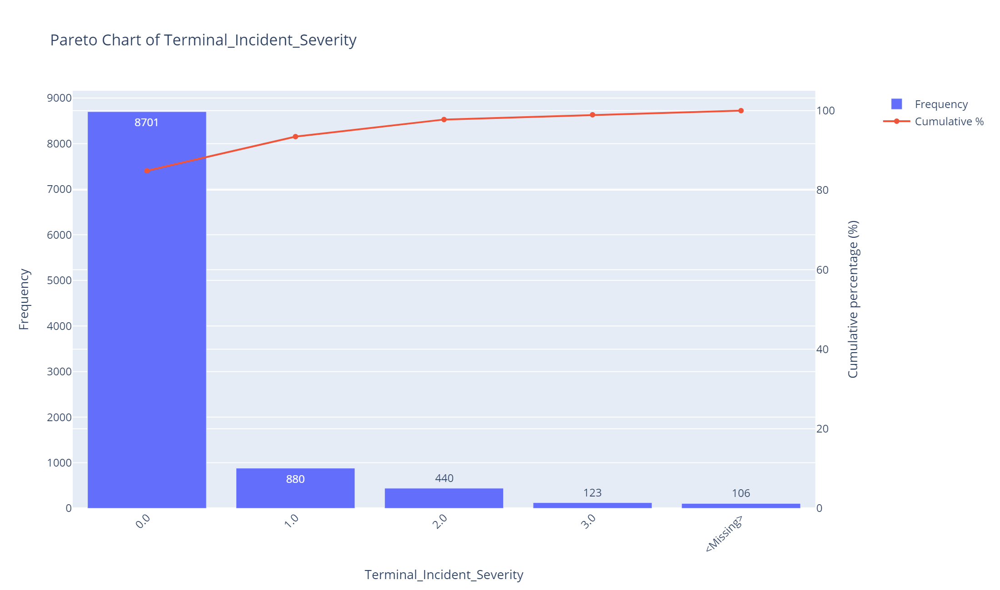

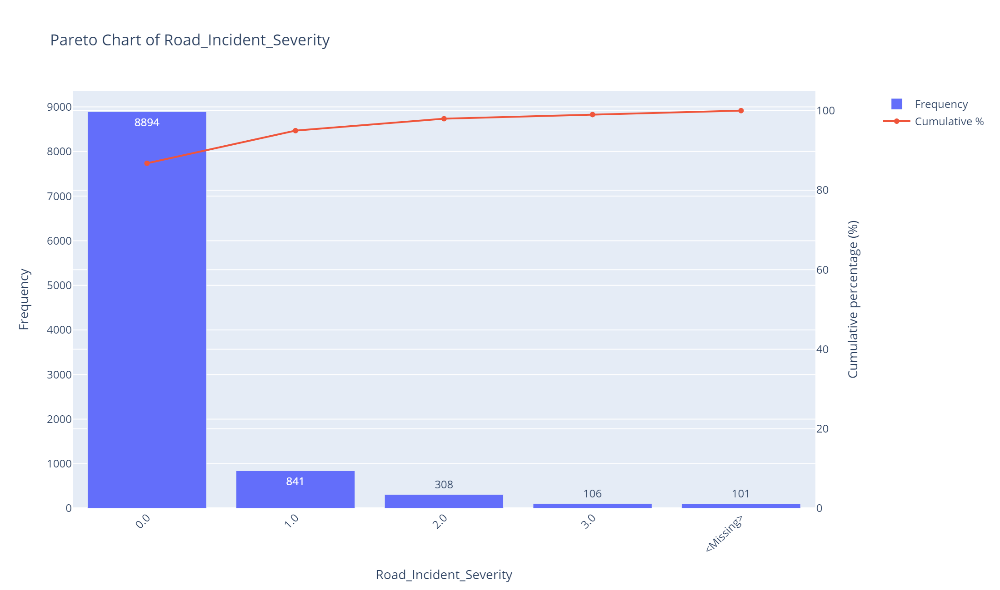

In [23]:
for pareto_col in categorical_plot_columns:
    pareto_series = df[pareto_col].astype("string").fillna("<Missing>")

    freq = pareto_series.value_counts().sort_values(ascending=False)
    cumulative_percent = freq.cumsum() / freq.sum() * 100

    pareto_df = pd.DataFrame({
        "Category": freq.index.astype(str),
        "Frequency": freq.values,
        "Cumulative percentage": cumulative_percent.values,
    })

    fig = make_subplots(specs=[[{"secondary_y": True}]])

    fig.add_trace(
        go.Bar(
            x=pareto_df["Category"],
            y=pareto_df["Frequency"],
            name="Frequency",
            text=pareto_df["Frequency"],
        ),
        secondary_y=False,
    )

    fig.add_trace(
        go.Scatter(
            x=pareto_df["Category"],
            y=pareto_df["Cumulative percentage"],
            name="Cumulative %",
            mode="lines+markers",
        ),
        secondary_y=True,
    )

    fig.update_layout(
        title=f"Pareto Chart of {pareto_col}",
        xaxis_title=pareto_col,
        xaxis_tickangle=-45,
    )
    fig.update_yaxes(title_text="Frequency", secondary_y=False)
    fig.update_yaxes(title_text="Cumulative percentage (%)", range=[0, 105], secondary_y=True)
    show_plotly(fig)

Insights: The Pareto principle shows that a few categories control most of the volume of the data. Using an 80% threshold shows where to concentrate attention:

- **Dominant Single Categories**: For many features only one category makes up almost all of the volume. For example Vehicle_Technical_Status ("OK") Trailer_Ready ("True") and Customs_Status ("Cleared") reach the 80% mark with the first bar. The other categories are not significant in volume. They are rare high‑impact edge cases.

- **Top-2 Concentration**: Features such as Vehicle_Type (Tractor_Unit + Swap_Body_Truck) and Transport_Object_Type (Trailer + Swap_Body) exceed 80% with two categories.

- **Top-4 Coverage**: Terminal_ID needs all four main terminals (T1‑T4) to reach 80% showing the load is spread across the network.

- **Flat Distributions**: Shift, Day_of_Week and Corridor_ID do not show a Pareto pattern; almost all categories are needed to reach 80%. This means no single day, shift or corridor dominates the data.

- **Rare Events (Zero‑Inflation)**: Terminal_Incident_Severity and Road_Incident_Severity reach 80% away, with the "0.0" category. This shows that severe incidents (1.0, 2.0 3.0) are very rare and sit in the not tail.

- **Data Anomaly**: The <Missing> category never reaches 80% on its own proving that missing data is spread out and never dominates any single feature.

### 4.2 Numerical variables

We use interactive box plots, violin plots, histograms, density plots, and distribution statistics to understand numerical variables. Plotly lets you hover over values, zoom into ranges, and compare groups without changing the underlying data.

In [24]:
# --- Semantic numeric roles ---
INTERVAL = ['Slot_Buffer_min']
#Event_Timestamp is deliberately excluded, because it also serves as an identifier
RATIO = [
    'Distance_to_Terminal_km', 'Weather_Severity_Index',
    'Terminal_Congestion_Index', 'Road_Congestion_Index',
    'Yard_Occupancy_pct', 'Queue_Length_vehicles',
    'Gate_Processing_Time_min', 'Expected_Disruption_Duration_min',
    'Current_Delay_min', 'ETA_Uncertainty_min', 'Slot_Window_min',
    'Remaining_Driver_Hours', 'Service_Level_Penalty_EUR',
    'Vehicle_Load_Factor_pct', 'Empty_Km_Ratio_pct',
    'Alternative_Route_Extra_km', 'Nearby_Compatible_Vehicles',
    'Historical_Route_Reliability_pct', 'Disruptions_Last_7d',
    'Data_Quality_Score_pct', 'Estimated_CO2_kg',
]

# Numeric for univariate *continuous* analysis
numeric_plot_columns = [c for c in INTERVAL + RATIO if c in df.columns]

#### Interactive box plots

Box plots summarize the median, spread, and potential outliers. Hover over a box or point to inspect values. The first chart shows the overall distribution; the next section compares groups.

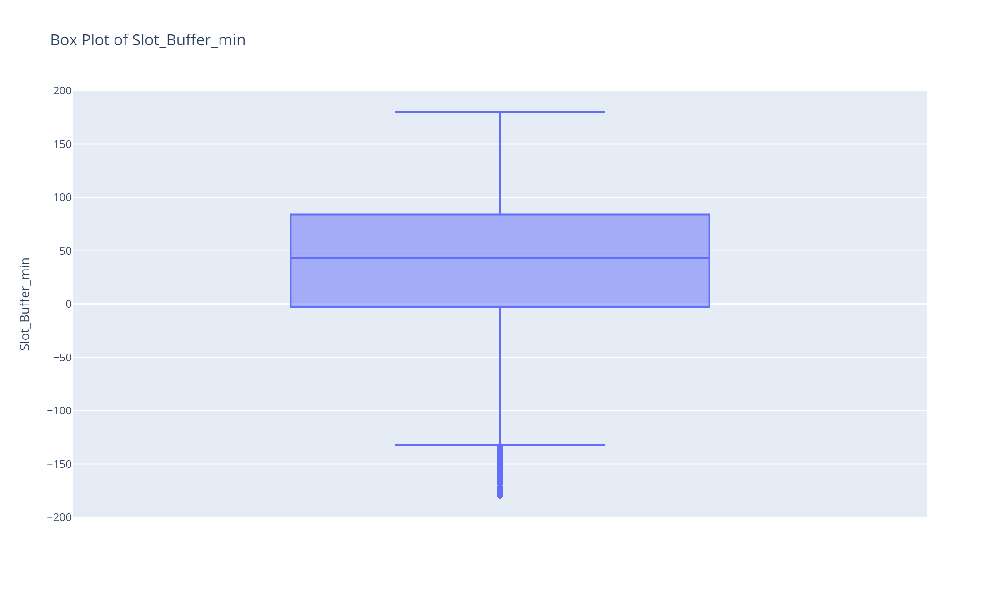

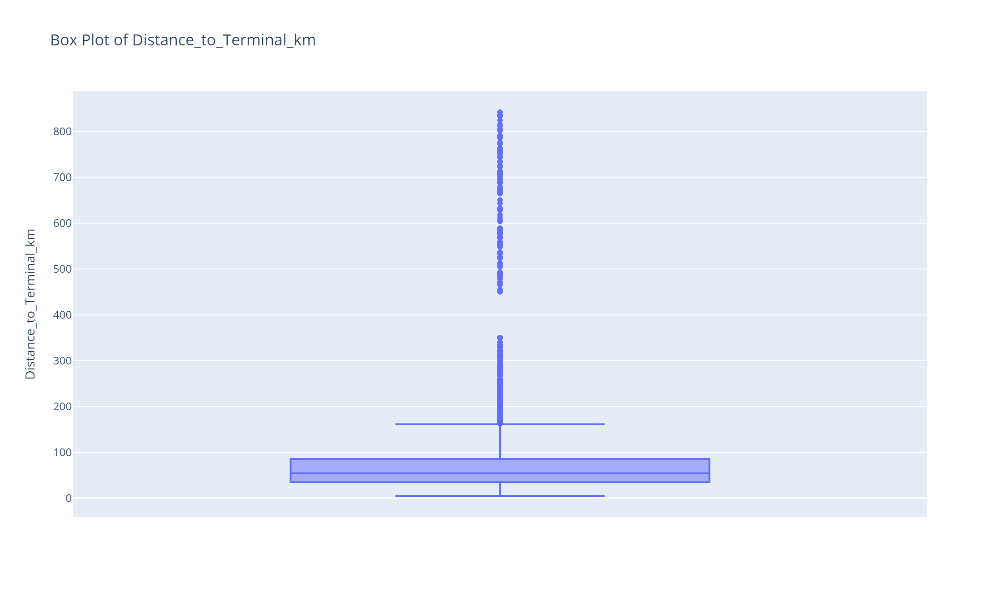

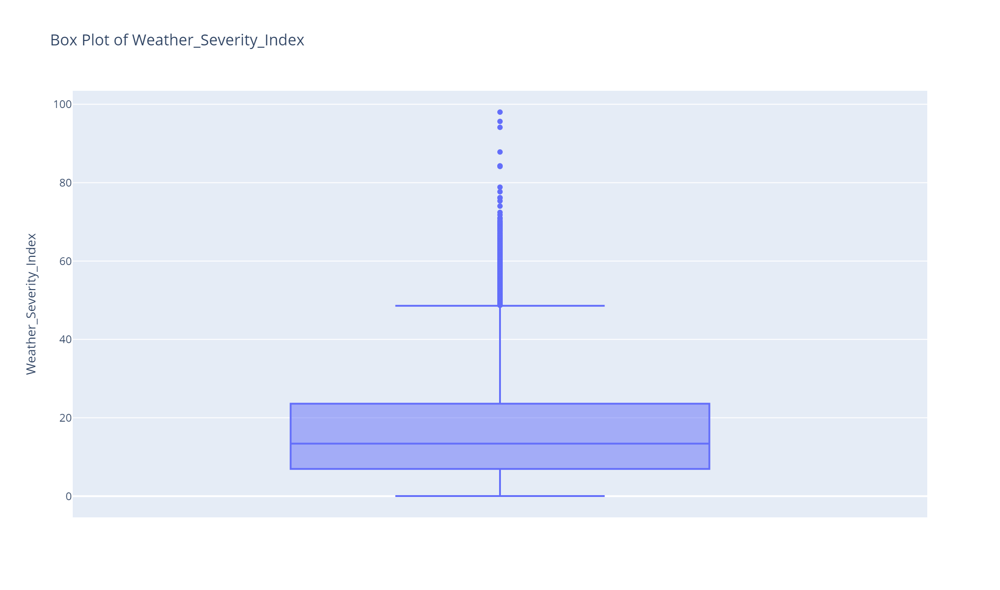

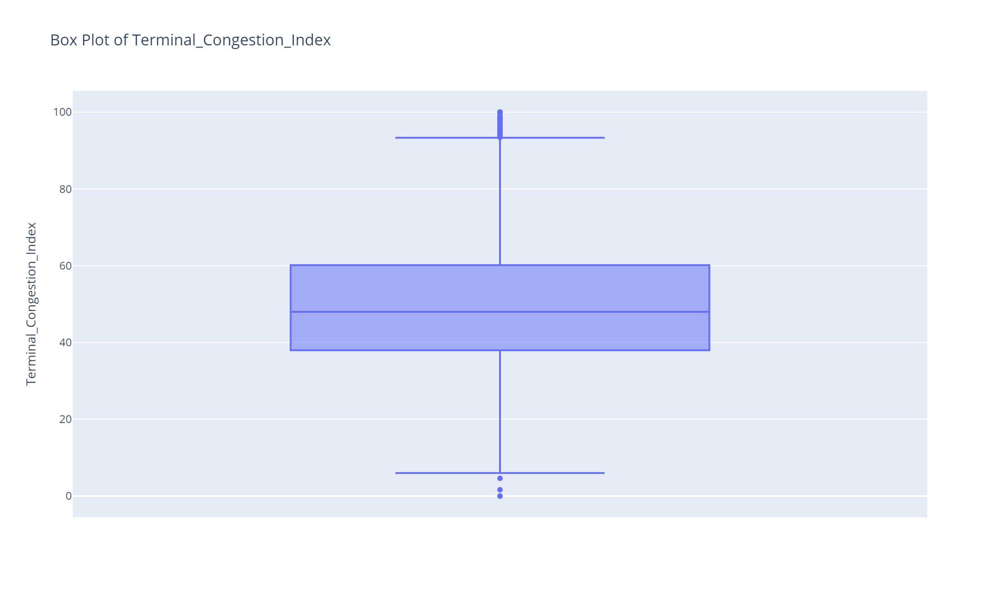

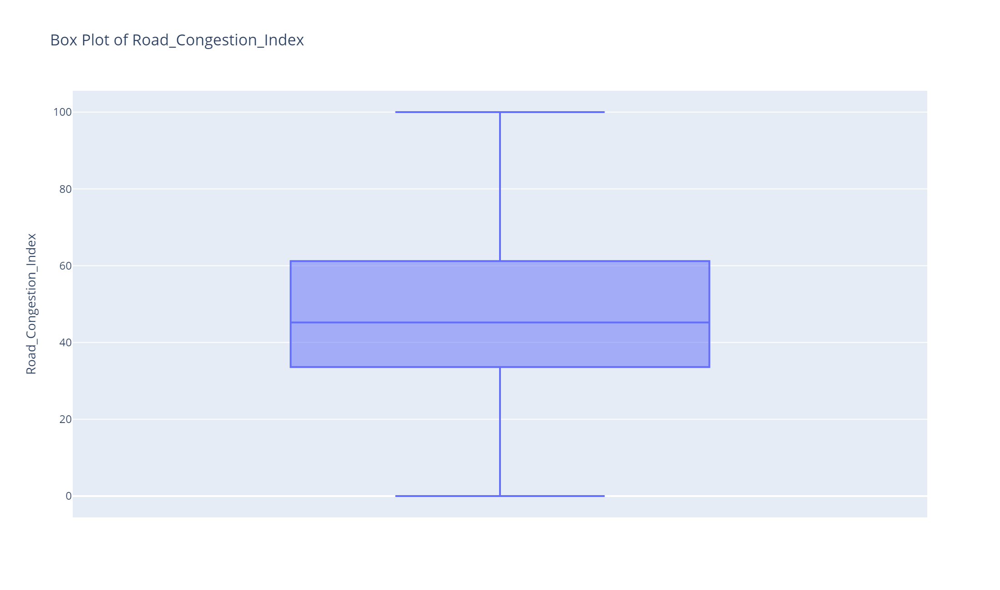

...

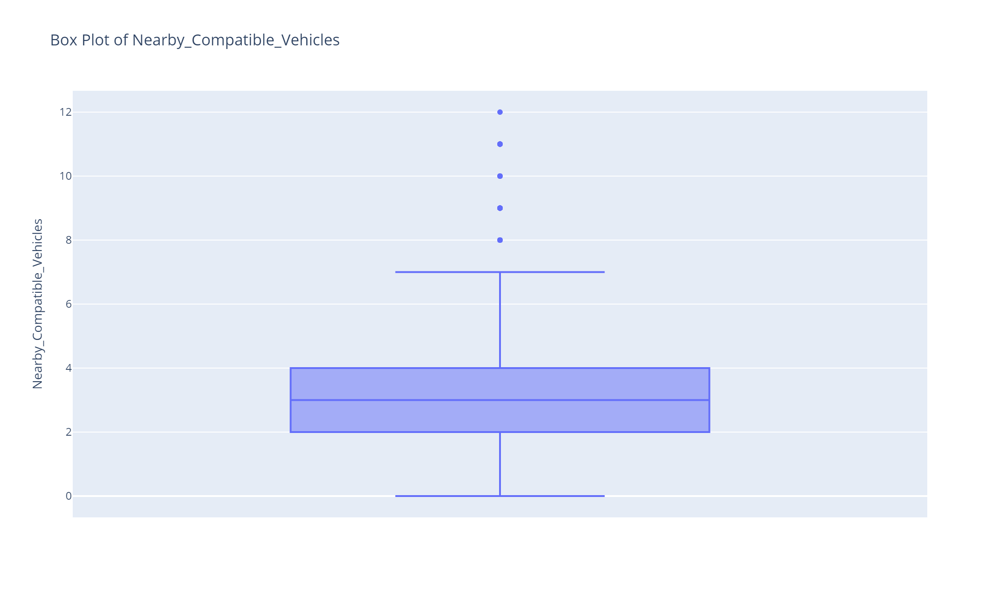

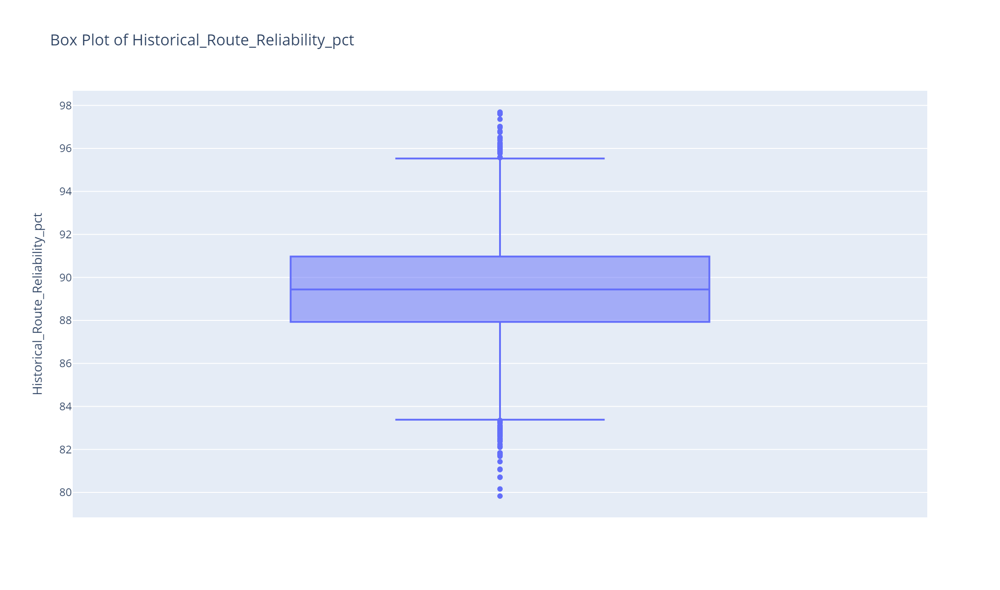

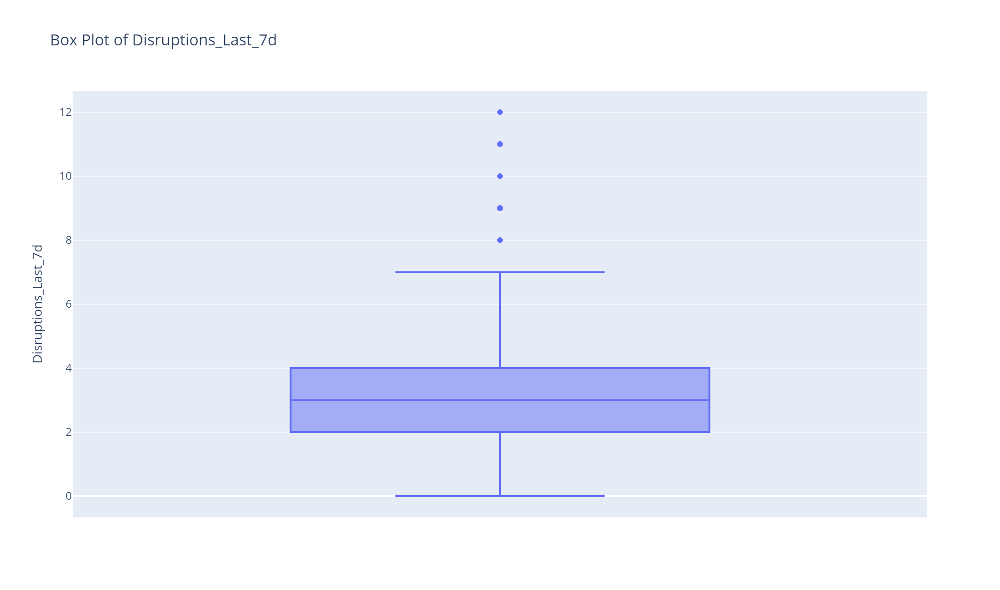

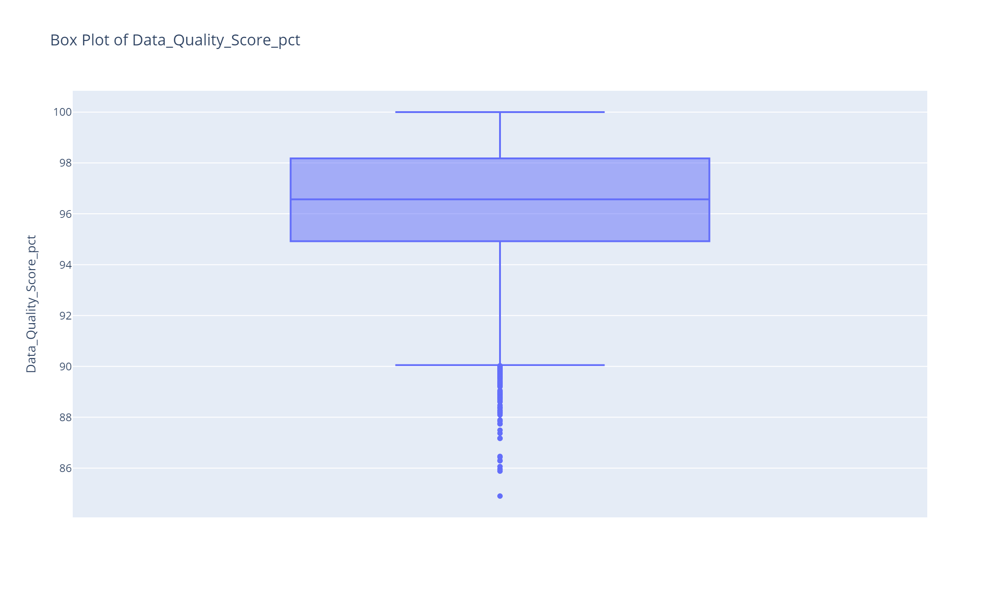

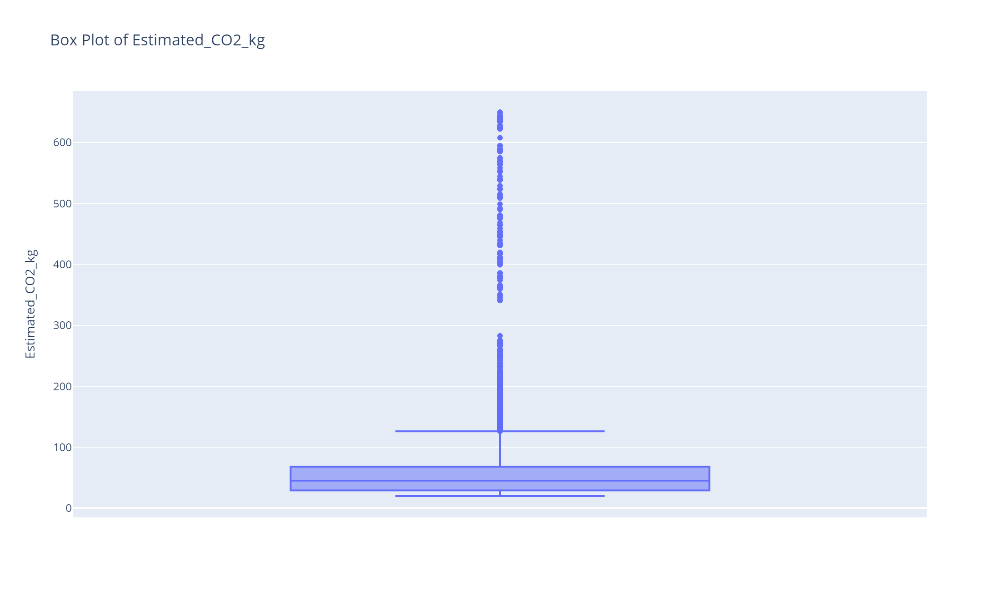

In [25]:
if not numeric_plot_columns:
    print("No numerical variables detected.")
else:
    for col in numeric_plot_columns:
        fig = px.box(
            df,
            y=col,
            points="outliers",
            title=f"Box Plot of {col}",
        )
        fig.update_layout(height=450)
        show_plotly(fig)


insights:

- **Right-skewed distributions** show up in `Distance_to_Terminal_km`, `Gate_Processing_Time_min`, `Current_Delay_min`, `Service_Level_Penalty_EUR`, and `Estimated_CO2_kg`. Long upper whiskers. Tons of outliers on the high end. Logistics data does this a lot. Most shipments move normally. Some hit extreme delays, crazy penalties, weird distances.
- **Bounded features** like `Terminal_Congestion_Index`, `Road_Congestion_Index`, `Yard_Occupancy_pct`, and `Vehicle_Load_Factor_pct` max out at 100. They sit between 0 and 100. Distributions look pretty balanced. Interquartile ranges don't lean one way or another. No wild skew.
- **Tight and symmetric** features like `ETA_Uncertainty_min`, `Data_Quality_Score_pct`, and `Historical_Route_Reliability_pct` stay tight. Narrow interquartile ranges. Symmetric shape. Estimates stay consistent across the data. Quality doesn't swing around much.
- **Discrete and variable** features like `Slot_Window_min` break into chunks at 30, 45, 60, and 90 minutes. Discrete time slots. `Slot_Buffer_min` jumps all over the place. Positive values. Negative values. Missed slots mixed with slack time. Scheduling flexibility varies wildly.
- **Outliers everywhere** on the unbounded features. Dots beyond the whiskers. Disruptions in the data. Unusual cases. Log scaling or robust scaling could clean these up before running models.

#### Interactive grouped box plots

When a group variable is available, these plots compare numerical distributions across categories. If a hue variable is configured, color adds another categorical dimension.

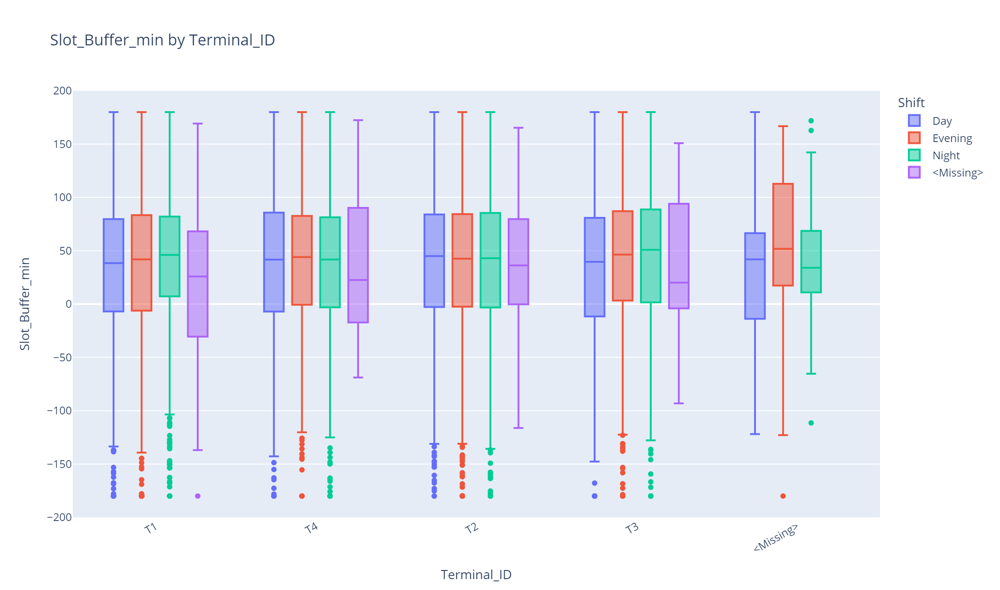

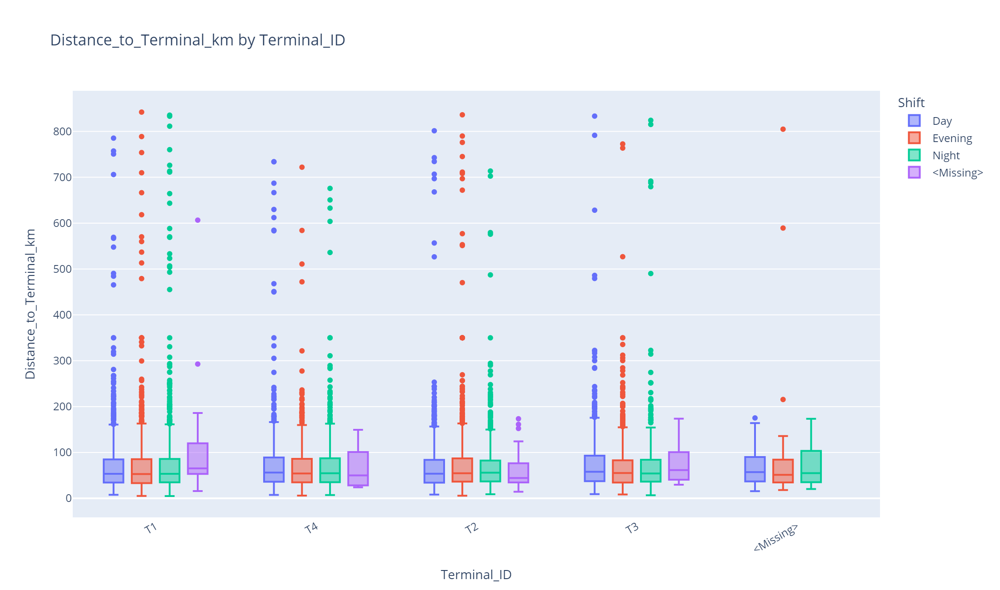

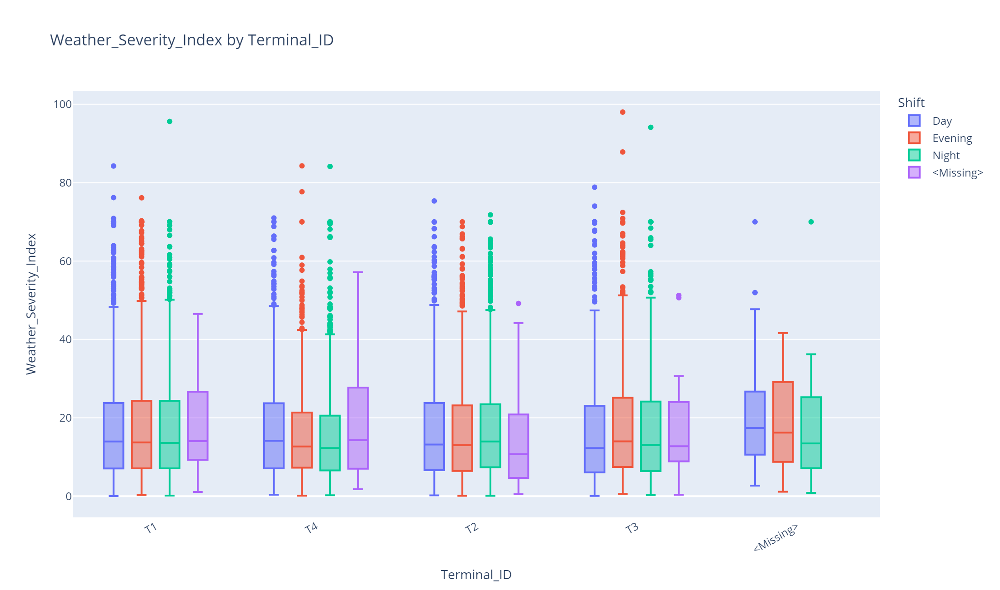

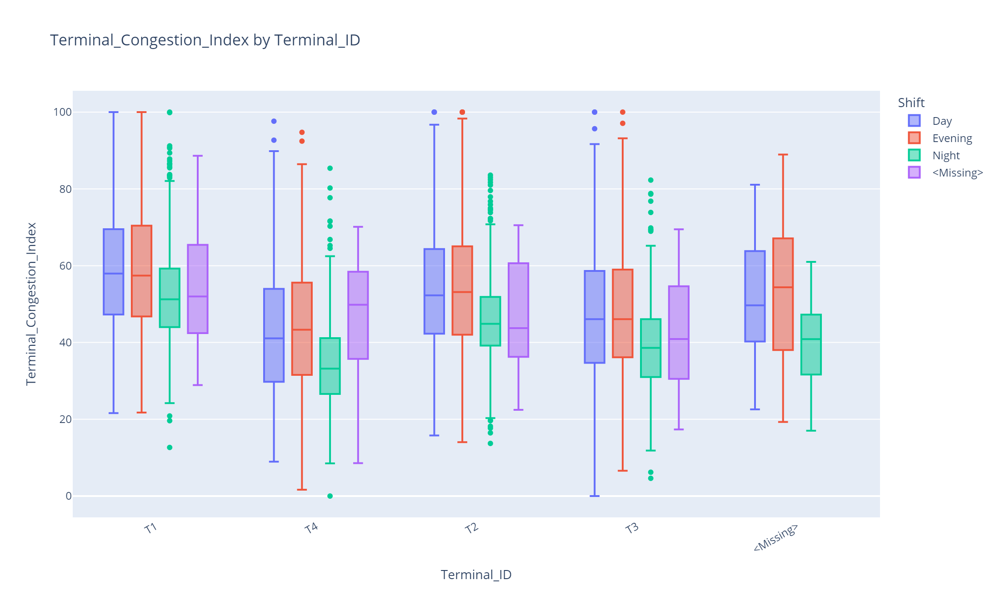

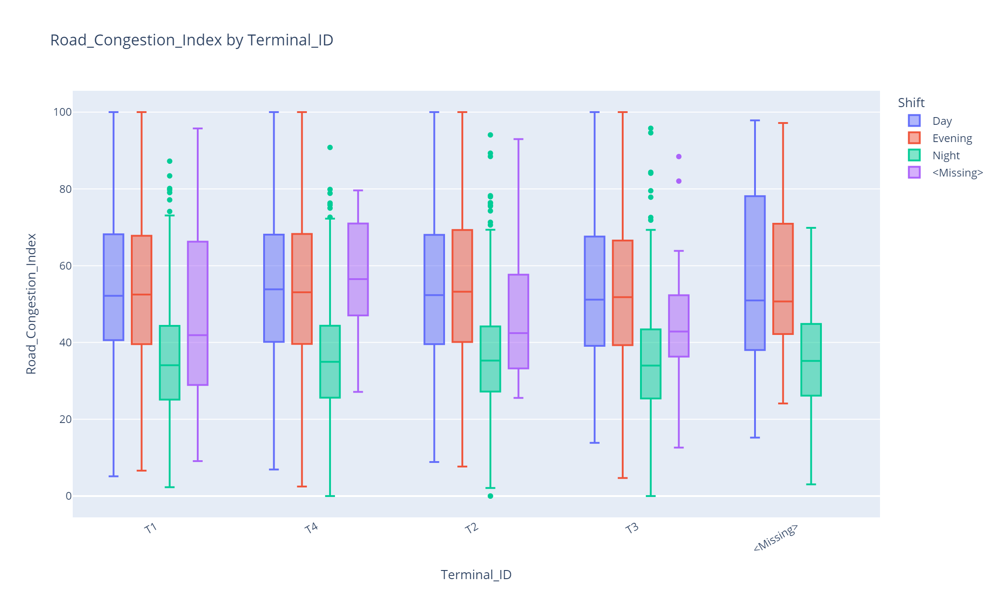

...

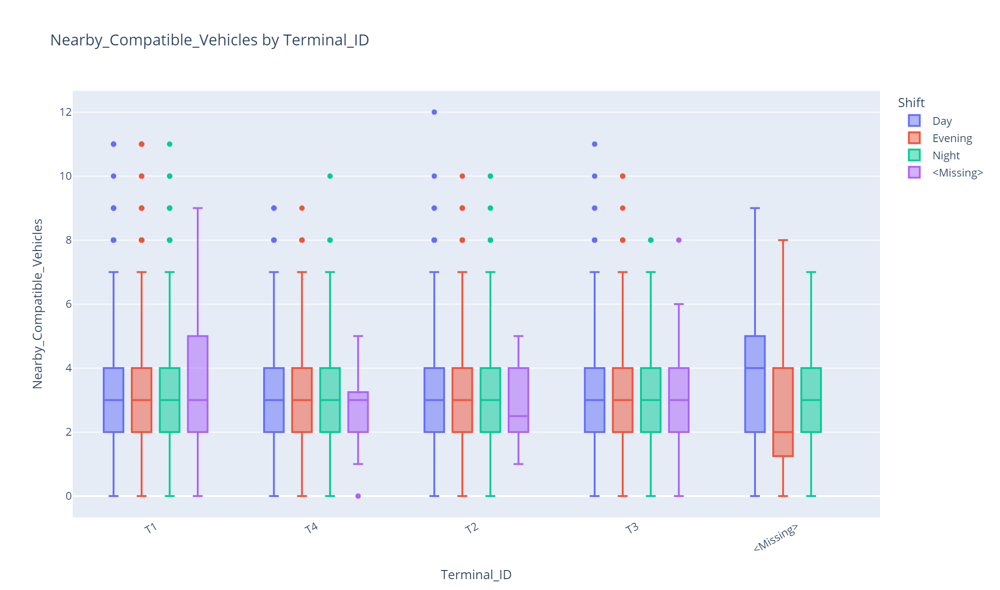

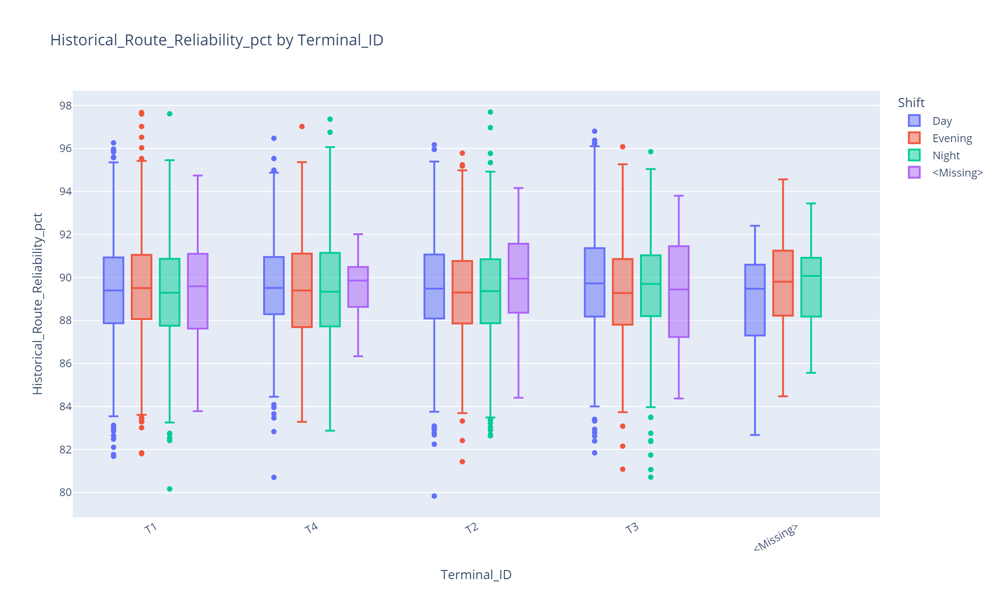

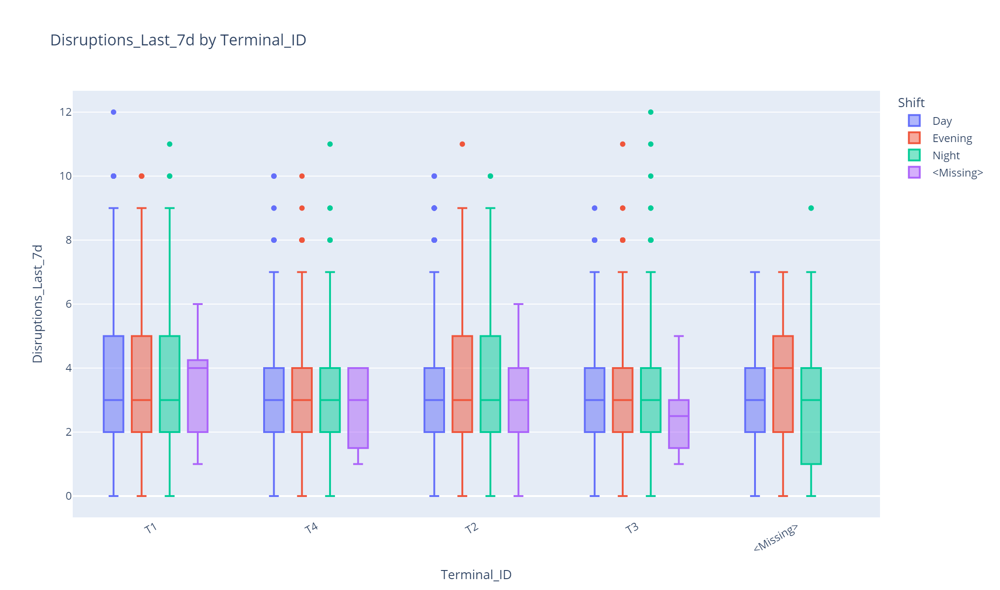

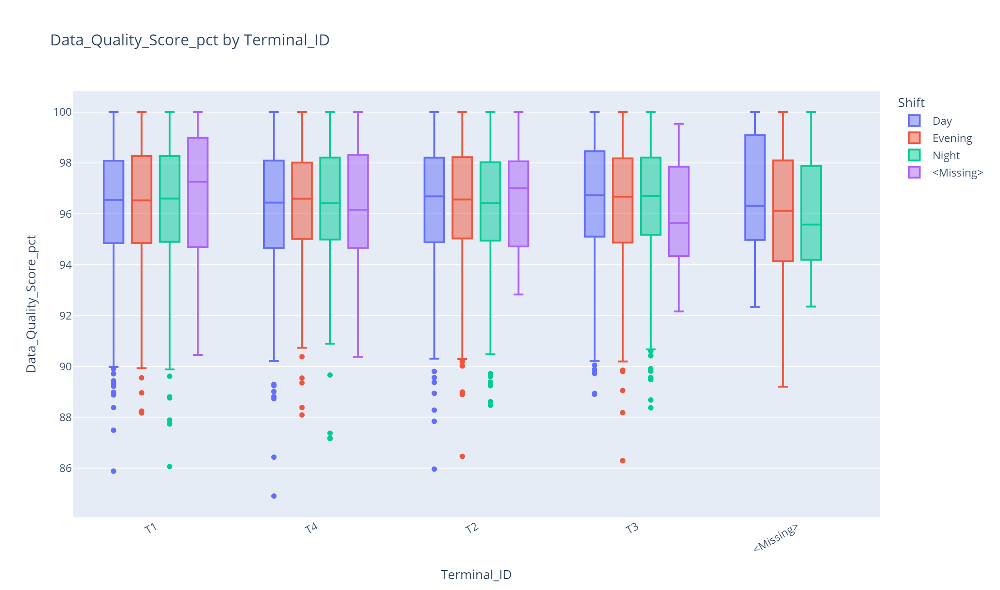

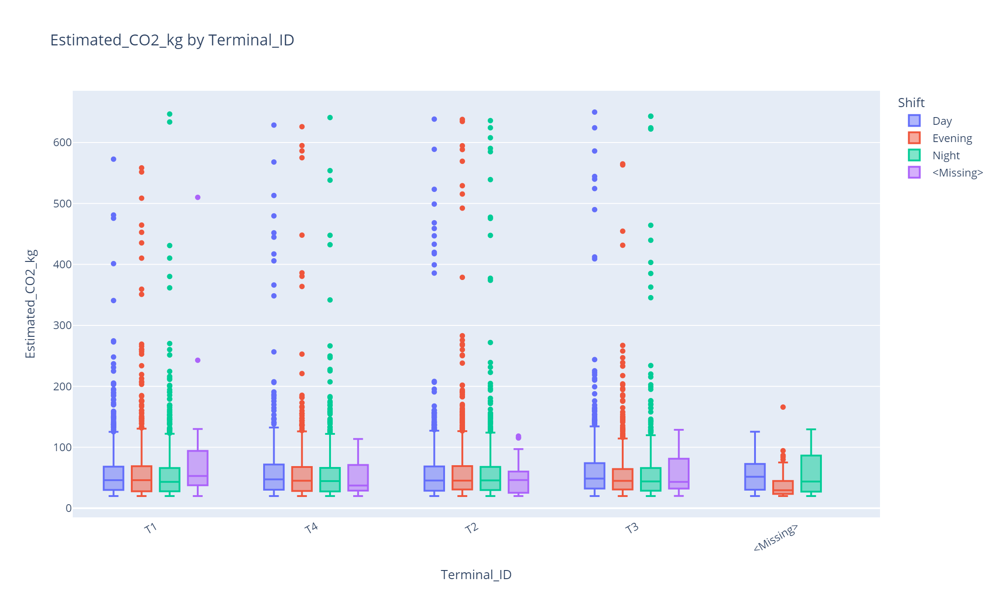

In [26]:
if group_col is None:
    print("No grouping variable is available for grouped box plots.")
else:
    for col in numeric_plot_columns:
        # Work on a temporary copy so categorical display formatting does not
        # change the original dataset.
        plot_df = df.copy()
        plot_df[group_col] = plot_df[group_col].astype("string").fillna("<Missing>")

        color_col = None
        if hue_col is not None and hue_col != group_col:
            plot_df[hue_col] = plot_df[hue_col].astype("string").fillna("<Missing>")
            color_col = hue_col
        fig = px.box(
            plot_df,
            x=group_col,
            y=col,
            color=color_col,
            points="outliers",
            title=f"{col} by {group_col}",
        )
        fig.update_layout(xaxis_tickangle=-30)
        show_plotly(fig)
        



remarks:
- **Shift is the strongest driver of operations:** Almost across the board—especially in `Road_Congestion_Index`, `Queue_Length_vehicles`, `Expected_Disruption_Duration_min`, and `Current_Delay_min`—the **Night** shift (green boxes) consistently shows a lower median and a tighter interquartile range than Day and Evening. Day and Evening tend to mirror each other with higher medians and wider spread, reflecting peak-hour chaos.
- **Consistent extremes:** `Distance_to_Terminal_km` and `Service_Level_Penalty_EUR` display massive vertical stretches of outlier dots across all terminals and shifts. Night shifts have slightly fewer high-end outliers, but extreme cases are present everywhere.
- **Terminal differences are visually mild:** For most features, the boxes across T1, T2, T3, and T4 are remarkably similar. While the dictionary notes terminals have different baseline congestion patterns, in these plots, the shift effect is visibly much more pronounced than the terminal effect.

#### Interactive violin plots

A violin plot combines information about **distribution shape** with a box-plot summary. Hovering helps inspect individual observations and group differences.

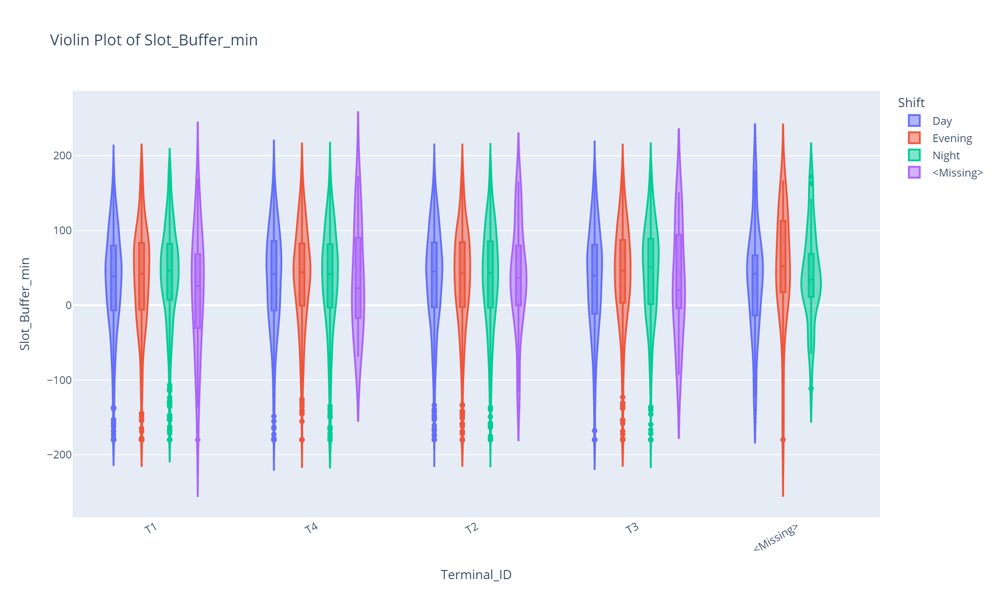

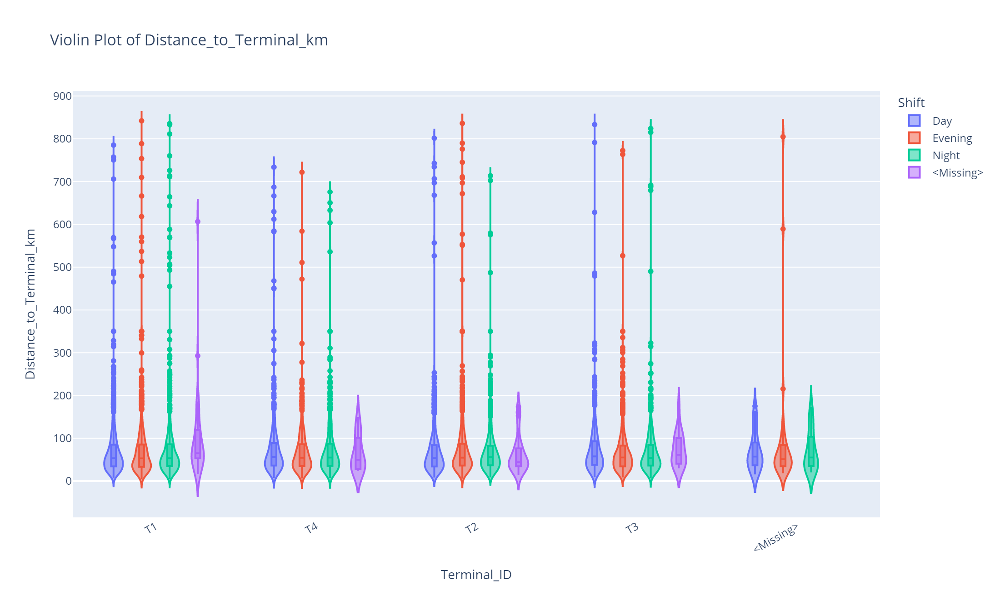

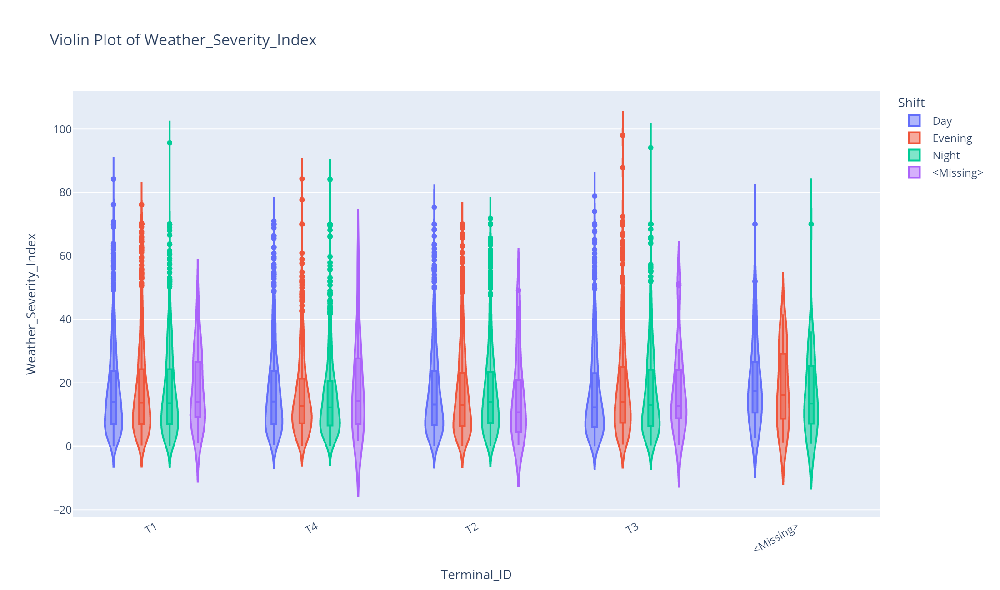

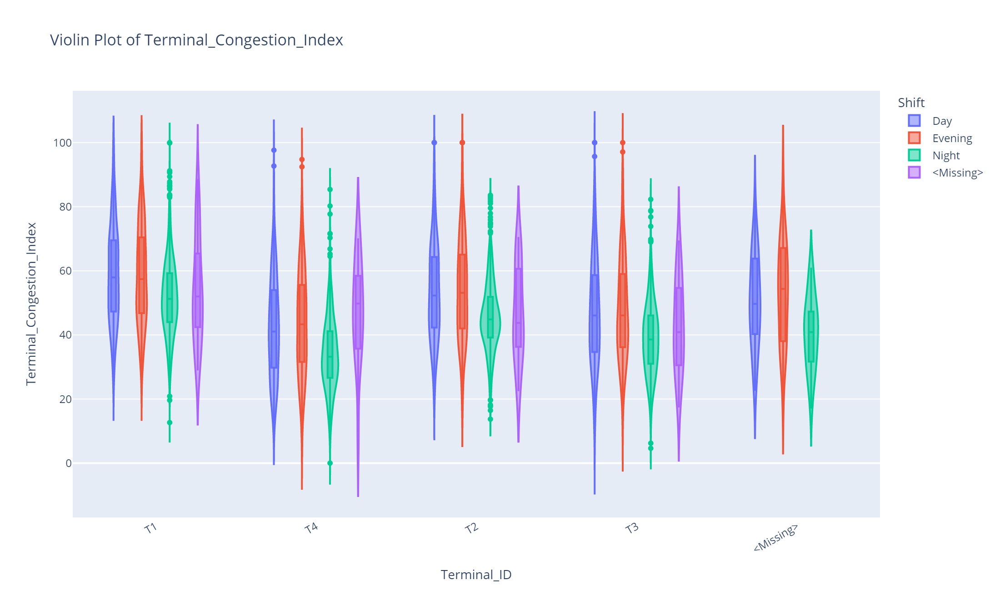

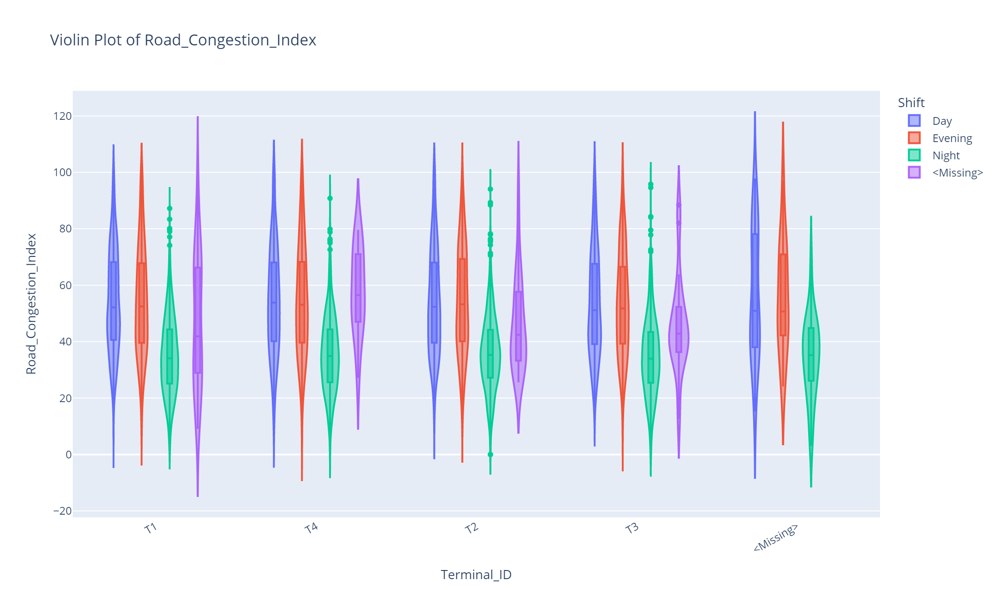

...

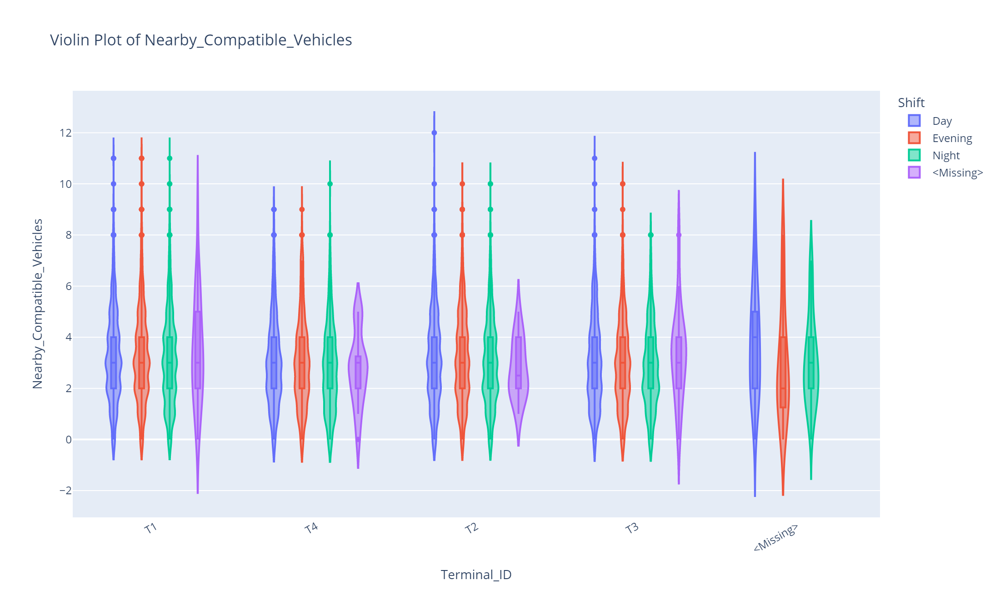

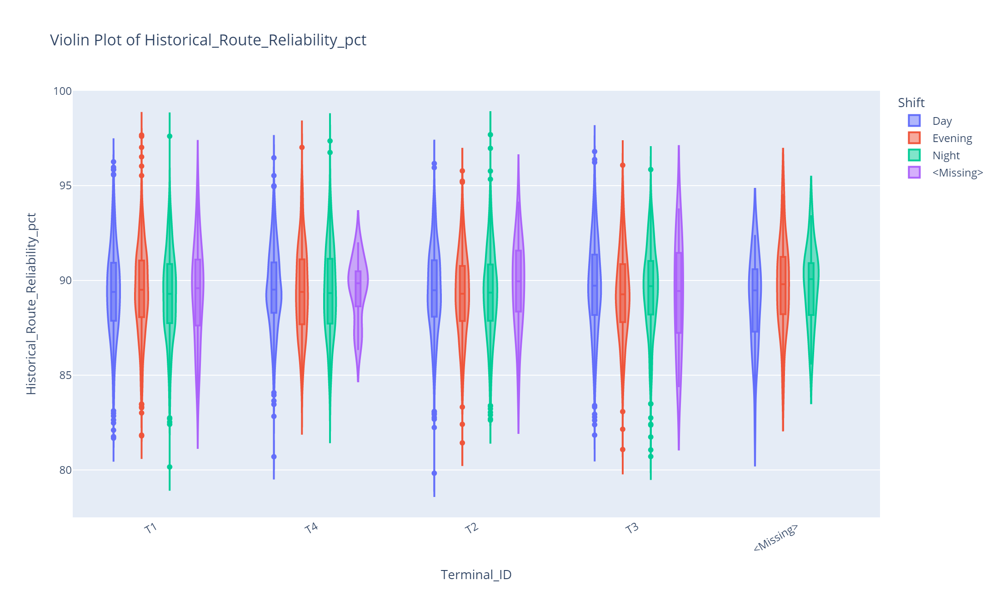

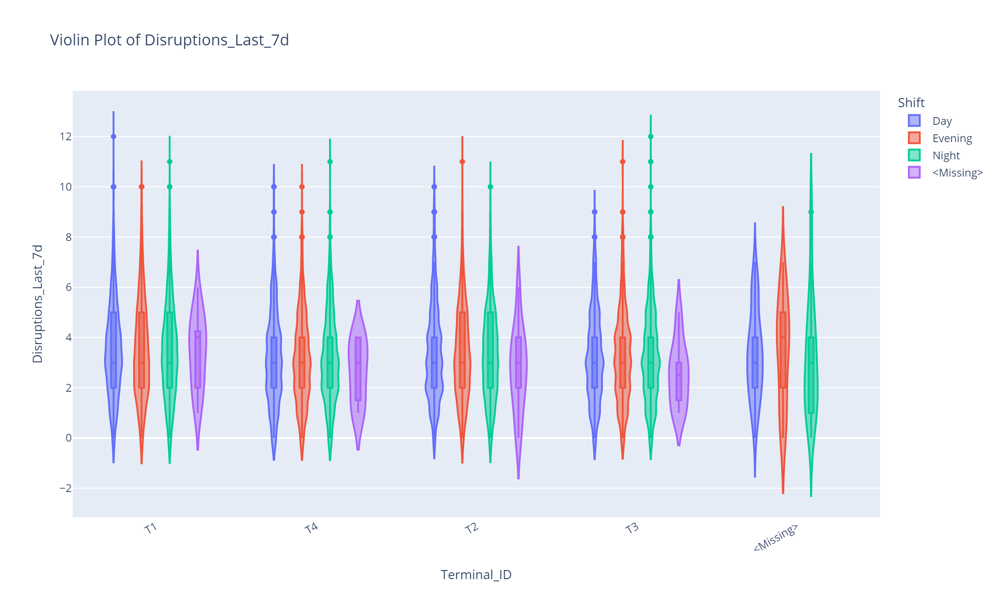

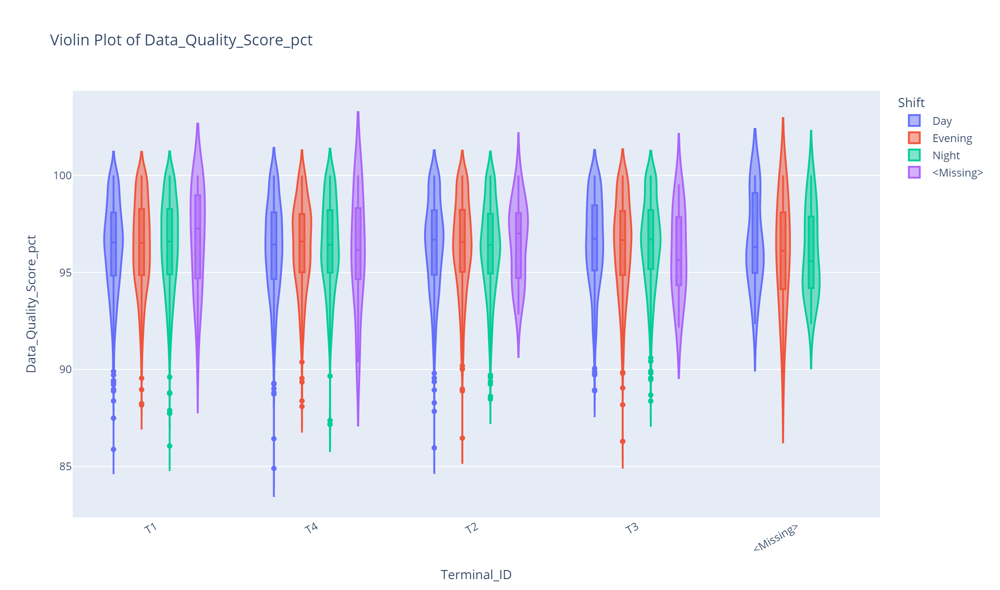

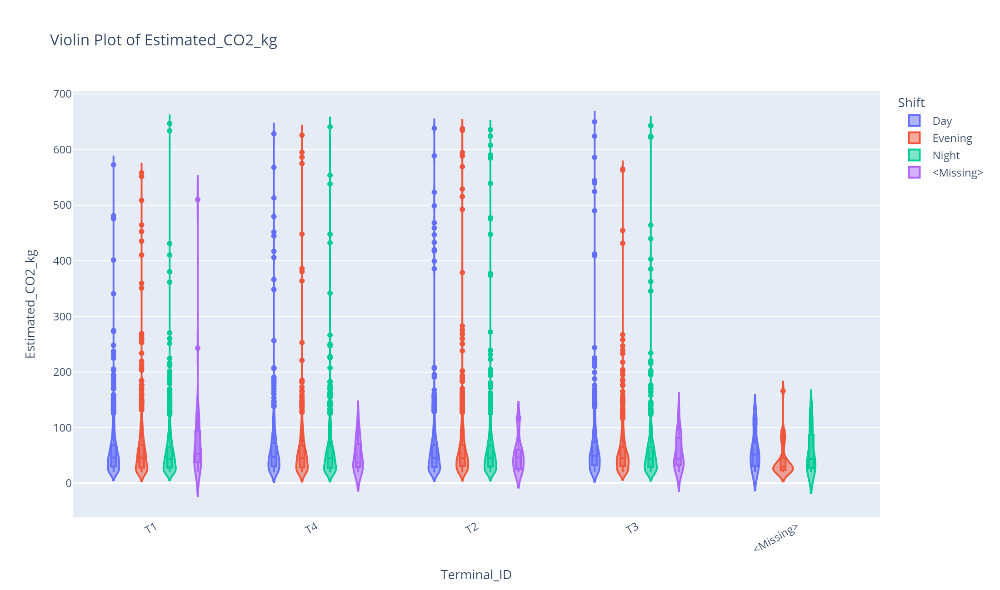

In [27]:
for col in numeric_plot_columns:
    plot_df = df.copy()

    if group_col is not None:
        plot_df[group_col] = plot_df[group_col].astype("string").fillna("<Missing>")
    
    color_col = None
    if hue_col is not None and hue_col != group_col:
            plot_df[hue_col] = plot_df[hue_col].astype("string").fillna("<Missing>")
            color_col = hue_col

    fig = px.violin(
        plot_df,
        x=group_col if group_col is not None else None,
        y=col,
        color=color_col if color_col is not None else None,
        box=True,
        points="outliers",
        title=f"Violin Plot of {col}",
    )
    fig.update_layout(xaxis_tickangle=-30)
    show_plotly(fig)


remark:
- long tails stretching way up in `Distance_to_Terminal_km`, `Service_Level_Penalty_EUR`, and `Expected_Disruption_Duration_min` confirm that massive outliers exist across every terminal and every shift.
- For congestion and delay metrics (`Road_Congestion_Index`, `Current_Delay_min`, `Queue_Length_vehicles`), the Day and Evening violins are wide and sit high up, while the Night shift (green) is noticeably skinnier and pushed down. The shapes prove Night shift is consistently less chaotic, not just an outlier in the box plot.
- ** `Yard_Occupancy_pct` and `Vehicle_Load_Factor_pct` show wide centers, indicating that most operations cluster tightly around the mean, with no major extremes.


#### Interactive histograms, skewness, and kurtosis

- A **histogram** shows how observations are distributed across value ranges.
- **Skewness** describes asymmetry.
- **Kurtosis** describes tail heaviness relative to a normal distribution.

Use the hover information and legend controls to compare groups interactively.

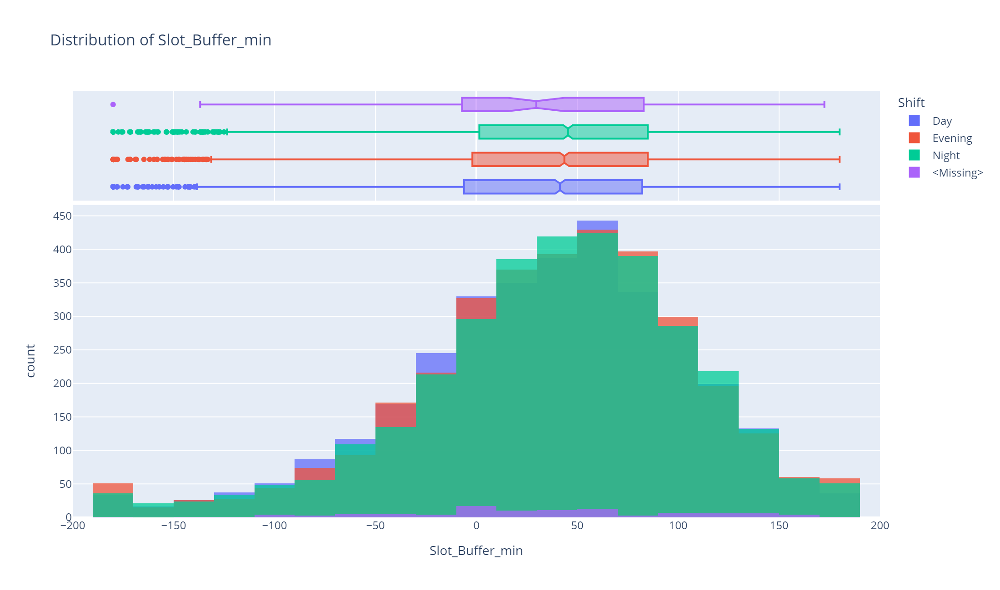

Slot_Buffer_min
  Skewness: -0.599
  Kurtosis: 0.555 (Normal/Low tail risk)


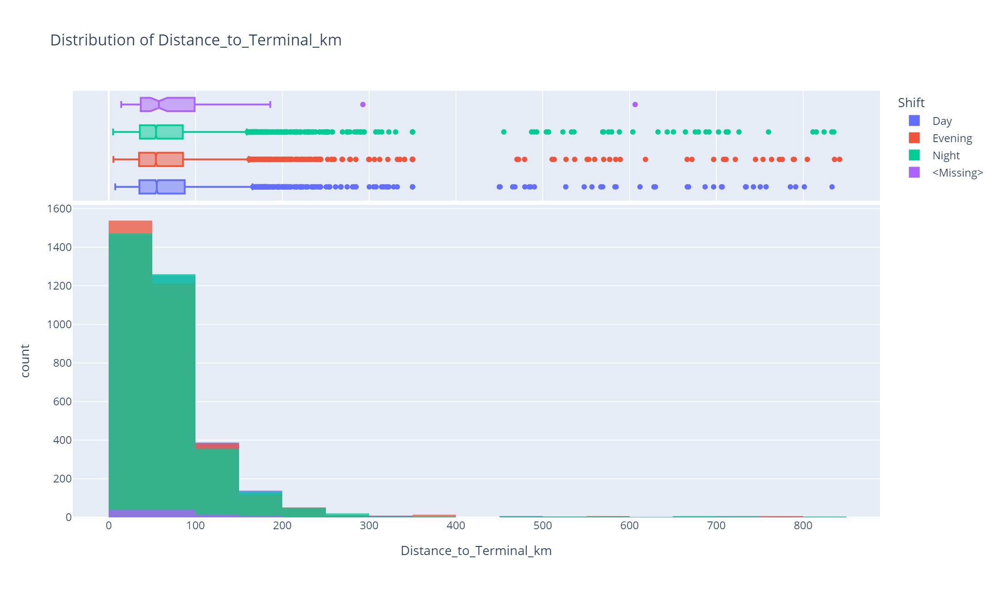

Distance_to_Terminal_km
  Skewness: 5.264
  Kurtosis: 39.035 (High tail risk)


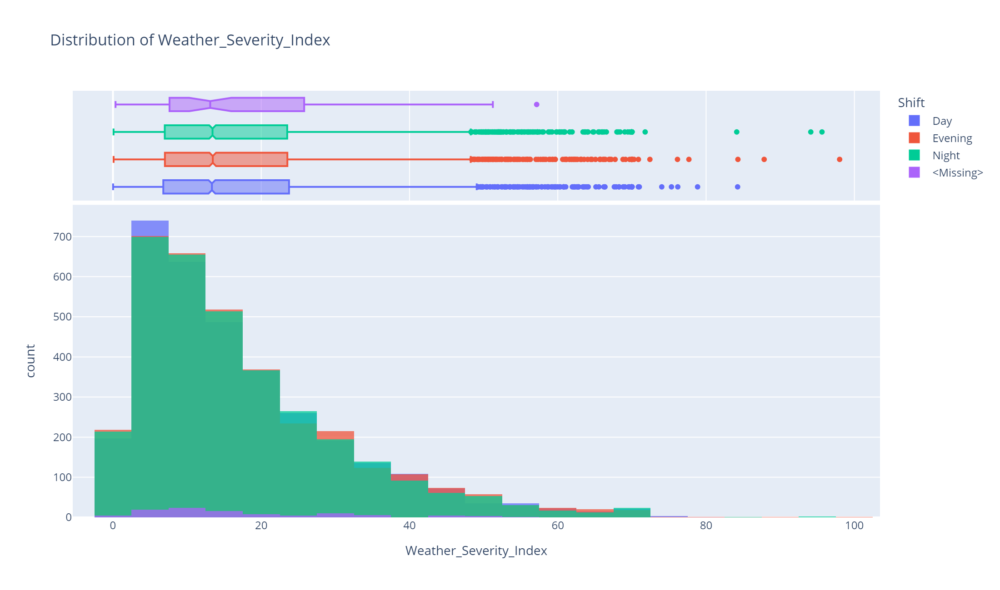

Weather_Severity_Index
  Skewness: 1.415
  Kurtosis: 2.173 (Normal/Low tail risk)


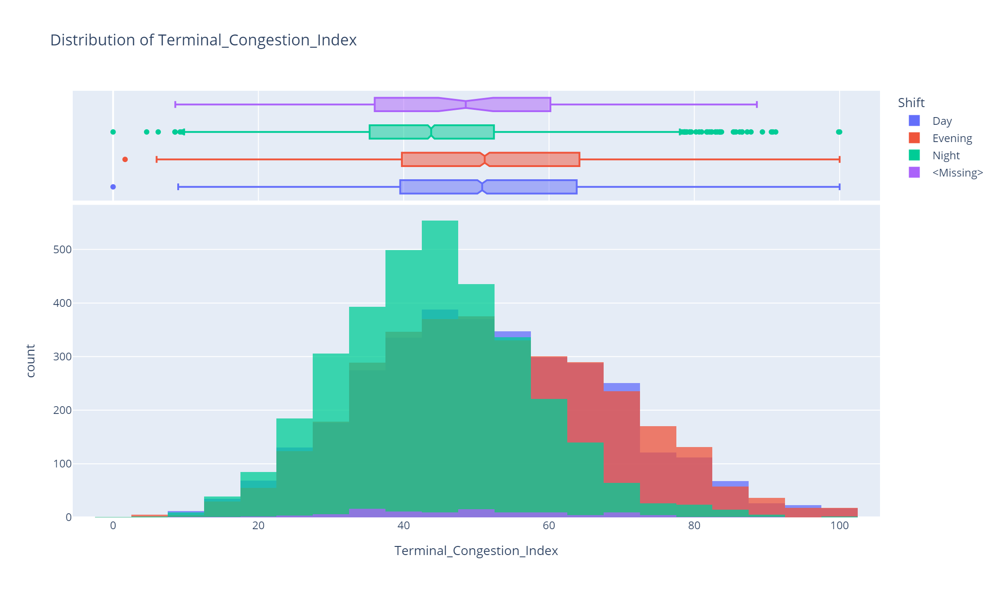

Terminal_Congestion_Index
  Skewness: 0.318
  Kurtosis: -0.097 (Normal/Low tail risk)


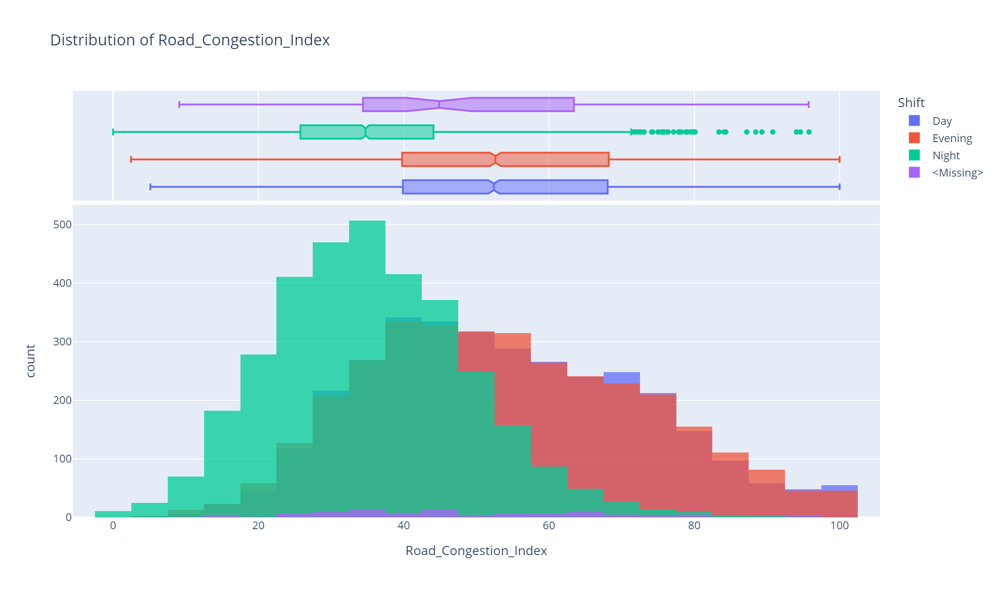

Road_Congestion_Index
  Skewness: 0.435
  Kurtosis: -0.312 (Normal/Low tail risk)


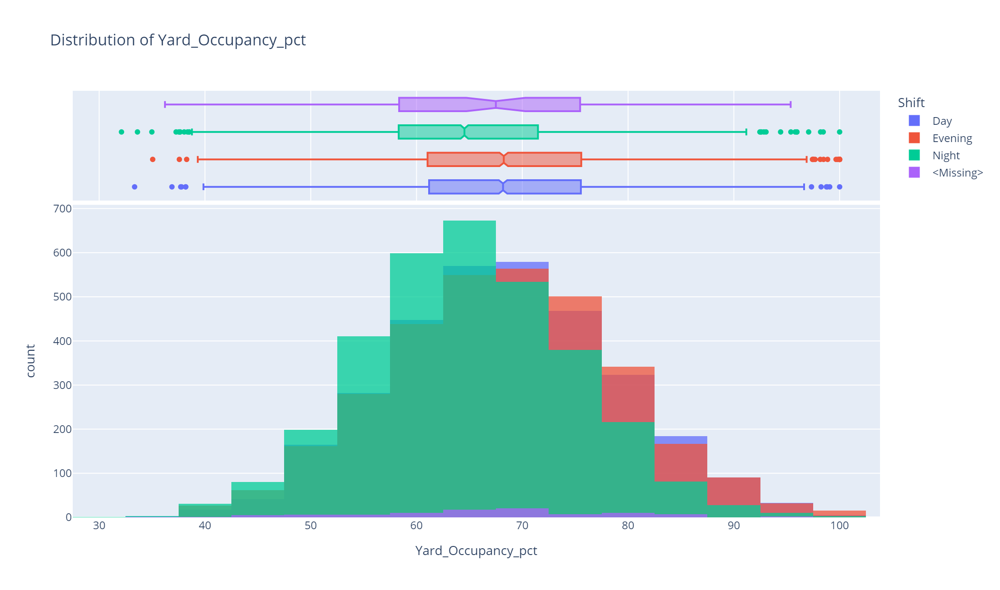

Yard_Occupancy_pct
  Skewness: 0.088
  Kurtosis: -0.094 (Normal/Low tail risk)


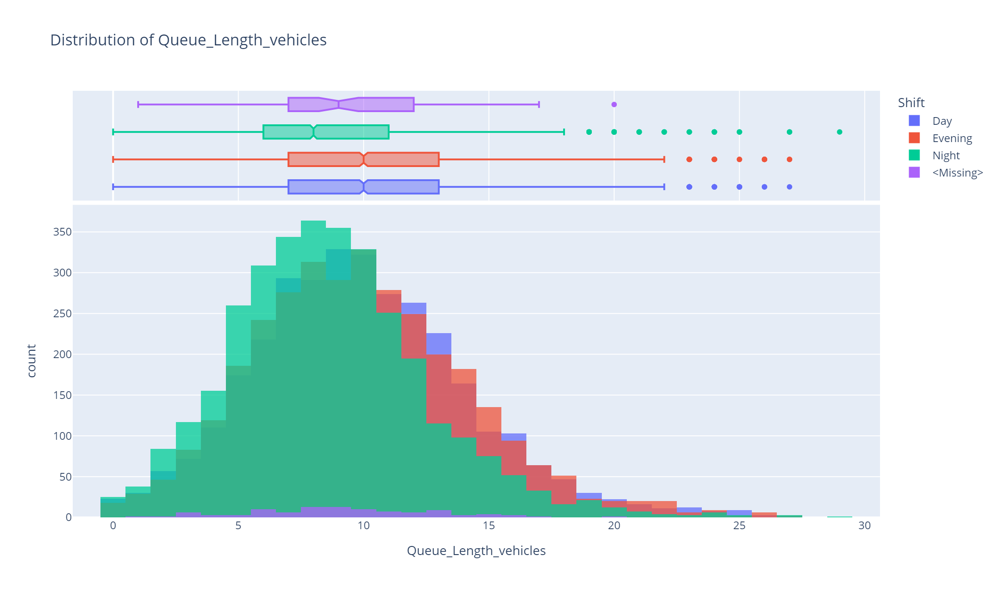

Queue_Length_vehicles
  Skewness: 0.563
  Kurtosis: 0.730 (Normal/Low tail risk)


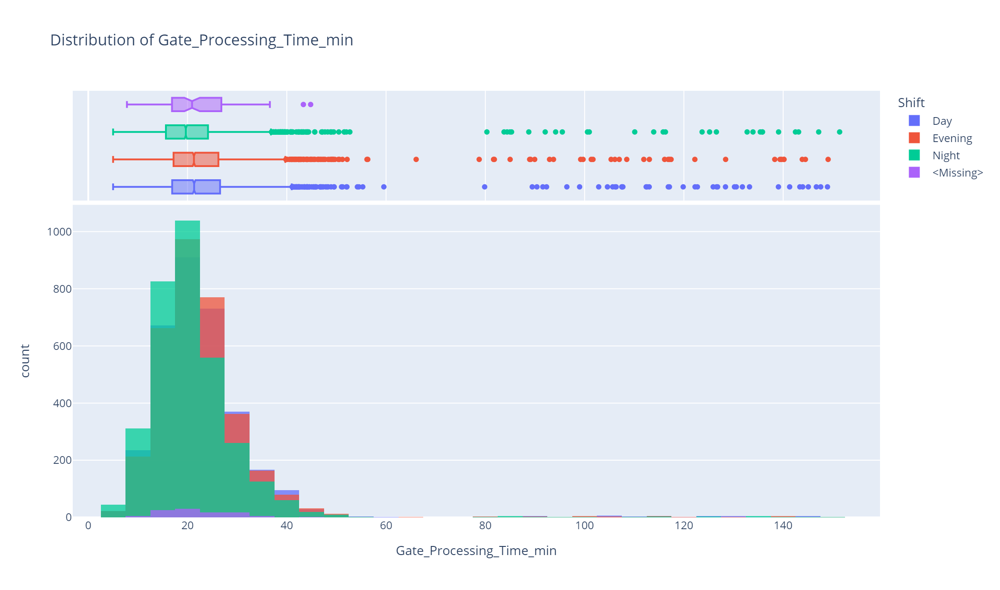

Gate_Processing_Time_min
  Skewness: 5.297
  Kurtosis: 42.803 (High tail risk)


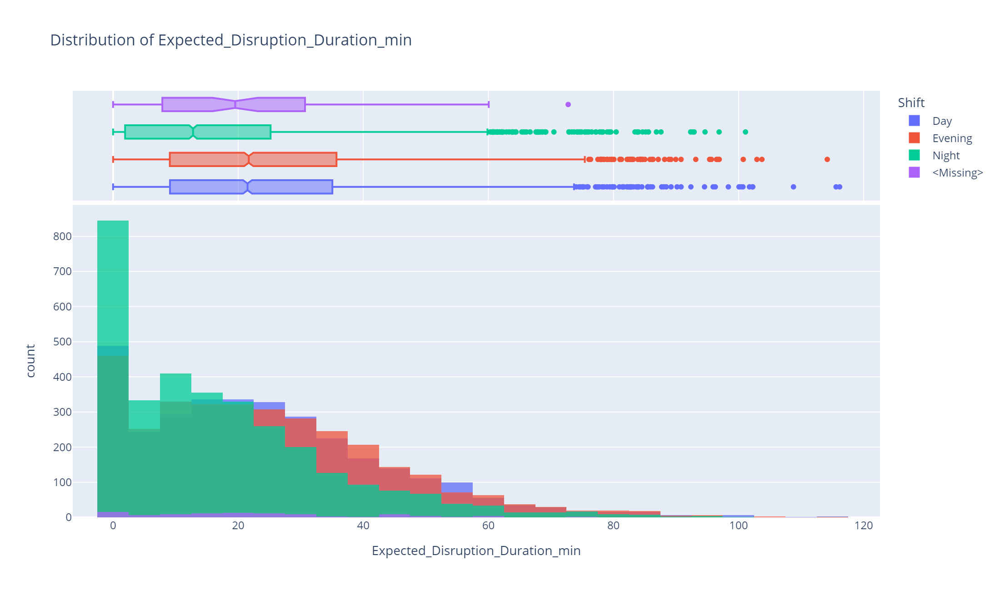

Expected_Disruption_Duration_min
  Skewness: 1.023
  Kurtosis: 1.048 (Normal/Low tail risk)


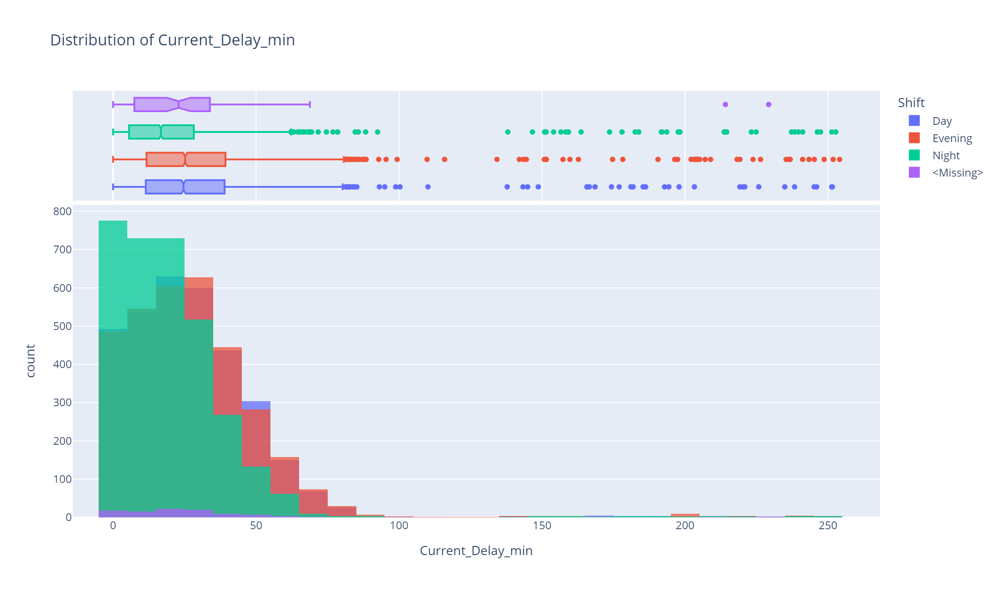

Current_Delay_min
  Skewness: 3.698
  Kurtosis: 24.668 (High tail risk)


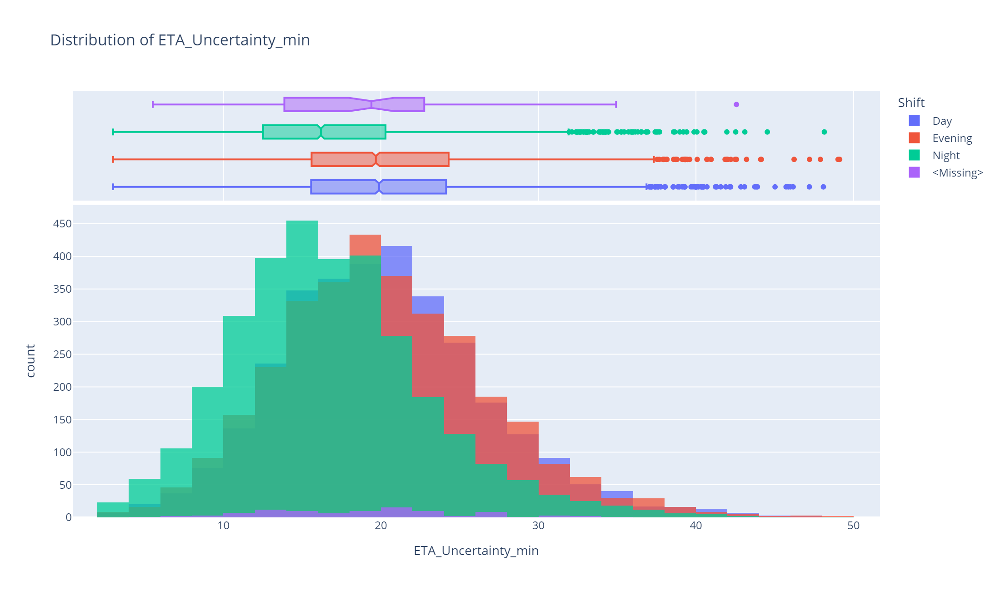

ETA_Uncertainty_min
  Skewness: 0.525
  Kurtosis: 0.608 (Normal/Low tail risk)


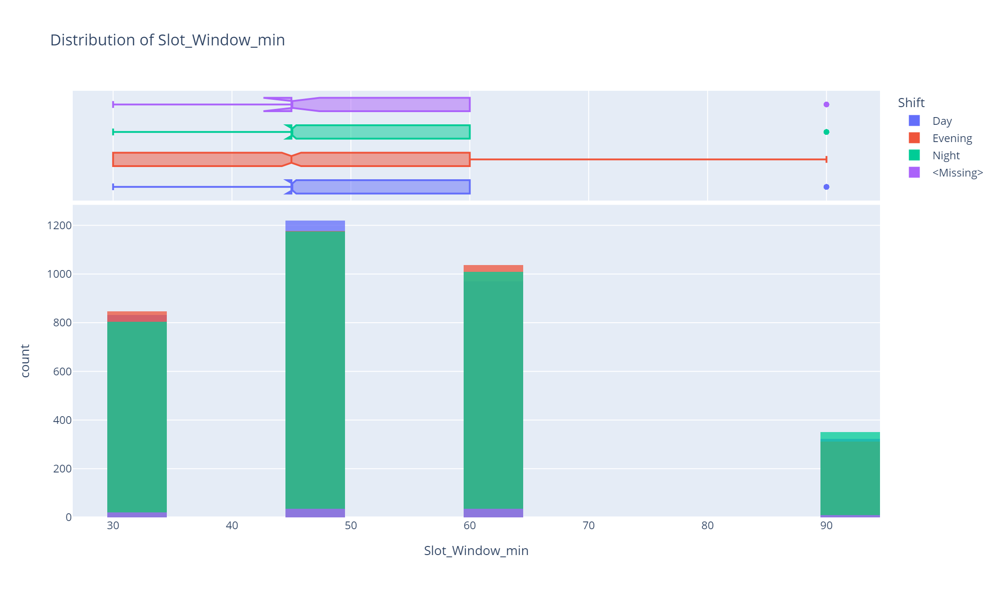

Slot_Window_min
  Skewness: 0.865
  Kurtosis: 0.348 (Normal/Low tail risk)


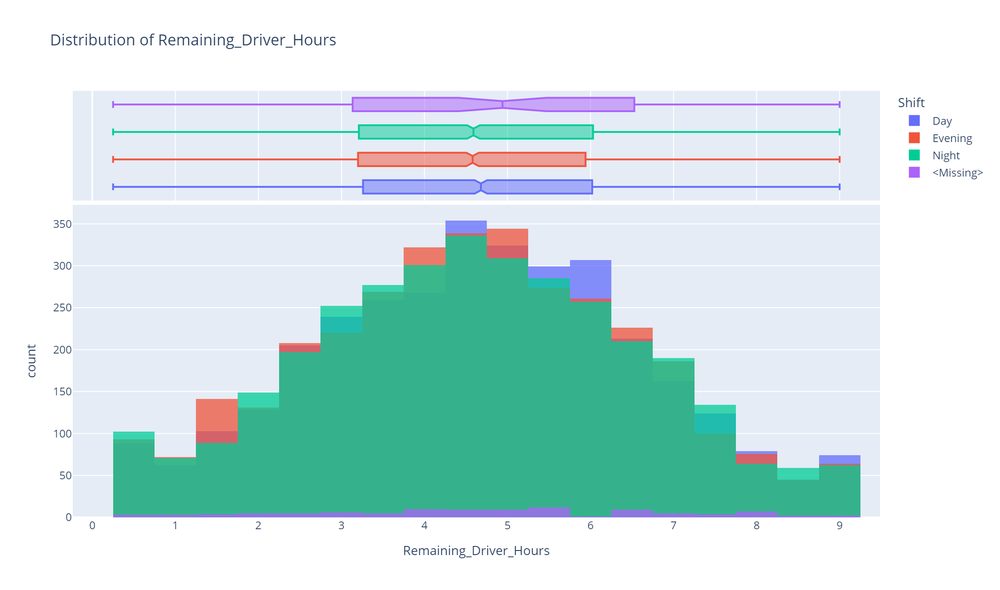

Remaining_Driver_Hours
  Skewness: -0.023
  Kurtosis: -0.454 (Normal/Low tail risk)


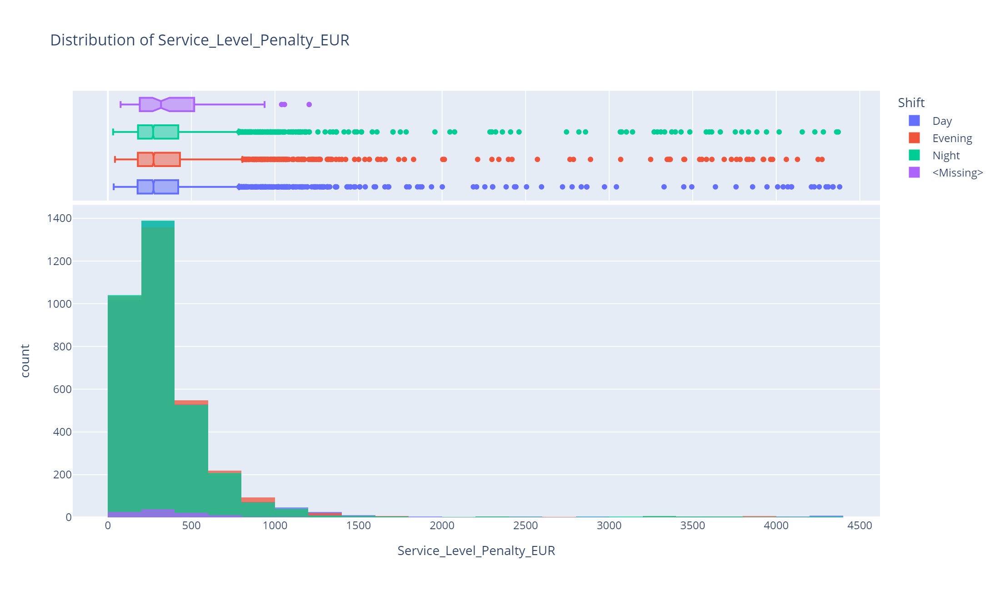

Service_Level_Penalty_EUR
  Skewness: 5.674
  Kurtosis: 43.172 (High tail risk)


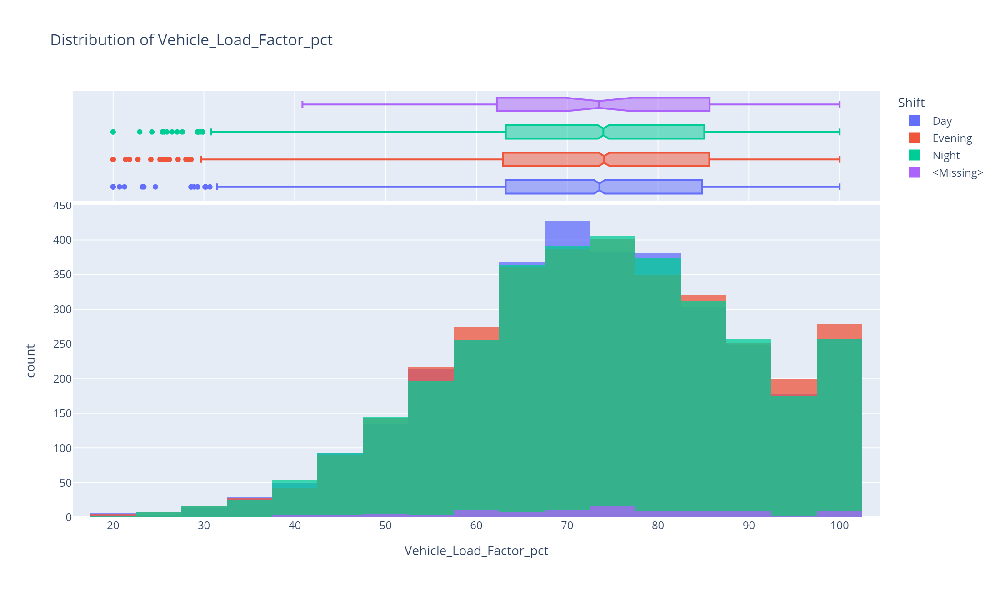

Vehicle_Load_Factor_pct
  Skewness: -0.276
  Kurtosis: -0.324 (Normal/Low tail risk)


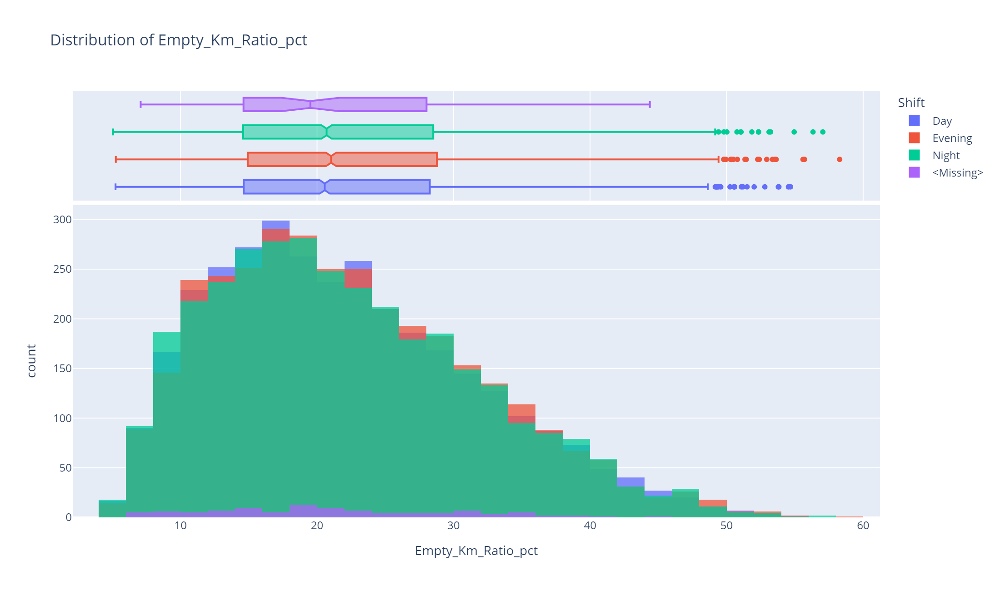

Empty_Km_Ratio_pct
  Skewness: 0.590
  Kurtosis: -0.164 (Normal/Low tail risk)


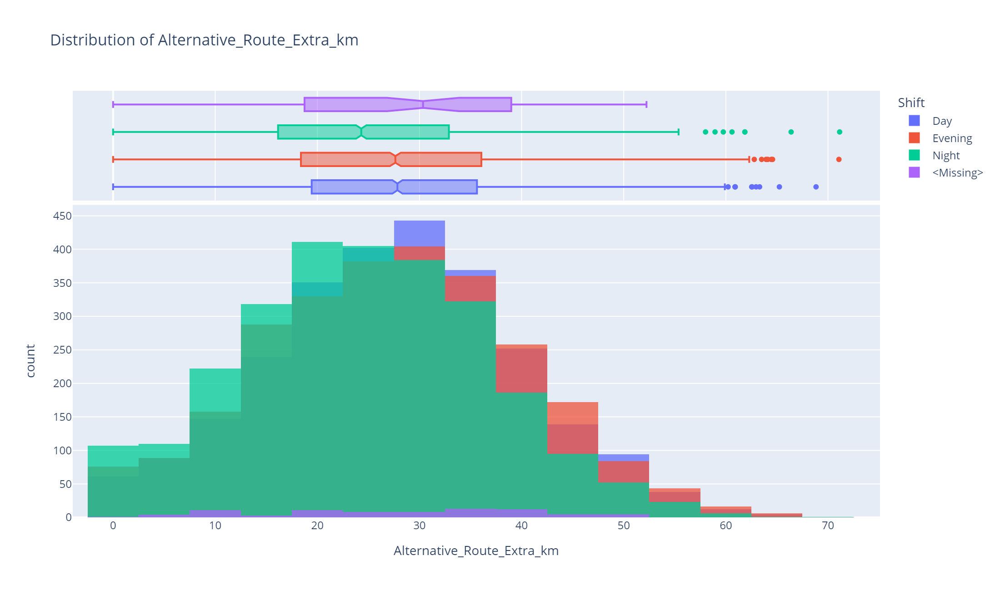

Alternative_Route_Extra_km
  Skewness: 0.065
  Kurtosis: -0.260 (Normal/Low tail risk)


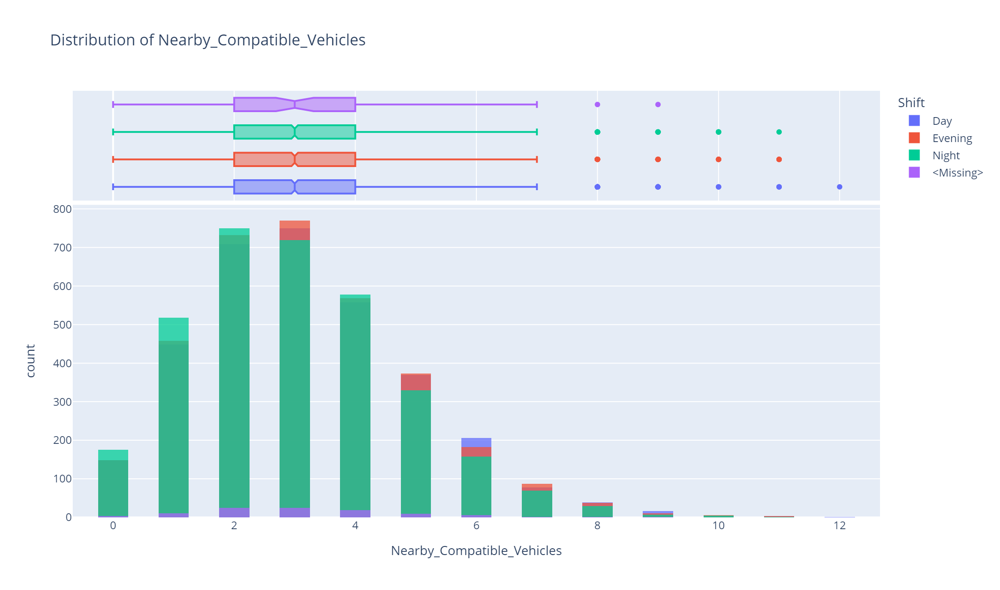

Nearby_Compatible_Vehicles
  Skewness: 0.634
  Kurtosis: 0.546 (Normal/Low tail risk)


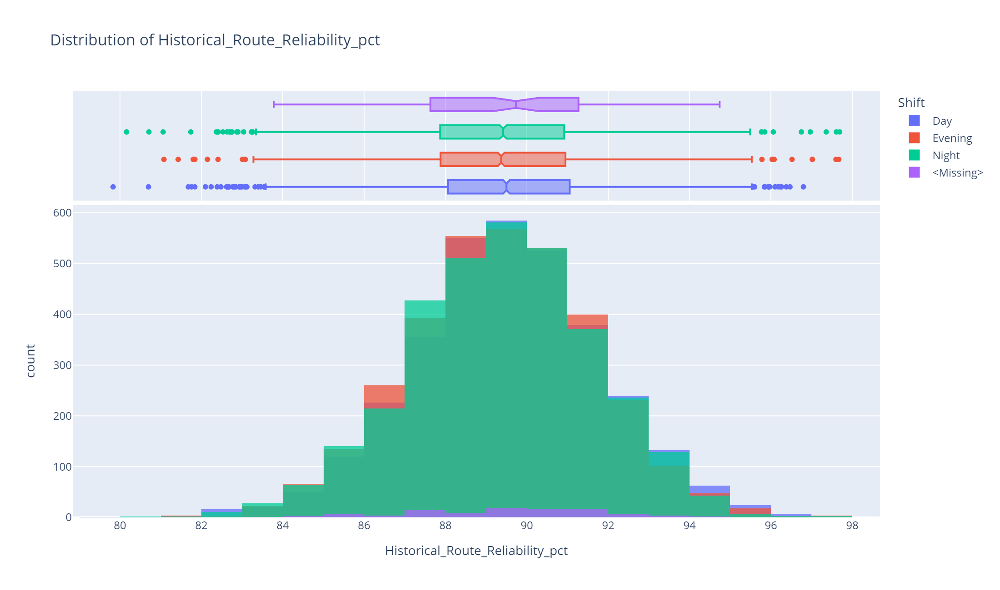

Historical_Route_Reliability_pct
  Skewness: -0.087
  Kurtosis: 0.155 (Normal/Low tail risk)


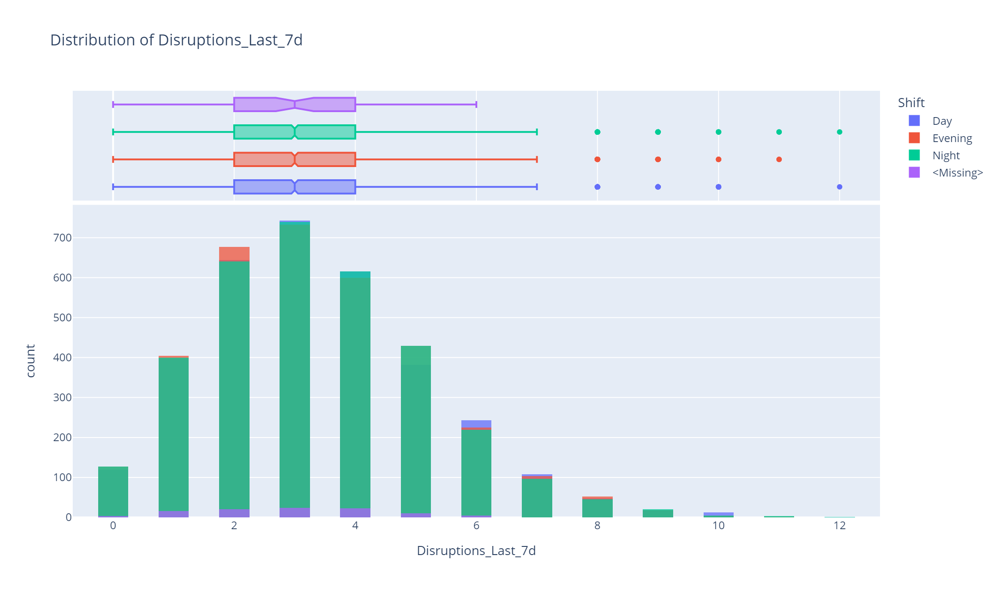

Disruptions_Last_7d
  Skewness: 0.561
  Kurtosis: 0.345 (Normal/Low tail risk)


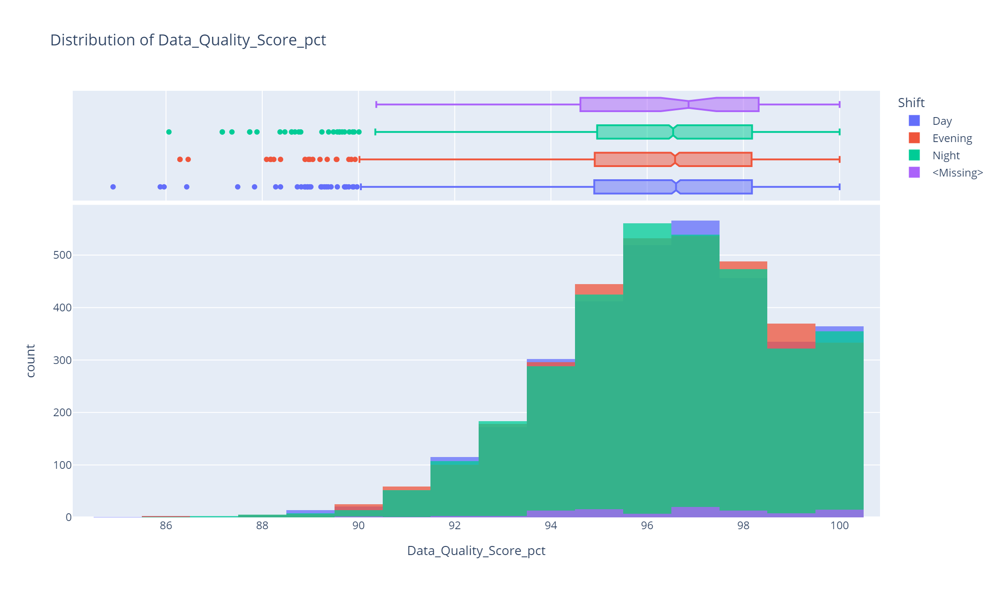

Data_Quality_Score_pct
  Skewness: -0.516
  Kurtosis: 0.132 (Normal/Low tail risk)


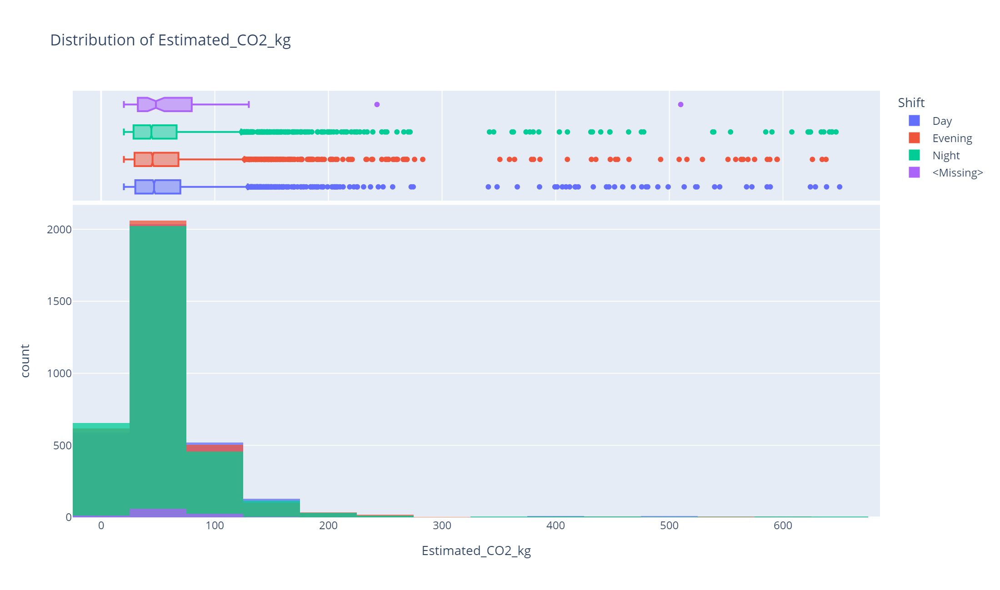

Estimated_CO2_kg
  Skewness: 5.489
  Kurtosis: 42.256 (High tail risk)


In [28]:
for col in numeric_plot_columns:
    plot_df = df.copy()

    # Treat low-cardinality hue variables as categories rather than continuous
    # color scales. This is especially useful for 0/1 target variables.
    color_col = hue_col
    if color_col is not None:
        plot_df[color_col] = plot_df[color_col].astype("string").fillna("<Missing>")

    fig = px.histogram(
        plot_df,
        x=col,
        color=color_col,
        nbins=30,
        marginal="box",
        opacity=0.75,
        barmode="overlay" if color_col is not None else "relative",
        title=f"Distribution of {col}",
    )
    show_plotly(fig)

    skew_val = df[col].skew()
    kurt_val = df[col].kurt()
    
    kurtosis_flag = "High" if kurt_val > 3 else "Normal/Low"
    
    print(f"{col}")
    print(f"  Skewness: {skew_val:.3f}")
    print(f"  Kurtosis: {kurt_val:.3f} ({kurtosis_flag} tail risk)")

Remark: Skewness & Kurtosis Analysis

| Feature | Skewness | Kurtosis | Tail Risk | What it means |
|---|---|---|---|---|
| `Distance_to_Terminal_km` | 5.26 | 39.04 | **High** | Heavy right tail. Extreme distances exist. |
| `Gate_Processing_Time_min` | 5.30 | 42.80 | **High** | Heavy right tail. Extreme wait times. |
| `Service_Level_Penalty_EUR` | 5.67 | 43.17 | **High** | Heavy right tail. Massive penalties. |
| `Estimated_CO2_kg` | 5.49 | 42.26 | **High** | Heavy right tail. Heavy emissions outliers. |
| `Current_delay_min` | 3.7 | 24.7 | **High** | Heavy right tail. |
| `Weather_Severity_Index` | 1.42 | 2.17 | Normal | Mild right skew |
| `Expected_Disruption_Duration_min` | 1.02 | 1.05 | Normal | Slight right skew. |
| `Queue_Length_vehicles` | 0.56 | 0.73 | Normal | Fairly balanced. |
| `Slot_Window_min` | 0.87 | 0.35 | Normal | Discrete steps. No extreme tails. |
| `ETA_Uncertainty_min` | 0.53 | 0.61 | Normal | Symmetric. Predictable. |
| `Road_Congestion_Index` | 0.44 | -0.31 | Normal | Very flat. No tail risk. |
| `Remaining_Driver_Hours` | -0.02 | -0.45 | Normal | Perfectly symmetric. |
| `Vehicle_Load_Factor_pct` | -0.28 | -0.32 | Normal | Slight left skew. |
| `Empty_Km_Ratio_pct` | 0.59 | -0.16 | Normal | Balanced. |
| `Alternative_Route_Extra_km` | 0.07 | -0.26 | Normal | Symmetric. |
| `Nearby_Compatible_Vehicles` | 0.63 | 0.55 | Normal | Discrete counts. |
| `Historical_Route_Reliability_pct` | -0.09 | 0.16 | Normal | Symmetric. |
| `Disruptions_Last_7d` | 0.56 | 0.35 | Normal | Discrete counts. |
| `Data_Quality_Score_pct` | -0.52 | 0.13 | Normal | Slight left skew. |
| `Slot_Buffer_min` | -0.60 | 0.56 | Normal | Slight left skew. |

**Takeaway:** Only five features cross the Kurtosis > 3 threshold. They all share the same profile: massive right skew (Skewness > 3.7) and heavy tails (Kurtosis > 24). log transformation can be needed for the 5 features that have heavy tails. Other features can be kept as they are.

#### Interactive density plot for selected numerical variables

To keep the figure readable, the template overlays at most three numerical variables. The curves are calculated with SciPy's kernel density estimation (KDE) and displayed interactively with Plotly.

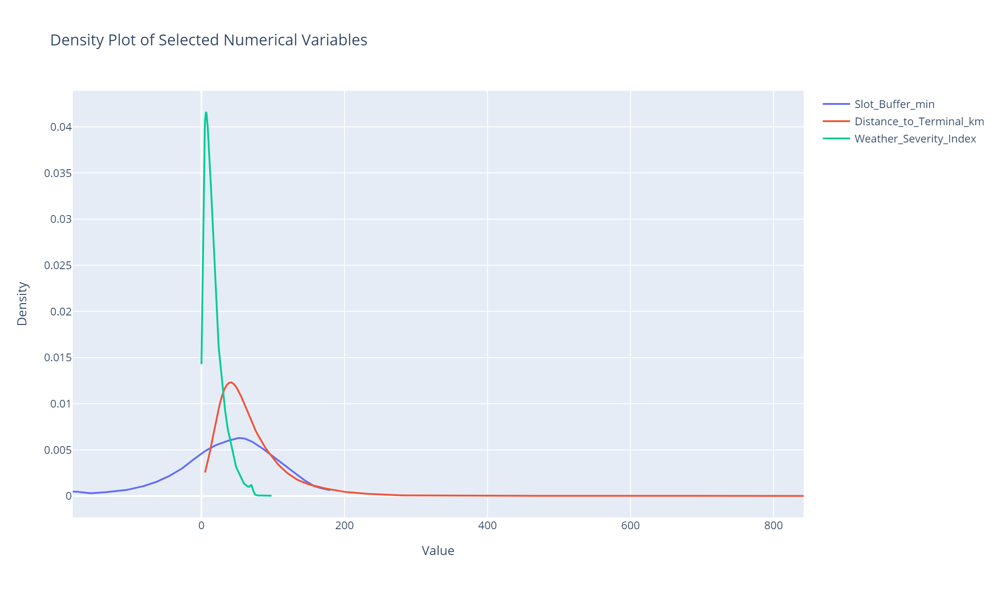

In [29]:
density_columns = numeric_plot_columns[:3]

if not density_columns:
    print("No numerical variables available for a density plot.")
else:
    fig = go.Figure()

    for col in density_columns:
        clean_values = df[col].dropna().astype(float)

        # KDE requires at least two observations and non-zero variation.
        if len(clean_values) >= 2 and clean_values.nunique() > 1:
            kde = gaussian_kde(clean_values)
            x_grid = np.linspace(clean_values.min(), clean_values.max(), 250)
            density = kde(x_grid)

            fig.add_trace(
                go.Scatter(
                    x=x_grid,
                    y=density,
                    mode="lines",
                    name=col,
                    hovertemplate="Value=%{x:.3f}<br>Density=%{y:.4f}<extra>%{fullData.name}</extra>",
                )
            )

    if len(fig.data) == 0:
        print("Selected numerical variables do not have enough variation for KDE.")
    else:
        fig.update_layout(
            title="Density Plot of Selected Numerical Variables",
            xaxis_title="Value",
            yaxis_title="Density",
            hovermode="x unified",
        )
        show_plotly(fig)


remark: 
- plotted just an example of a density plot for visualization purpose. 

- Analysis of skewness and kurtosis was derived after computing their respective values using .kurt() and .skew() functions.

- histograms above along with violin plots were plotted above to visualize the data distributions


#### Interactive z-score distribution for potential outlier detection

A z-score measures how many standard deviations an observation lies from the mean. Values beyond approximately **±3** are often inspected as potential outliers, but they should not be removed automatically.

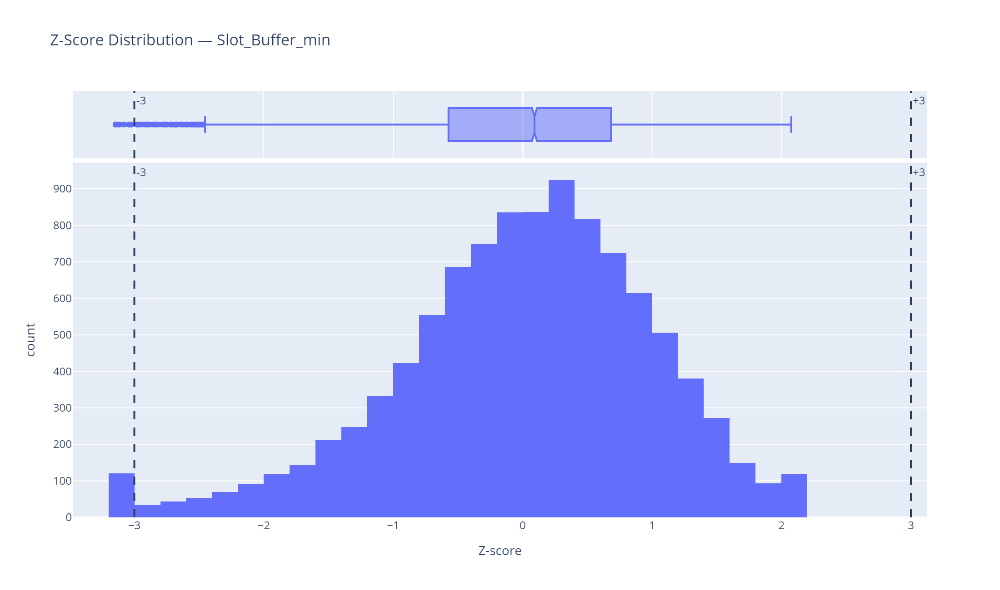

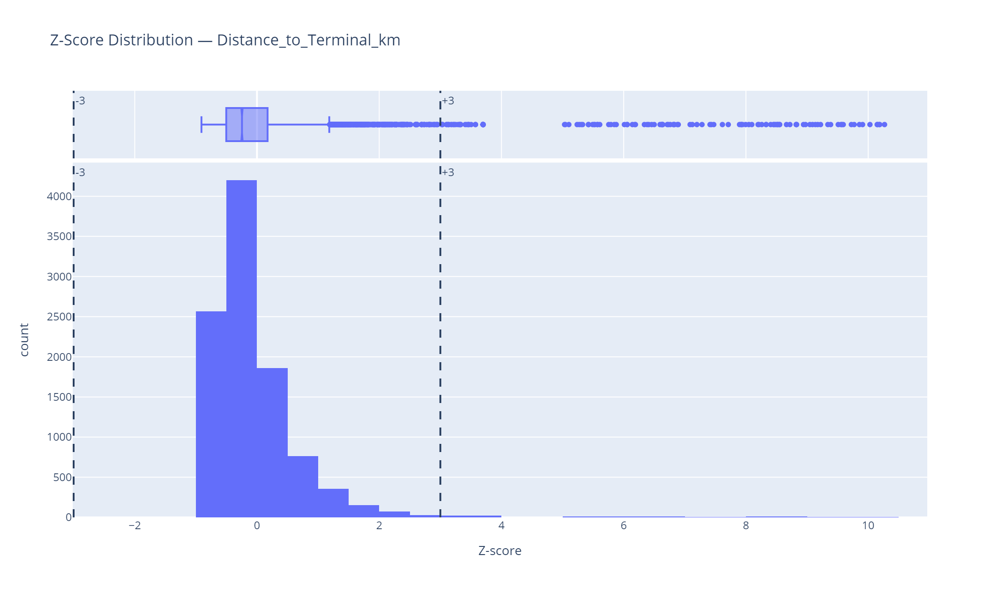

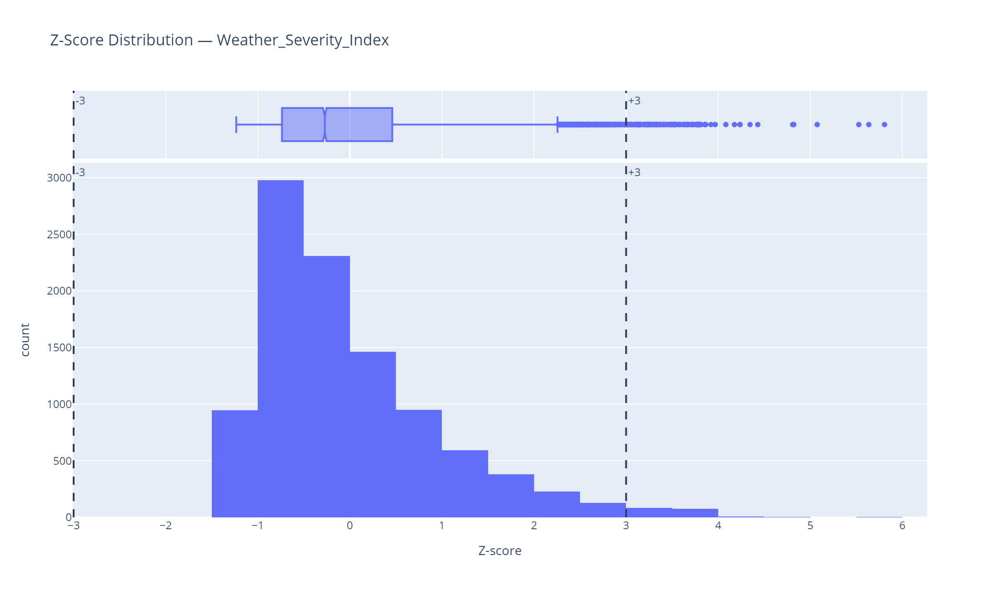

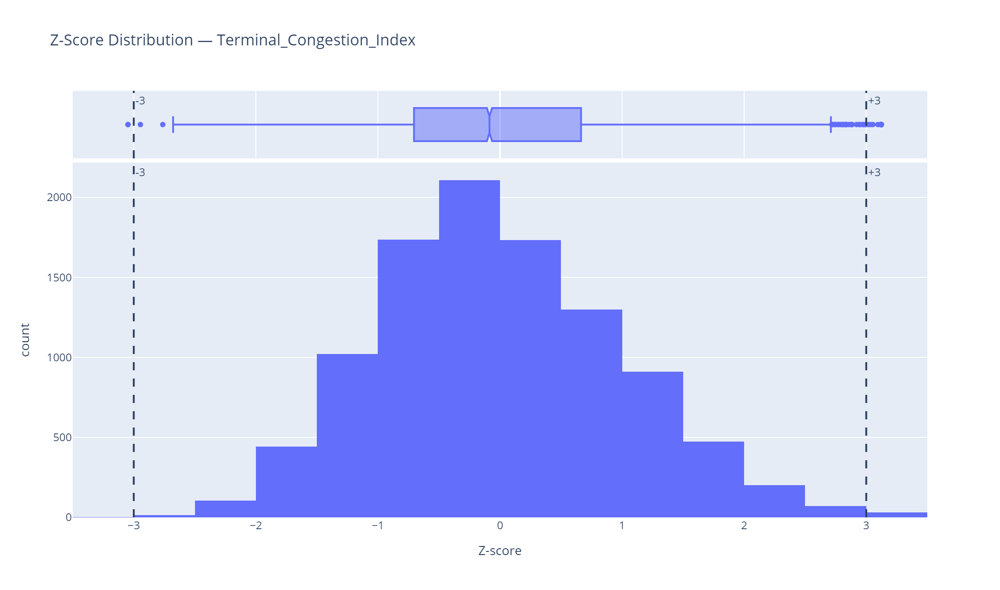

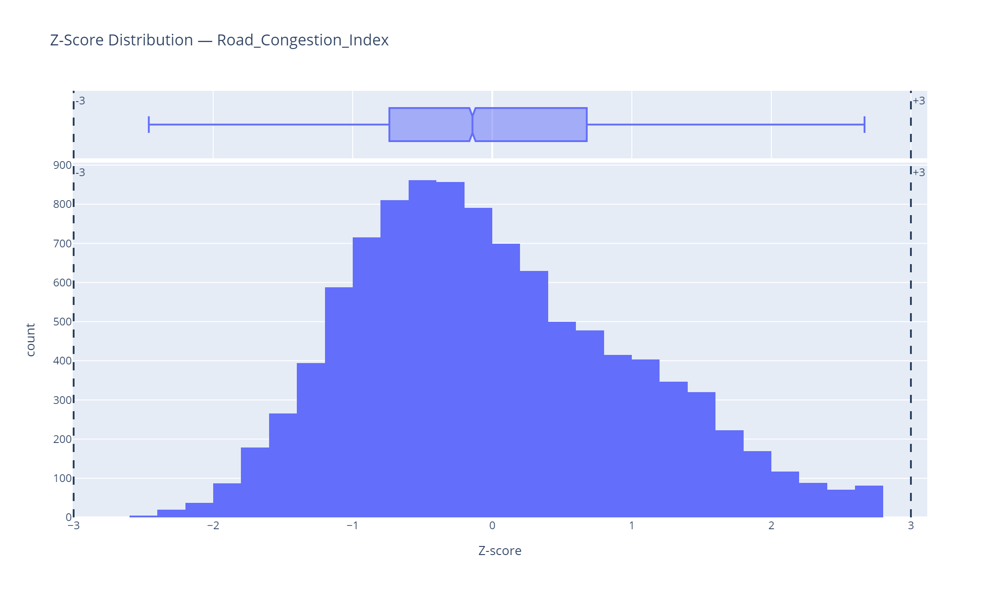

...

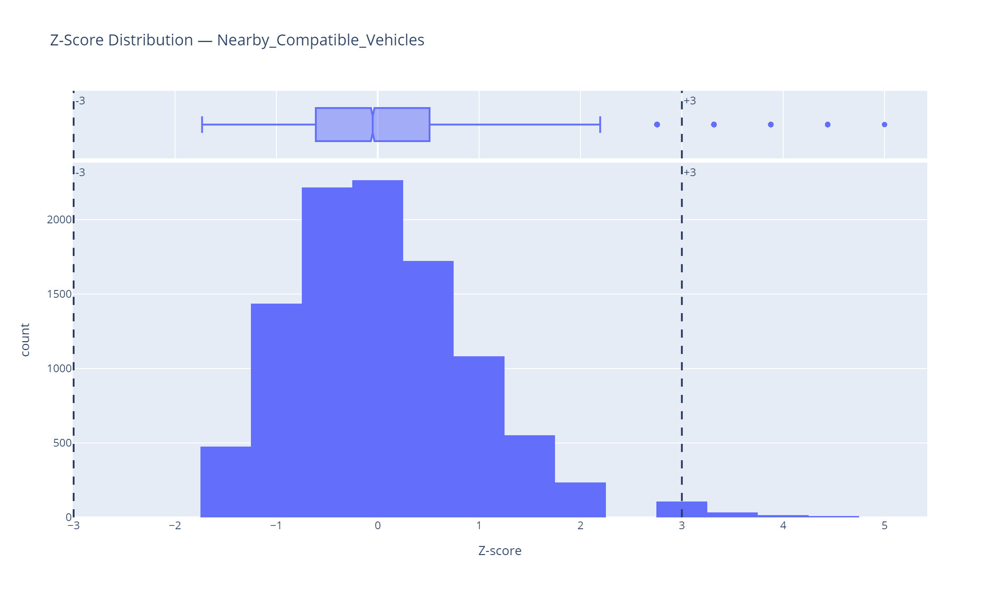

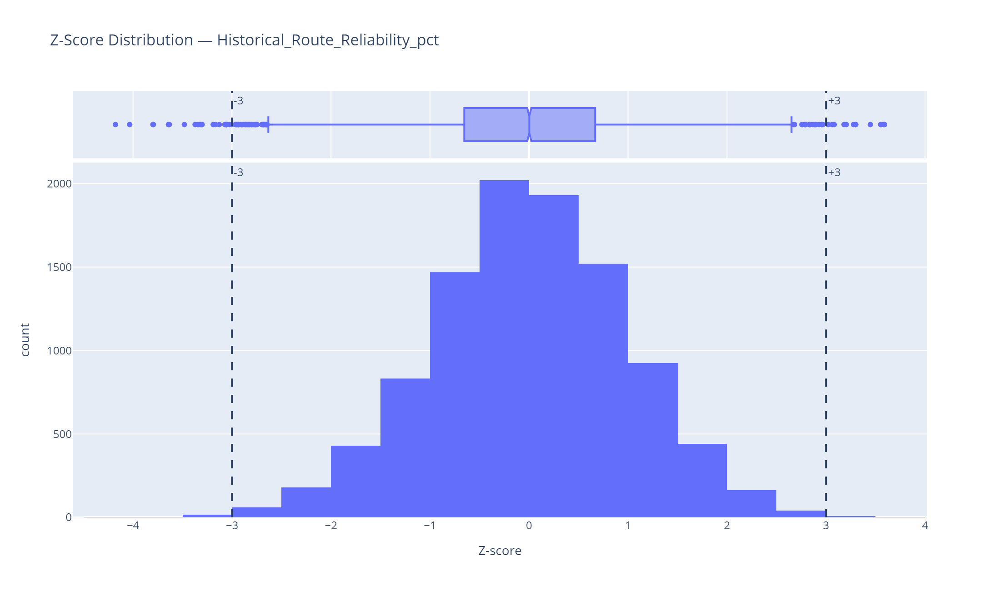

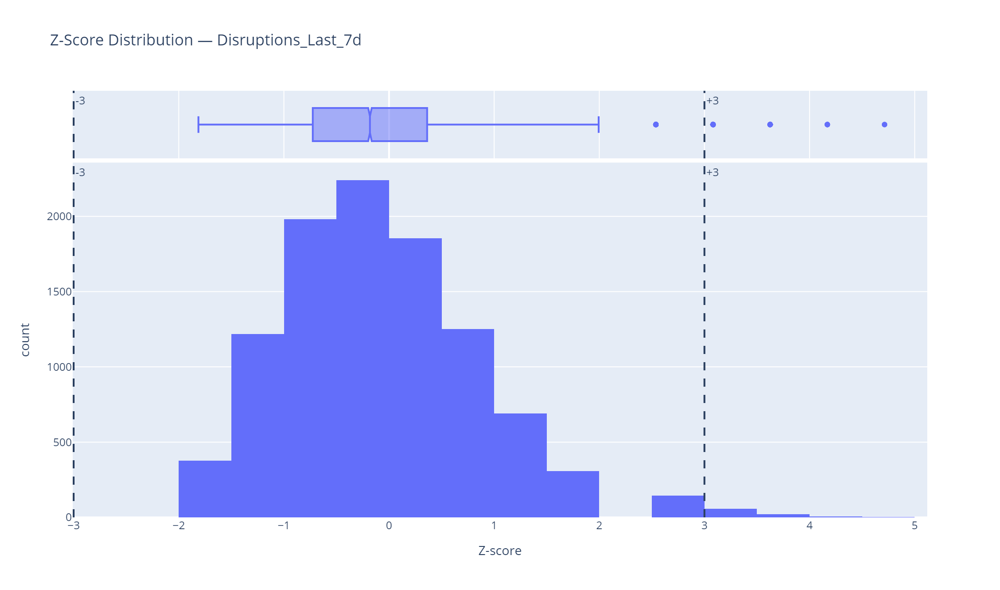

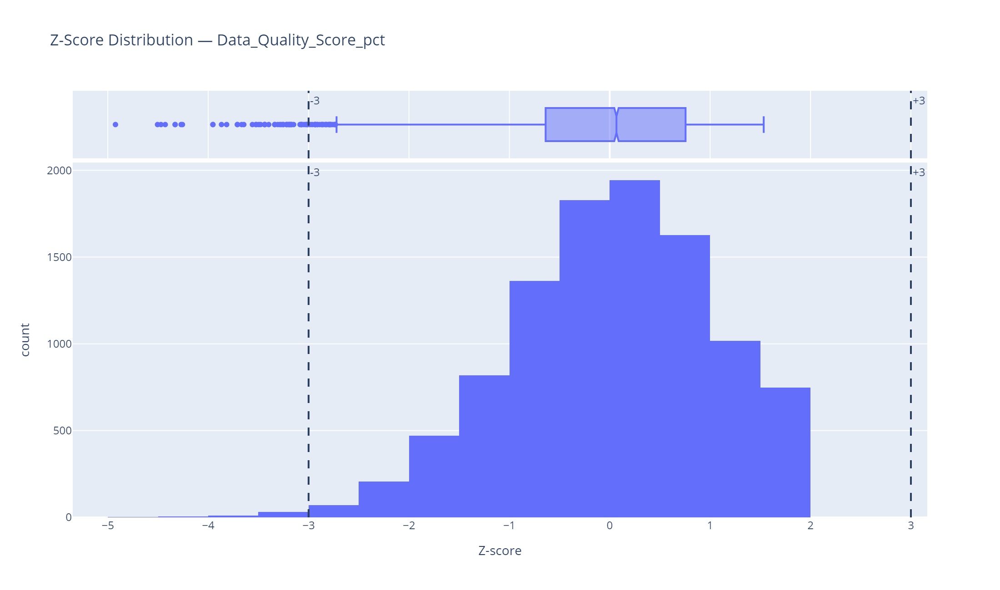

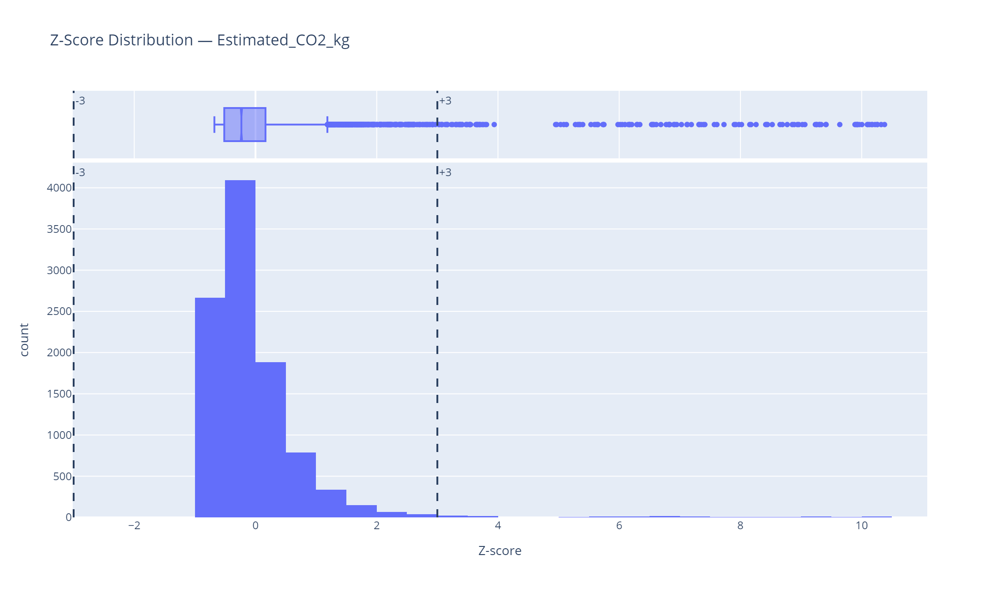

In [30]:
for col in numeric_plot_columns:
    clean_values = df[col].dropna().astype(float)

    if len(clean_values) < 2 or clean_values.nunique() <= 1:
        print(f"Skipping {col}: insufficient variation for z-scores.")
        continue

    # Calculate z-scores without adding a temporary column to the original df.
    z_values = zscore(clean_values, nan_policy="omit")
    z_df = pd.DataFrame({"Z-score": z_values})

    fig = px.histogram(
        z_df,
        x="Z-score",
        nbins=30,
        marginal="box",
        title=f"Z-Score Distribution — {col}",
    )
    fig.add_vline(x=-3, line_dash="dash", annotation_text="-3")
    fig.add_vline(x=3, line_dash="dash", annotation_text="+3")
    show_plotly(fig)


insights:
- **Heavy-Tailed Features:** `Distance_to_Terminal_km`, `Gate_Processing_Time_min`, `Current_Delay_min`, `Service_Level_Penalty_EUR`, and `Estimated_CO2_kg` have massive right tails stretching well past the +3 Z-score line, confirming extreme outliers that will need capping or log transforms.
- **Bounded Features:** `Terminal_Congestion_Index` and `Yard_Occupancy_pct` stay bounded. While a few points slightly breach the ±3 threshold, the majority of the data is in the normal range.

> **Student checkpoint:** For one numerical variable, describe its typical value, spread, skewness, and possible outliers. Then explain why these patterns might matter in a supply-chain decision.


answer to student checkpoint:

**`Current_Delay_min`**:
- **Typical Value & Spread:** The median delay is around 22 minutes, with the middle 50% of cases (IQR) ranging roughly between 9 and 36 minutes.
- **Skewness & Outliers:** The distribution is heavily right-skewed. While most shipments have short delays, the long tail contains massive outliers stretching past 250 minutes.
- **Why it matters:** In a supply-chain decision, planning around the *average* delay would be a mistake. Because the distribution is so skewed, operations must build buffers to handle the routine 20-30 minute delays, but also have contingency plans (like alternative routing) to absorb the rare but catastrophic 4-hour delays that could ruin a tight delivery schedule

## 5. Step 4 — Understand relationships among variables (multivariate analysis)

Multivariate analysis asks whether variables move together, form groups, or show potentially useful relationships. The interactive Plotly charts in this section let you zoom, filter, hover, and isolate categories while exploring those relationships.

### 5.1 Interactive scatter plot

The notebook automatically uses the first two suitable numerical variables, preferring the original customer-data example when those columns exist. Hover reveals observation-level values, while zooming helps inspect dense regions.

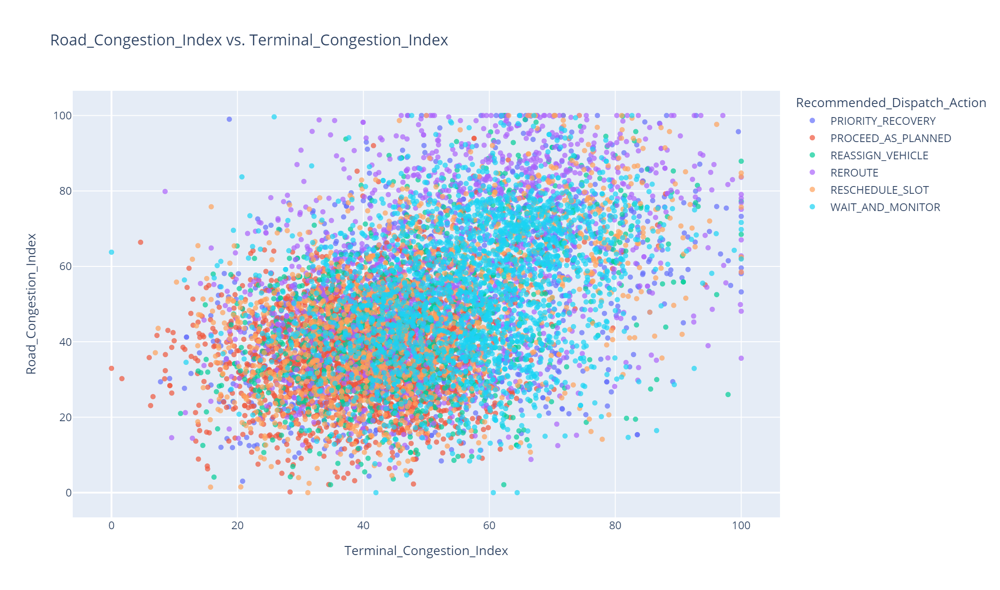

In [31]:
# Prefer the original teaching example when those columns exist.
scatter_x = "Terminal_Congestion_Index" if "Terminal_Congestion_Index" in numeric_columns else (
    numeric_columns[0] if len(numeric_columns) >= 1 else None
)
scatter_y = "Road_Congestion_Index" if "Road_Congestion_Index" in numeric_columns else (
    numeric_columns[1] if len(numeric_columns) >= 2 else None
)

# Use target as color when available; otherwise use the configured hue variable.
scatter_hue = TARGET_COLUMN

if scatter_x is None or scatter_y is None:
    print("At least two numerical variables are required for a scatter plot.")
else:
    plot_df = df.copy()

    if scatter_hue is not None:
        # Cast low-cardinality targets such as 0/1 to strings so Plotly treats
        # them as categories and provides a categorical legend.
        plot_df[scatter_hue] = plot_df[scatter_hue].astype("string").fillna("<Missing>")

    fig = px.scatter(
        plot_df,
        x=scatter_x,
        y=scatter_y,
        color=scatter_hue,
        opacity=0.7,
        title=f"{scatter_y} vs. {scatter_x}",
        hover_data=[c for c in [group_col, hue_col] if c is not None and c in plot_df.columns],
    )
    show_plotly(fig)


remark: 
- here i plotted a scatter plot of the target variable (categories as different colours) w.r.t 'Road_Congestion_Index' and 'Terminal_Congestion_Index' just to explore whether increasing both these values can determine a specific category of the target.

- The dispatch actions ( distinct categories of target variable) are heavily mixed in the feature space,
so it is clear that our feature space in this case cannot dictate the recommended dispatch action, and therefore other features are needed.

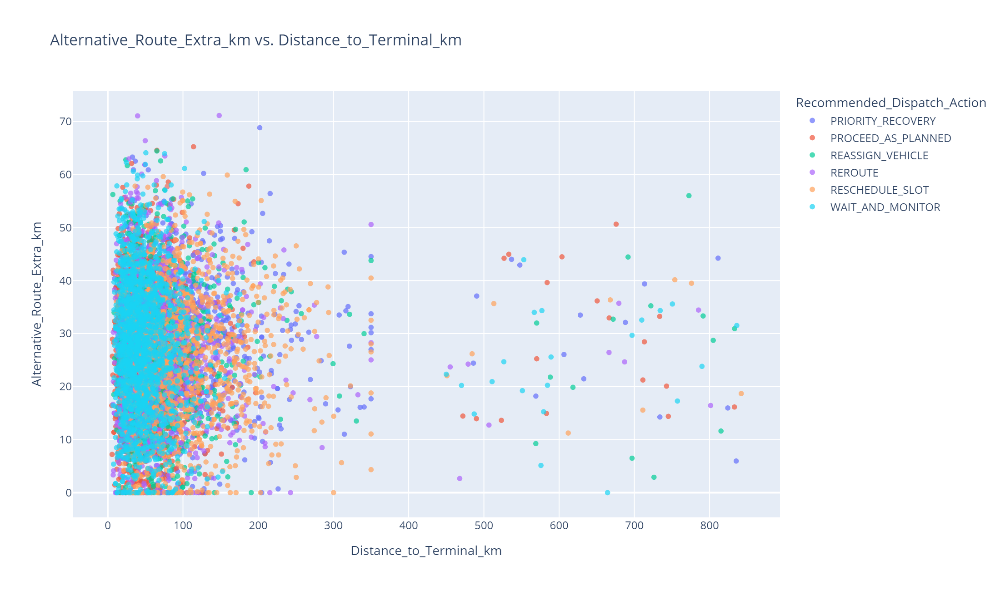

In [32]:
# Prefer the original teaching example when those columns exist.
scatter_x = "Distance_to_Terminal_km" if "Distance_to_Terminal_km" in numeric_columns else (
    numeric_columns[0] if len(numeric_columns) >= 1 else None
)
scatter_y = "Alternative_Route_Extra_km" if "Alternative_Route_Extra_km" in numeric_columns else (
    numeric_columns[1] if len(numeric_columns) >= 2 else None
)

# Use target as color when available; otherwise use the configured hue variable.
scatter_hue = TARGET_COLUMN

if scatter_x is None or scatter_y is None:
    print("At least two numerical variables are required for a scatter plot.")
else:
    plot_df = df.copy()

    if scatter_hue is not None:
        # Cast low-cardinality targets such as 0/1 to strings so Plotly treats
        # them as categories and provides a categorical legend.
        plot_df[scatter_hue] = plot_df[scatter_hue].astype("string").fillna("<Missing>")

    fig = px.scatter(
        plot_df,
        x=scatter_x,
        y=scatter_y,
        color=scatter_hue,
        opacity=0.7,
        title=f"{scatter_y} vs. {scatter_x}",
        hover_data=[c for c in [group_col, hue_col] if c is not None and c in plot_df.columns],
    )
    show_plotly(fig)


remark: 
- again here, our  new feature space cannot dictate the recommended dispatch action.

### 5.2 Interactive scatter-matrix / pair plot

Pair plots become expensive when there are many rows or variables. The template therefore samples rows **only for visualization** and limits the matrix to five numerical variables. Drag inside a panel to zoom; use the legend to isolate groups.

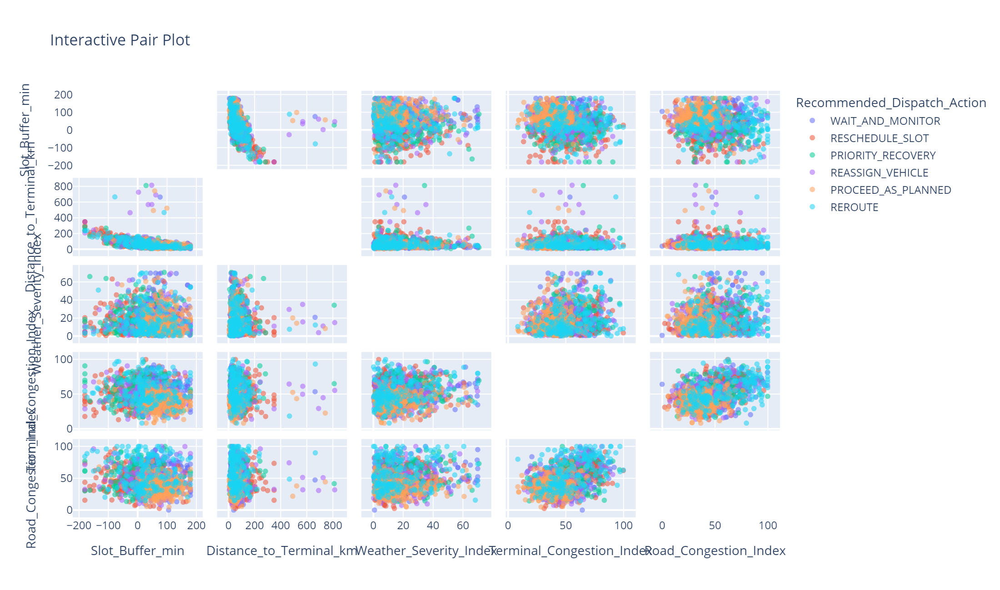

In [34]:
pair_columns = numeric_plot_columns[:5]

if len(pair_columns) < 2:
    print("At least two numerical variables are required for a pair plot.")
else:
    pair_df = df.sample(
        min(PAIRPLOT_MAX_ROWS, len(df)),
        random_state=42,
    ).copy()

    # Use a categorical color only when the candidate has a manageable
    # number of classes.
    pair_hue = None
    candidate_hue = target_col or hue_col
    if (
        candidate_hue in pair_df.columns
        and pair_df[candidate_hue].nunique(dropna=True) <= 10
    ):
        pair_hue = candidate_hue
        pair_df[pair_hue] = pair_df[pair_hue].astype("string").fillna("<Missing>")

    fig = px.scatter_matrix(
        pair_df,
        dimensions=pair_columns,
        color=pair_hue,
        title="Interactive Pair Plot",
        opacity=0.55,
    )
    fig.update_traces(diagonal_visible=False)
    fig.update_layout(height=800)
    show_plotly(fig)


remark:

- **Clear Separation in Slot_Buffer:** The relationship between `Slot_Buffer_min` and `Distance_to_Terminal_km` shows a distinct L-shape. Short distances allow for both positive buffers (slack) and negative buffers (missed slots). However, as distance increases, the buffer strictly drops—you can't have a massive time buffer if you're 800 km away.
- **The "Action Blob":** Across most scatter plots (e.g., Congestion vs. Congestion, Weather vs. Congestion), the six different dispatch actions are heavily mixed into a dense, overlapping blob. This proves that no single pair of variables can cleanly separate the target classes. It justifies why a complex, multi-feature Machine Learning model can be needed here.
- **The "Wait and Monitor" Cluster:** In the `Slot_Buffer_min` vs. `Distance_to_Terminal_km` plot, `WAIT_AND_MONITOR` (light blue) forms a highly concentrated, tight cluster near zero distance and negative buffer. 
- **REROUTE outliers:** `REROUTE` (purple) tends to appear as scattered outliers at the fringes of distributions, especially in plots involving `Distance_to_Terminal_km` and `Weather_Severity_Index`. This implies rerouting is an action reserved for extreme(edge) cases.

### 5.3 Focused interactive scatter-plot matrix

This second matrix uses up to four numerical variables and no grouping color. It is useful for concentrating on the shape and direction of pairwise relationships without categorical coloring.

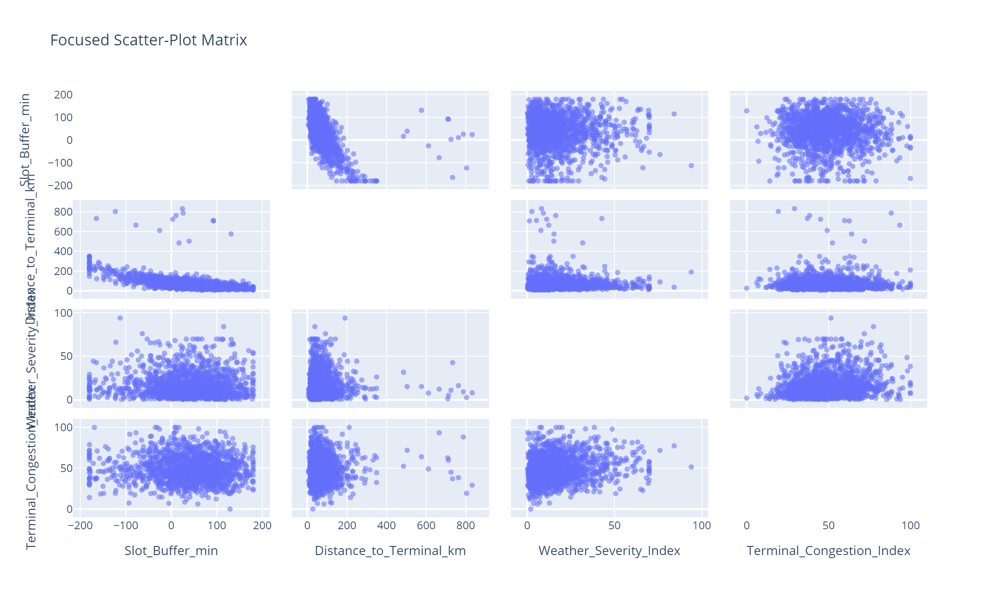

In [35]:
scatter_matrix_columns = numeric_plot_columns[:4]

if len(scatter_matrix_columns) < 2:
    print("At least two numerical variables are required for a scatter matrix.")
else:
    matrix_df = df[scatter_matrix_columns].dropna()

    if len(matrix_df) > PAIRPLOT_MAX_ROWS:
        matrix_df = matrix_df.sample(PAIRPLOT_MAX_ROWS, random_state=42)

    fig = px.scatter_matrix(
        matrix_df,
        dimensions=scatter_matrix_columns,
        title="Focused Scatter-Plot Matrix",
        opacity=0.55,
    )
    fig.update_traces(diagonal_visible=False)
    fig.update_layout(height=750)
    show_plotly(fig)


exactly the same as scatter-matrix but without the target variable.

it focuses on the single relationships between the features without the need of target categorical grouping

### 5.4 Interactive correlation heatmaps

We compare three coefficients:

- **Pearson:** linear association. (will be applied for interval, ratio variables)
- **Spearman:** monotonic association based on ranks. (will be applied for ordinal, interval and ratio variables)
- **Kendall:** rank concordance, often useful with small samples or many tied ranks. (will be applied for ordinal, interval and ratio variables)

Hover over a cell to inspect the exact coefficient. Remember: **correlation does not imply causation**.

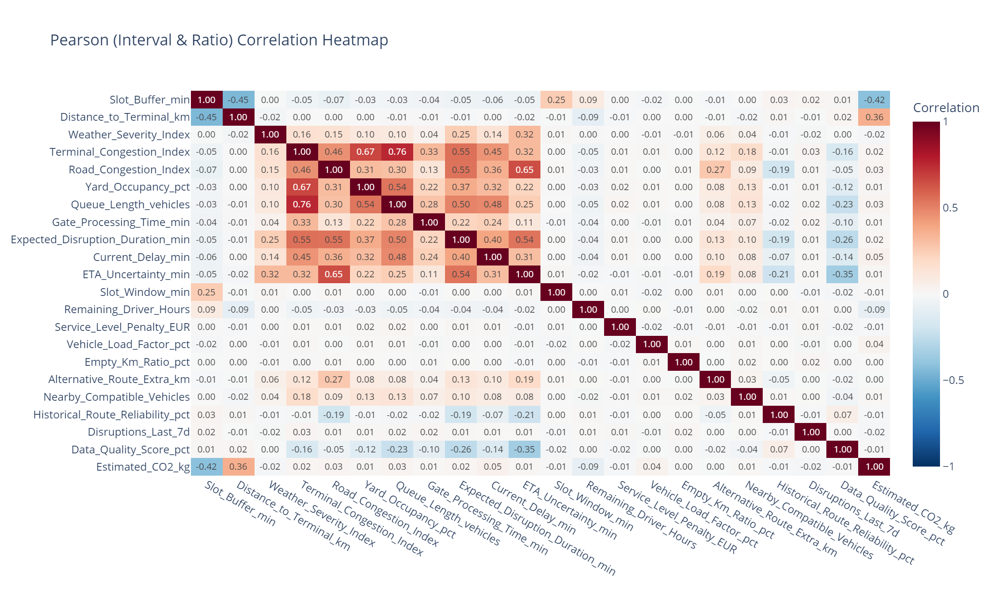

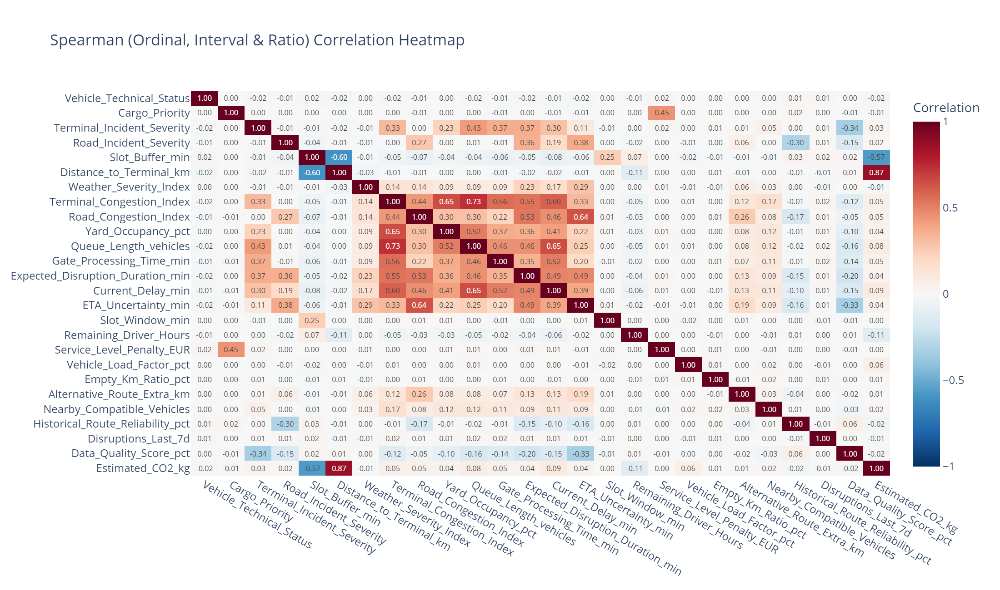

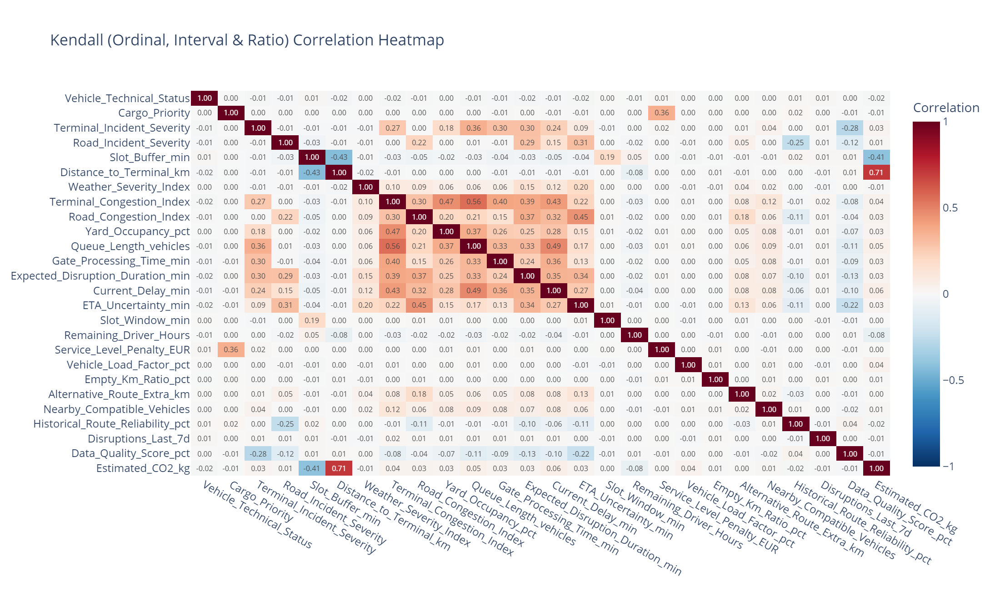

In [37]:
# 1. Create a temporary numeric copy for the correlation math
df_corr = df.copy()

# 2. Map the ordinal string categories to integers for column "Vehicle_Technical_Status"
df_corr['Vehicle_Technical_Status'] = df_corr['Vehicle_Technical_Status'].map(
    {'OK': 0, 'Warning': 1, 'Critical': 2}
)
pearson_cols = [c for c in (INTERVAL + RATIO) if c in df_corr.columns]
rank_cols = [c for c in (ORDINAL + INTERVAL + RATIO) if c in df_corr.columns]

if len(pearson_cols) < 2:
    print("At least two continuous variables are required for correlation analysis.")
else:
    for method, label, cols in [
        ("pearson", "Pearson (Interval & Ratio)", pearson_cols),
        ("spearman", "Spearman (Ordinal, Interval & Ratio)", rank_cols),
        ("kendall", "Kendall (Ordinal, Interval & Ratio)", rank_cols),
    ]:
        if len(cols) < 2:
            continue
            
        # Use df_corr here, not df
        correlation_matrix = df_corr[cols].corr(method=method)

        fig = px.imshow(
            correlation_matrix,
            text_auto=".2f",
            aspect="auto",
            zmin=-1,
            zmax=1,
            color_continuous_scale="RdBu_r",
            title=f"{label} Correlation Heatmap",
            labels={"color": "Correlation"},
        )
        fig.update_layout(height=750)
        show_plotly(fig)

remark:

- **Congestion is a cluster:** `Terminal_Congestion_Index`, `Road_Congestion_Index`, `Yard_Occupancy_pct`, `Queue_Length_vehicles`, and `Expected_Disruption_Duration_min` are all strongly positively correlated (dark red blocks). When a terminal is busy, the roads are busy, the yard is full, and queues are long. They move together as a single "operational stress" system.
- **The Distance Penalty:** `Distance_to_Terminal_km` has a strong negative correlation with `Slot_Buffer_min` (-0.45 Pearson, -0.60 Spearman). This mathematically proves what we saw in the scatter plots: the further you are from the terminal, the less time buffer you have.
- **Pearson vs. Spearman differences:**  `Current_Delay_min` and `ETA_Uncertainty_min`. The Spearman correlation is stronger than the Pearson correlation. Because these features are heavily right-skewed with massive outliers (as we saw with the high kurtosis), and since Pearson is the most sensitive to outliers, its correlation coefficient value will be less than Spearman's (which uses ranks) captures the true monotonic relationship better.
- **The weird CO2 link:** `Estimated_CO2_kg` has a surprising negative correlation with `Slot_Buffer_min` (-0.42 Pearson, -0.57 Spearman) and a positive one with `Distance_to_Terminal_km`. Longer trips burn more fuel, and longer trips inherently have less scheduling slack.
- **The Priority Penalty:** In the Spearman heatmap, `Cargo_Priority` and `Service_Level_Penalty_EUR` are perfectly positively correlated (0.45). High-priority cargo comes with high financial penalties if you miss the slot. 
- **Surprisingly independent features:** `Weather_Severity_Index` has very weak correlations with almost everything (mostly light colors), meaning weather is a relatively independent variable in this dataset. `Remaining_Driver_Hours` and `Vehicle_Load_Factor_pct` are also mostly white, meaning they don't have strong linear ties to the congestion cluster.

### 5.5 Interactive parallel-coordinates plot

Parallel coordinates visualize several numerical dimensions simultaneously. Each polyline represents one sampled observation. Drag the axis ranges to filter observations interactively.

Color-code mapping:
  0: PRIORITY_RECOVERY
  1: PROCEED_AS_PLANNED
  2: REASSIGN_VEHICLE
  3: REROUTE
  4: RESCHEDULE_SLOT
  5: WAIT_AND_MONITOR


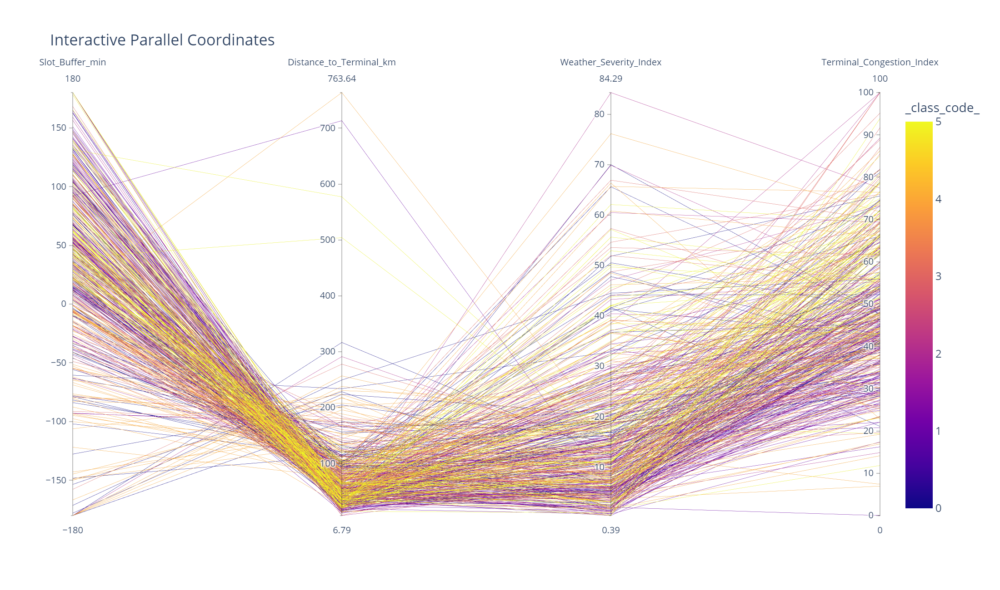

In [38]:
parallel_columns = numeric_plot_columns[:4]

if len(parallel_columns) < 2:
    print("At least two numerical variables are required for parallel coordinates.")
else:
    # Keep the plot readable and responsive by limiting displayed rows.
    parallel_df = df[parallel_columns].dropna()
    if len(parallel_df) > 500:
        parallel_df = parallel_df.sample(500, random_state=42)
    parallel_df = parallel_df.copy()

    candidate_class = target_col or hue_col
    color_column = None

    if (
        candidate_class in df.columns
        and df[candidate_class].nunique(dropna=True) <= 10
    ):
        # Plotly parallel coordinates uses a numerical color axis. Convert
        # categories into integer codes only in this temporary plotting table.
        class_values = (
            df.loc[parallel_df.index, candidate_class]
            .astype("string")
            .fillna("<Missing>")
        )
        category_codes, category_labels = pd.factorize(class_values, sort=True)
        parallel_df["_class_code_"] = category_codes
        color_column = "_class_code_"

        print("Color-code mapping:")
        for code, label in enumerate(category_labels):
            print(f"  {code}: {label}")

    fig = px.parallel_coordinates(
        parallel_df,
        dimensions=parallel_columns,
        color=color_column,
        title="Interactive Parallel Coordinates",
    )
    fig.update_layout(height=550)
    show_plotly(fig)


### 5.6 Interactive bubble chart

A bubble chart maps up to four pieces of information at once: x-position, y-position, bubble size, and optional color. Hover over a bubble to inspect the underlying observation.

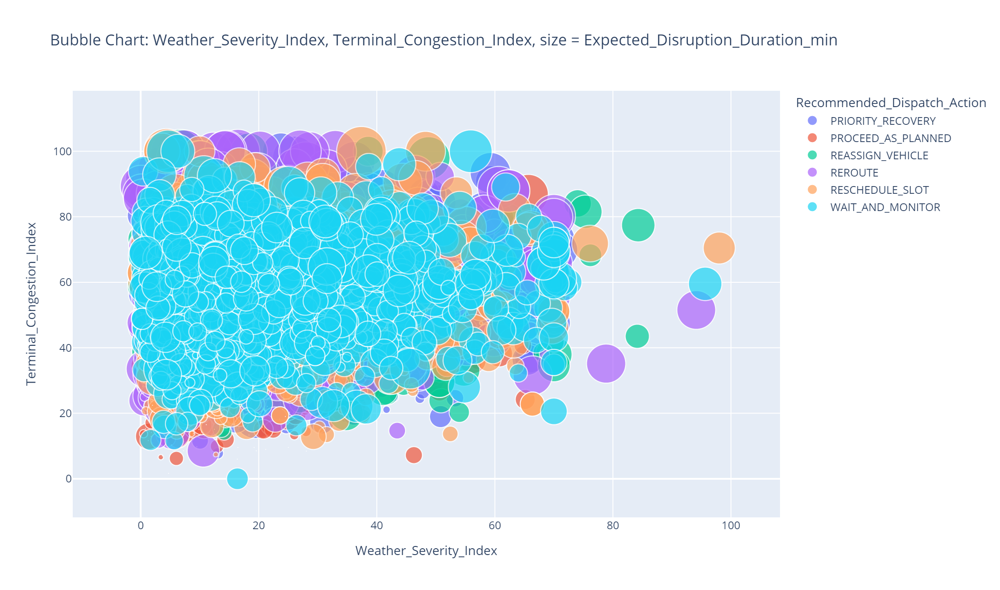

In [39]:
if len(numeric_columns) < 3:
    print("At least three numerical variables are required for a bubble chart.")
else:
    # Preserve the original teaching example when possible.
    bubble_x = "Weather_Severity_Index" if "Weather_Severity_Index" in numeric_columns else numeric_columns[0]
    bubble_y = "Terminal_Congestion_Index" if "Terminal_Congestion_Index" in numeric_columns else numeric_columns[1]
    bubble_size = "Expected_Disruption_Duration_min" if "Expected_Disruption_Duration_min" in numeric_columns else numeric_columns[2]

    bubble_color = TARGET_COLUMN

    needed_columns = [bubble_x, bubble_y, bubble_size]
    if bubble_color is not None:
        needed_columns.append(bubble_color)

    bubble_df = df[needed_columns].dropna(subset=[bubble_x, bubble_y, bubble_size]).copy()

    # Plotly requires non-negative bubble sizes. abs() makes the template robust
    # to datasets containing signed numerical measures.
    bubble_df["_bubble_size_"] = bubble_df[bubble_size].abs()

    if bubble_color is not None:
        bubble_df[bubble_color] = bubble_df[bubble_color].astype("string").fillna("<Missing>")

    fig = px.scatter(
        bubble_df,
        x=bubble_x,
        y=bubble_y,
        size="_bubble_size_",
        color=bubble_color,
        hover_data={bubble_size: True, "_bubble_size_": False},
        size_max=55,
        title=f"Bubble Chart: {bubble_x}, {bubble_y}, size = {bubble_size}",
    )
    show_plotly(fig)


# Step 6. Evaluate The significance of categorical Variables (Only Nominal variables) to the target column "Recommended_Dispatch_Action" which is nominal Using Cramer's V approach

In [40]:
print(categorical_plot_columns)

['Day_of_Week', 'Shift', 'Terminal_ID', 'Corridor_ID', 'Transport_Object_Type', 'Vehicle_Type', 'Trailer_Ready', 'Customs_Status', 'Alternative_Slot_Available', 'Alternative_Terminal_Available', 'Alternative_Route_Available', 'Driver_Change_Available', 'Vehicle_Technical_Status', 'Cargo_Priority', 'Terminal_Incident_Severity', 'Road_Incident_Severity']


In [41]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

TARGET = "Recommended_Dispatch_Action"


def classify_cramers_v(v, dof):
    """Classify Cramér's V using the course rubric (Cohen's w / sqrt(dof))."""
    small  = 0.10 / np.sqrt(dof)
    medium = 0.30 / np.sqrt(dof)
    large  = 0.50 / np.sqrt(dof)

    if v < small:
        return "Negligible"
    elif v < medium:
        return "Small Effect"
    elif v < large:
        return "Medium Effect"
    else:
        return "Large Effect"


results_rows = []

for col in NOMINAL:

    # Drop rows where either column is missing
    sub = df[[col, TARGET]].dropna()
    if sub.empty:
        continue

    # Contingency table
    cont_table = pd.crosstab(sub[col], sub[TARGET])

    # Need at least a 2x2 table
    if cont_table.shape[0] < 2 or cont_table.shape[1] < 2:
        continue

    # Table dimensions
    r, c = cont_table.shape

    # Chi-square test of independence
    chi2, p, dof, expected = chi2_contingency(cont_table)

    # Cramér's V
    n = cont_table.values.sum()
    cramers_v = np.sqrt(chi2 / (n * min(c - 1, r - 1))) if n > 0 else np.nan

    # Effect size classification (course rubric)
    effect = classify_cramers_v(cramers_v, dof)

    results_rows.append({
        "Variable":     col,
        "r":            r,
        "c":            c,
        "N":            n,
        "Chi2":         chi2,
        "dof":          dof,
        "p_value":      p,
        "Cramers_V":    cramers_v,
        "Effect_Size":  effect,
    })


summary = (
    pd.DataFrame(results_rows)
      .sort_values("Cramers_V", ascending=False)
      .reset_index(drop=True)
)

display(summary)

,Variable,r,c,N,Chi2,dof,p_value,Cramers_V,Effect_Size
0,Alternative_Slot_Available,2,6,10250,"1,001.666",5,0.000,0.313,Large Effect
1,Trailer_Ready,2,6,10250,927.917,5,0.000,0.301,Large Effect
2,Customs_Status,3,6,10149,502.339,10,0.000,0.157,Medium Effect
3,Shift,3,6,10148,197.767,10,0.000,0.099,Medium Effect
4,Alternative_Route_Available,2,6,10250,97.256,5,0.000,0.097,Small Effect
5,Driver_Change_Available,2,6,10250,42.593,5,0.000,0.064,Small Effect
6,Terminal_ID,4,6,10148,87.298,15,0.000,0.054,Small Effect
7,Alternative_Terminal_Available,2,6,10250,18.662,5,0.002,0.043,Negligible
8,Day_of_Week,7,6,10146,79.201,30,0.000,0.040,Small Effect
9,Corridor_ID,5,6,10146,57.448,20,0.000,0.038,Small Effect


# Step 7. Brainstorming and Hypotheses, Next Steps

| # | Hypothesis | Supporting evidence | Validation / operational use |
| :--- | :--- | :--- | :--- |
| **H1** | Terminal congestion is one coupled system (queue, yard, terminal index) that terminal incidents aggravate and that drives delay and disruption duration. | r = 0.76, 0.67, 0.54 (Fig. 7); Terminal_Incident_Severity ρ = 0.43 with queue (Fig. 8, Table 5) | Composite “terminal stress” index (PCA); queue length as early-warning KPI |
| **H2** | Road congestion, road incidents and poor data quality raise ETA uncertainty more than weather does. | Road 0.65, road incidents ρ = 0.38, data quality −0.35, weather 0.32 (Table 5) | Test with regression; invest in data feeds if the link is causal |
| **H3** | Longer trips have less slack and higher CO₂, with a non-linear relation. | Spearman 0.87 / Kendall 0.71 vs Pearson 0.36; Slot_Buffer −0.60 (Table 5, Fig. 9b) | Log-transform distance; prioritise long trips for reroute/reschedule; CO₂ per action |
| **H4** | The action depends on readiness and feasibility (alternative slot, trailer ready, customs), not on terminal, corridor, weekday, vehicle or object type. | V = 0.31, 0.30, 0.16 vs ≤ 0.054 (Table 6, Fig. 10); identical distributions (Fig. 5d) | Row-percentage cross-tabs per class; test ordinal variables (status, priority, incidents) vs target; check whether the label is rule-generated (circularity) |
| **H5** | Tail delays (> slot window or > remaining driver hours) are the cases requiring intervention. | Delay tail to 250 min vs slots of 30–90 min and 4.6 h driver time (Fig. 4–5, §5.1) | Engineer feature “remaining driver hours − delay”; evaluate recall on tail cases |
| **H6** | The heavy-tailed penalty is driven by cargo priority (and probably contract terms), not by operational conditions. | Skew 5.7 (Table 4); ρ = 0.45, τ = 0.36 with Cargo_Priority, \|r\| ≤ 0.02 with all else (Fig. 8, Table 5) | Penalty by priority level; obtain contract/SLA data; cumulative-cost Pareto |
| **H7** | The detached outlier clusters are a separate process (data errors or special moves), not the tail of the main population. | Gap between continuum and \|z\| > 5 cluster (Fig. 6) | Domain-expert review; compare models with and without flagged rows |
| **H8** | Rare states (customs Hold, Critical vehicle, severity 3) may map to rare actions and create class-imbalance risk; vehicle status adds independent information. | Shares 1.0–4.2% (Table 3); Vehicle_Technical_Status \|ρ\| ≤ 0.02 with all (Table 5) | Stratified split; per-class recall and F1 instead of accuracy; ordinal tests vs target |

## Step 8 — Summarize the EDA

A good EDA should end with **interpretable findings**, not just charts. Write short answers to the questions below before moving to modeling.

1. What does one row represent?
One dispatch decision event of a single transport object at a terminal and time, with 40 descriptive attributes and the recommended action.

2. Which variables appear most important for the supply-chain/business problem?
For the target: Alternative_Slot_Available and Trailer_Ready (V = 0.31, 0.30), then Customs_Status (0.16). For the operational state: the congestion block, incident severities, Expected_Disruption_Duration_min, Current_Delay_min, ETA_Uncertainty_min, Slot_Buffer_min and Distance_to_Terminal_km; for cost, Cargo_Priority.

3. What data-quality issues need treatment?
196 duplicate rows, inconsistent labels (applied), structural and random missing values, text-encoded timestamp, ordinal-as-float encoding, capped indices.
4. Which distributions are strongly skewed or contain unusual observations?
Distance, Gate time, Current delay, Penalty and CO₂ (skewness 3.7–5.7) with detached extreme clusters ; Slot_Buffer_min is left-skewed and can be negative.

5. Which variables show potentially meaningful relationships?
Queue–terminal congestion (0.76), road congestion–ETA uncertainty (0.65), Distance–CO₂ (Spearman 0.87), Slot_Buffer–Distance (−0.60), Cargo_Priority–Penalty (ρ = 0.45), incident severities vs. queue and ETA uncertainty (0.43 / 0.38), and Alternative_Slot_Available and Trailer_Ready vs. the target.

6. Which relationships might be operationally useful but require further causal or domain validation?
- is the label generated by rules from these very variables, and what do the untested ordinal variables add?
- does data quality cause uncertainty or only correlate?
- is the priority–penalty link contractual?
- nature of the outlier clusters

7. What additional data would improve the analysis?
A codebook and provenance (real or simulated), actual outcomes after the action (delay, cost, CO₂), contract and SLA terms, real timestamps and calendar effects, terminal capacity, weather forecasts, an indicator whether planners followed the recommendation, and per-class sample counts of the target, and ordinal-vs-target tests
